# Section 1 - Setup and Configuration

Imports, seeds, device, shared settings

In [6]:
# Import libraries for data manipulation
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set graph style
sns.set_theme(style="whitegrid")

# Display all columns when inspecting datasets
pd.set_option("display.max_columns", None)

In [7]:
from pathlib import Path

file_path = Path("london_smart_meters_dataset_without_missing_values.tsf")

print("Dataset:", file_path.name)
print("File exists:", file_path.exists())

Dataset: london_smart_meters_dataset_without_missing_values.tsf
File exists: True


In [8]:
#import os
#from google.colab import drive
#drive.mount('/content/drive')

#file_path = '/content/drive/MyDrive/london_smart_meters_dataset_without_missing_values.tsf'
#file_name = os.path.basename(file_path)
#print(file_name)

# Section 2 - Dataset and Preprocessing

Cleaning, visualization, train/validation/test splits

### Dataset Definition

**Dataset:** London Smart Meters

**Data source:** London Smart Meters dataset, loaded from Google Drive.

**Dataset description:** The dataset contains electricity consumption measurements from 5,560 households in London, UK. Each household has an individual time series of electricity consumption recorded at 30-minute intervals.

**Current forecasting target:** Electricity consumption (`consumption_kwh`) for household T1.

**Target unit:** Kilowatt-hours (kWh) per 30-minute interval.

**Native frequency:** 30 minutes.

**Resampling:** EDA uses the native 30-minute data. For modelling, the 30-minute readings are summed to hourly consumption (kWh per hour) in Section 2.

**Dataset coverage:** November 24, 2011 – February 27, 2014.

**Selected series coverage (T1):** October 13, 2012 – February 22, 2014.

**Missingness:** The initial dataset audit identified no missing consumption observations across the 5,560 household series.

**Duplicates:** Household identifiers were checked for duplicates. The selected series contains unique timestamps after reconstruction.

**Timestamp gaps:** Timestamps are reconstructed using each household's start timestamp and the dataset's stated 30-minute frequency. The selected series contains no missing observations; however, timestamp continuity is assumed from the dataset structure rather than independently verified against original observation timestamps.

### Planned Forecasting Configuration

The following settings will be used for Stage 1 modelling:

- **Scope:** Household T1 for initial implementation. Aggregation to mean consumption per active household will be considered for the final dataset configuration.
- **Frequency:** Hourly, aggregated from the original 30-minute observations.
- **Lookback:** Previous 168 hours (7 days).
- **Forecast horizon:** Next 24 hours.
- **Data split:** Chronological 60% training, 20% validation, and 20% testing.
- **Preprocessing:** Fit scalers and imputers using training data only.
- **Evaluation metrics:** MAE, RMSE, sMAPE or MASE, and percentage improvement over the best traditional baseline.
- **Model consistency:** All models will use the same input windows, forecast horizon, loss function, evaluation metrics, random seed, and test instances.

### Exploratory Data Analysis

The exploratory analysis examines short-term electricity consumption patterns, daily seasonality, and differences in recording duration across households. These visualizations help characterize the dataset before preprocessing and model development.

In [9]:
import pandas as pd
import numpy as np

def convert_tsf_to_dataframe(file_path):

    # Lists to store the data
    attributes = []
    data = []

    # Track where the actual time-series data begins
    data_started = False

    with open(file_path, "r", encoding="cp1252") as file:

        for line in file:

            line = line.strip()

            # Skip empty lines
            if not line:
                continue

            # Read attribute names from metadata
            if line.startswith("@attribute"):
                attributes.append(line.split()[1])

            # Identify beginning of data
            elif line.startswith("@data"):
                data_started = True

            # Read time-series observations
            elif data_started:

                # Separate metadata fields from observations
                values = line.split(":", len(attributes))

                # Extract metadata
                metadata = values[:-1]

                # Convert observations into numeric values
                series = [
                    float(x) if x != "?" else np.nan
                    for x in values[-1].split(",")
                ]

                data.append(metadata + [series])

    # Create DataFrame
    df = pd.DataFrame(
        data,
        columns=attributes + ["series_value"]
    )

    return df

In [10]:
# Convert TSF file into a DataFrame using the defined file_path variable
df = convert_tsf_to_dataframe(file_path)

# Display first five rows
display(df.head())

# Check dimensions
print("Number of time series:", df.shape[0])
print("Number of columns:", df.shape[1])

# Check column names
print("Columns:", df.columns.tolist())

,series_name,start_timestamp,series_value
0,T1,2012-10-13 00-00-01,"[0.263, 0.269, 0.275, 0.256, 0.211, 0.136, 0.1..."
1,T2,2011-12-04 00-00-01,"[0.175, 0.098, 0.144, 0.065, 0.071, 0.037, 0.0..."
2,T3,2012-03-23 00-00-01,"[1.337, 1.426, 0.996, 0.971, 0.994, 0.952, 0.8..."
3,T4,2012-05-09 00-00-01,"[0.18, 0.086, 0.106, 0.173, 0.146, 0.223, 0.21..."
4,T5,2012-09-18 00-00-01,"[0.076, 0.079, 0.123, 0.109, 0.051, 0.069, 0.0..."


Number of time series: 5560
Number of columns: 3
Columns: ['series_name', 'start_timestamp', 'series_value']


In [11]:
# Display dataset information
df.info()

# Show the first time series
print("First time series:")
print(df["series_value"].iloc[0][:10])

# Check lengths of individual time series
df["series_length"] = df["series_value"].apply(len)

print("\nTime series length statistics:")
display(df["series_length"].describe())

# Check missing values inside the time series
df["missing_count"] = df["series_value"].apply(
    lambda x: np.isnan(x).sum()
)

print("\nTotal missing observations:")
print(df["missing_count"].sum())

print("\nNumber of series containing missing observations:")
print((df["missing_count"] > 0).sum())

<class 'pandas.DataFrame'>
RangeIndex: 5560 entries, 0 to 5559
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   series_name      5560 non-null   str   
 1   start_timestamp  5560 non-null   str   
 2   series_value     5560 non-null   object
dtypes: object(1), str(2)
memory usage: 130.4+ KB
First time series:
[0.263, 0.269, 0.275, 0.256, 0.211, 0.136, 0.161, 0.119, 0.167, 0.109]

Time series length statistics:


count     5560.000000
mean     29951.240288
std       5263.464530
min        288.000000
25%      28512.000000
50%      30864.000000
75%      32496.000000
max      39648.000000
Name: series_length, dtype: float64


Total missing observations:
0

Number of series containing missing observations:
0


In [12]:
# Convert start timestamps into datetime format
df["start_timestamp"] = pd.to_datetime(
    df["start_timestamp"],
    format="%Y-%m-%d %H-%M-%S"
)

# Check the converted timestamps
print("Earliest start date:", df["start_timestamp"].min())
print("Latest start date:", df["start_timestamp"].max())

# Check that the conversion worked
print("\nData types:")
print(df.dtypes)

Earliest start date: 2011-11-24 00:00:01
Latest start date: 2013-10-31 00:00:01

Data types:
series_name                   str
start_timestamp    datetime64[us]
series_value               object
series_length               int64
missing_count               int64
dtype: object


In [13]:
# Define the sampling frequency
frequency = pd.Timedelta(minutes=30)

# Calculate the ending timestamp for each meter
df["end_timestamp"] = (
    df["start_timestamp"]
    + (df["series_length"] - 1) * frequency
)

# Calculate the duration of each time series
df["duration_days"] = (
    df["end_timestamp"] - df["start_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

# Display time coverage statistics
print("Overall dataset start:", df["start_timestamp"].min())
print("Overall dataset end:", df["end_timestamp"].max())

print("\nDuration statistics (days):")
display(df["duration_days"].describe())

# Display first five meters
display(
    df[
        ["series_name", "start_timestamp",
         "end_timestamp", "duration_days"]
    ].head()
)

Overall dataset start: 2011-11-24 00:00:01
Overall dataset end: 2014-02-27 23:30:01

Duration statistics (days):


count    5560.000000
mean      623.963339
std       109.655511
min         5.979167
25%       593.979167
50%       642.979167
75%       676.979167
max       825.979167
Name: duration_days, dtype: float64

,series_name,start_timestamp,end_timestamp,duration_days
0,T1,2012-10-13 00:00:01,2014-02-22 23:30:01,497.979167
1,T2,2011-12-04 00:00:01,2014-02-24 23:30:01,813.979167
2,T3,2012-03-23 00:00:01,2013-05-06 23:30:01,409.979167
3,T4,2012-05-09 00:00:01,2012-12-16 23:30:01,221.979167
4,T5,2012-09-18 00:00:01,2014-02-25 23:30:01,525.979167


In [14]:


# Check for duplicate meter identifiers
duplicate_meters = df["series_name"].duplicated().sum()

print("Duplicate meter identifiers:", duplicate_meters)

# Check for missing metadata
print("\nMissing metadata:")
print(df[["series_name", "start_timestamp"]].isnull().sum())

# Check for negative electricity consumption values
negative_counts = df["series_value"].apply(
    lambda x: np.sum(np.array(x) < 0)
)

print("\nTotal negative readings:", negative_counts.sum())

# Check for zero electricity consumption values
zero_counts = df["series_value"].apply(
    lambda x: np.sum(np.array(x) == 0)
)

print("Total zero readings:", zero_counts.sum())

# Calculate total observations
total_observations = df["series_length"].sum()

print("\nTotal observations:", total_observations)

Duplicate meter identifiers: 0

Missing metadata:
series_name        0
start_timestamp    0
dtype: int64

Total negative readings: 0
Total zero readings: 1986689

Total observations: 166528896


In [15]:
# Calculate summary statistics for each meter
df["mean_consumption"] = df["series_value"].apply(np.mean)
df["std_consumption"] = df["series_value"].apply(np.std)
df["max_consumption"] = df["series_value"].apply(np.max)
df["min_consumption"] = df["series_value"].apply(np.min)

# Display summary statistics across all meters
display(
    df[
        ["mean_consumption", "std_consumption",
         "min_consumption", "max_consumption"]
    ].describe().round(3)
)

,mean_consumption,std_consumption,min_consumption,max_consumption
count,5560.000,5560.000,5560.000,5560.000
mean,0.213,0.211,0.022,2.351
std,0.156,0.146,0.029,1.162
min,0.000,0.000,0.000,0.000
25%,0.112,0.114,0.001,1.535
50%,0.174,0.176,0.014,2.114
75%,0.268,0.264,0.030,2.916
max,2.112,2.027,0.610,10.761


In [16]:
# Identify candidate meters with at least 600 days of data
candidates = df[df["duration_days"] >= 600].copy()

# Calculate typical electricity consumption
median_consumption = candidates["mean_consumption"].median()

# Rank meters by distance from typical consumption
candidates["distance_from_median"] = abs(
    candidates["mean_consumption"] - median_consumption
)

# Display the 10 most representative candidates
display(
    candidates.sort_values("distance_from_median")[
        ["series_name", "duration_days",
         "mean_consumption", "std_consumption"]
    ].head(10)
)

,series_name,duration_days,mean_consumption,std_consumption
4858,T4859,674.979167,0.168973,0.181195
405,T406,663.979167,0.168987,0.164734
5329,T5330,625.979167,0.168951,0.214893
4015,T4016,655.979167,0.168995,0.146066
3065,T3066,657.979167,0.168923,0.193008
2685,T2686,661.979167,0.169085,0.126244
2278,T2279,644.979167,0.168838,0.235772
5497,T5498,717.979167,0.168832,0.234748
1693,T1694,766.979167,0.169187,0.266793
3591,T3592,712.979167,0.169269,0.146183


In [17]:
# Select the meter agreed upon by the group
selected_meter = "T1"  # Temporary until final selection

meter = df.loc[
    df["series_name"] == selected_meter
].iloc[0]

# Create timestamps for the meter
timestamps = pd.date_range(
    start=meter["start_timestamp"],
    periods=len(meter["series_value"]),
    freq="30min"
)

# Create a time-series DataFrame
meter_df = pd.DataFrame({
    "timestamp": timestamps,
    "consumption_kwh": meter["series_value"]
})

# Set timestamp as index
meter_df = meter_df.set_index("timestamp")

# Display first five observations
display(meter_df.head())

,consumption_kwh
timestamp,
2012-10-13 00:00:01,0.263
2012-10-13 00:30:01,0.269
2012-10-13 01:00:01,0.275
2012-10-13 01:30:01,0.256
2012-10-13 02:00:01,0.211


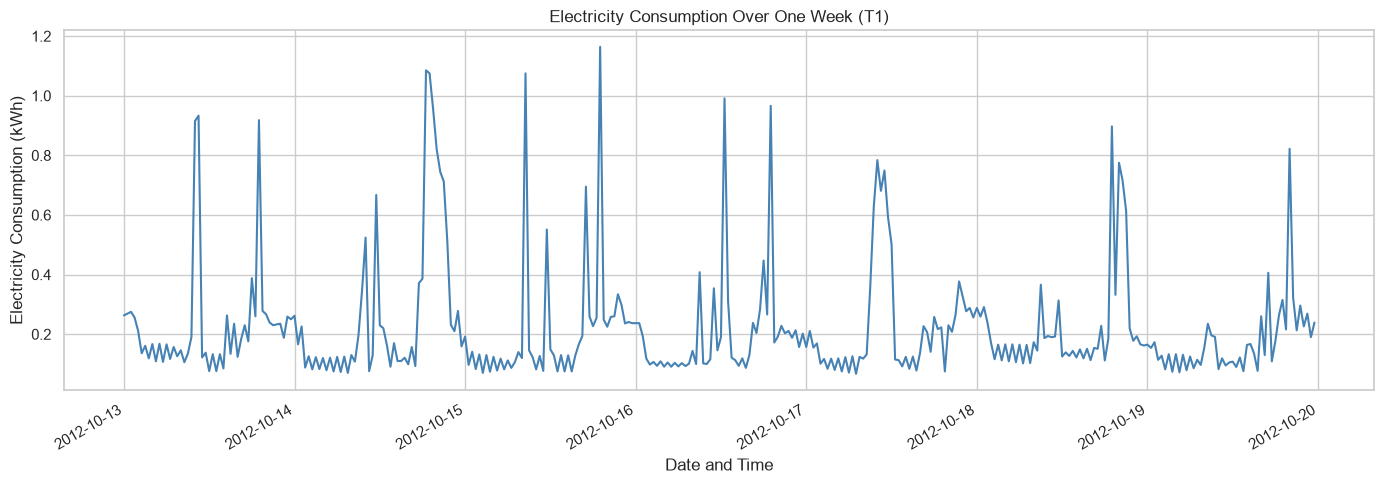

In [18]:
# Plot electricity consumption for the first 7 days
plt.figure(figsize=(14, 5))

meter_df["consumption_kwh"].iloc[:336].plot(
    color="steelblue"
)

plt.title(f"Electricity Consumption Over One Week ({selected_meter})")
plt.xlabel("Date and Time")
plt.ylabel("Electricity Consumption (kWh)")

plt.grid(True)
plt.tight_layout()
plt.show()

The graph illustrates electricity consumption for Meter T1 over a seven-day period, from October 13 to October 20, 2012. Consumption fluctuates considerably throughout the week, with several sharp peaks reaching approximately 1.16 kWh per 30-minute interval. Between these peaks, consumption generally remains between 0.1 and 0.3 kWh. These fluctuations suggest periods of relatively consistent baseline electricity usage interrupted by short periods of significantly higher demand. This variability is important for forecasting, as models must account for both regular consumption patterns and sudden increases in electricity demand.

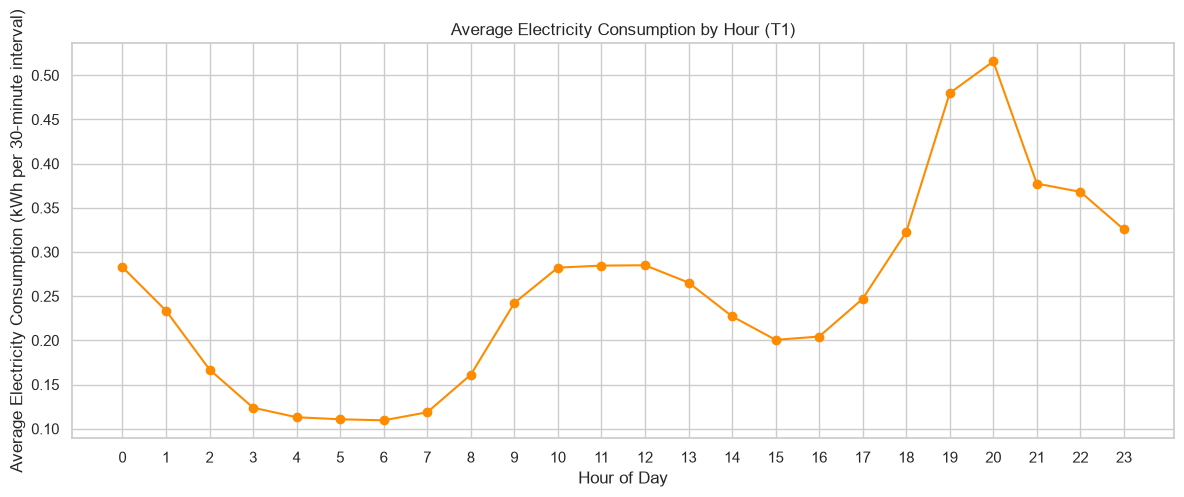

In [19]:
# Create an hour-of-day column
meter_df["hour"] = meter_df.index.hour

# Calculate average consumption for each hour
hourly_average = meter_df.groupby("hour")["consumption_kwh"].mean()

# Plot average consumption by hour
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_average.index,
    hourly_average.values,
    marker="o",
    color="darkorange"
)

plt.title(f"Average Electricity Consumption by Hour ({selected_meter})")
plt.xlabel("Hour of Day")
plt.ylabel("Average Electricity Consumption (kWh per 30-minute interval)")

plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()

The graph demonstrates a clear relationship between electricity consumption and the time of day. Consumption is lowest during the early morning, particularly between 3:00 AM and 6:00 AM, averaging approximately 0.11 kWh per 30-minute interval. Demand gradually increases throughout the morning before reaching its highest levels in the evening, with a peak of approximately 0.51 kWh around 8:00 PM. This pattern suggests that electricity consumption follows a daily cycle, potentially influenced by household occupancy and activities. These recurring patterns indicate that historical consumption and time-of-day information may be useful features for forecasting future electricity demand.

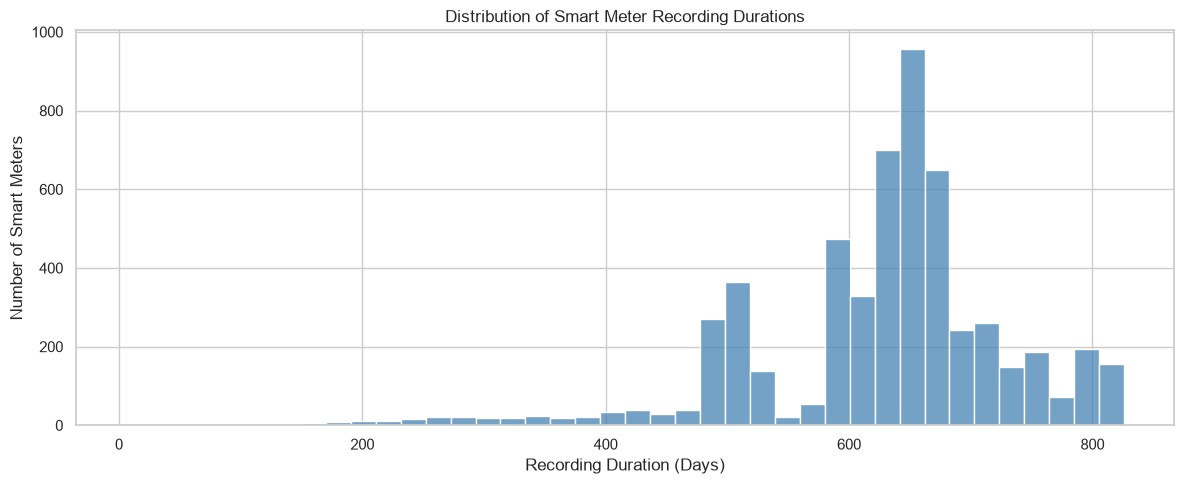

In [20]:
plt.figure(figsize=(12, 5))

sns.histplot(
    df["duration_days"],
    bins=40,
    color="steelblue"
)

plt.title("Distribution of Smart Meter Recording Durations")
plt.xlabel("Recording Duration (Days)")
plt.ylabel("Number of Smart Meters")

plt.tight_layout()
plt.show()

The histogram illustrates the variation in recording durations across the 5,560 smart meters. Most meters have recording periods concentrated between approximately 600 and 700 days, with the highest frequency occurring around 650 to 670 days. However, the dataset also contains shorter recording periods, with durations ranging from approximately 6 to 826 days. This variation indicates that the smart meters do not all cover the same time period. When preparing data for forecasting, differences in recording duration must be considered to ensure that sufficient historical observations are available and that the selected time series is suitable for model training and evaluation.

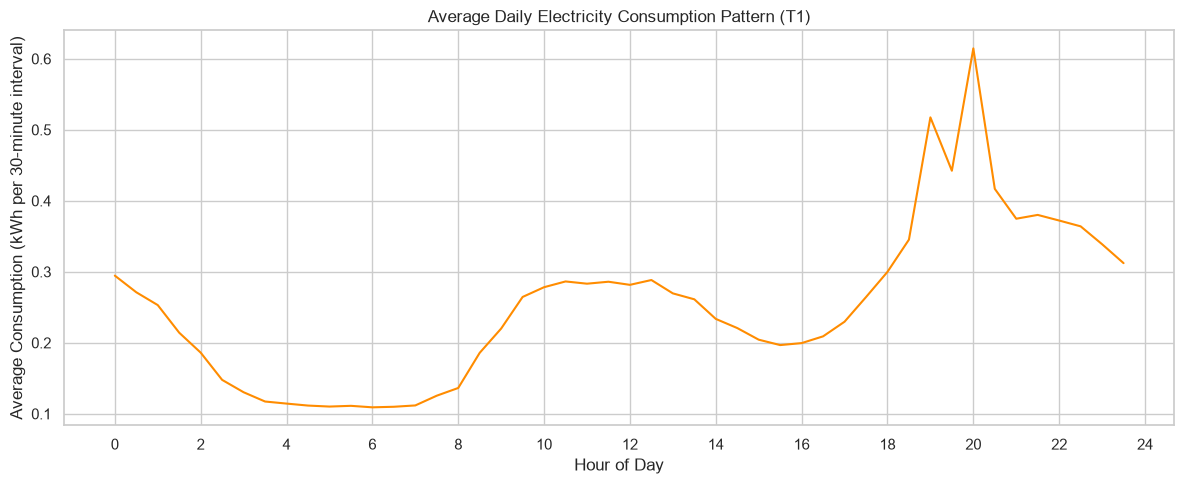

In [21]:
# Create half-hour time-of-day intervals
meter_df["time_of_day"] = (
    meter_df.index.hour * 2
    + meter_df.index.minute // 30
)

# Average consumption for each interval
daily_pattern = meter_df.groupby(
    "time_of_day"
)["consumption_kwh"].mean()

plt.figure(figsize=(12, 5))

plt.plot(
    daily_pattern.index / 2,
    daily_pattern.values,
    color="darkorange"
)

plt.title(f"Average Daily Electricity Consumption Pattern ({selected_meter})")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption (kWh per 30-minute interval)")
plt.xticks(range(0, 25, 2))

plt.grid(True)
plt.tight_layout()
plt.show()

The graph presents the average daily electricity consumption pattern for Meter T1 using 30-minute intervals. Consumption is lowest during the early morning, reaching approximately 0.11 kWh between 4:00 AM and 7:00 AM. Demand increases throughout the morning and remains relatively stable around midday before rising significantly in the evening. The highest average consumption occurs around 8:00 PM, reaching approximately 0.61 kWh per 30-minute interval. The distinct morning and evening patterns suggest that electricity consumption exhibits daily seasonality, which could be useful for time-series forecasting. Modelling will use hourly totals (Section 2), which smooths short-term noise while keeping the daily cycle visible.

In [22]:
# Create final cleaned dataset for modelling
clean_df = meter_df[["consumption_kwh"]].copy()

# Ensure timestamps are chronological
clean_df = clean_df.sort_index()

# Remove duplicate timestamps if any exist
# Do not silently delete them; verify first
assert not clean_df.index.has_duplicates, "Duplicate timestamps found"

# Verify no missing consumption values
assert clean_df["consumption_kwh"].notna().all(), "Missing values found"

# Verify nonnegative electricity consumption
assert (clean_df["consumption_kwh"] >= 0).all(), "Negative values found"

# Display cleaned dataset
print("Selected meter:", selected_meter)
print("Dataset shape:", clean_df.shape)
print("Start date:", clean_df.index.min())
print("End date:", clean_df.index.max())

display(clean_df.head())

Selected meter: T1
Dataset shape: (23904, 1)
Start date: 2012-10-13 00:00:01
End date: 2014-02-22 23:30:01


,consumption_kwh
timestamp,
2012-10-13 00:00:01,0.263
2012-10-13 00:30:01,0.269
2012-10-13 01:00:01,0.275
2012-10-13 01:30:01,0.256
2012-10-13 02:00:01,0.211


### Preprocessing Decisions and Modelling Handoff

The dataset was inspected for missing observations, duplicate meter identifiers, negative consumption values and variations in recording duration. No missing numerical observations, duplicate meter identifiers or negative consumption values were identified. Zero-consumption observations were retained because they cannot automatically be classified as invalid.

Individual timestamps were reconstructed using the recorded starting timestamps and the native 30-minute sampling interval. No resampling was performed in this section; the 30-minute data is aggregated to hourly totals in Section 2.

Following exploratory analysis, a forecasting series was selected for further modelling. The selected series was organized chronologically into a DataFrame containing timestamps and electricity consumption in kWh.

No normalization or train/validation/test splitting was performed during this stage. These operations will be completed in the subsequent modelling pipeline, with any fitted preprocessing transformations based exclusively on training data.

### Chronological Data Splitting and Preprocessing

The selected household's electricity consumption data is prepared for time-series forecasting using a chronological train/validation/test split.

The original 30-minute observations are aggregated into hourly intervals. Each model will use the previous 168 hours (7 days) to predict the following 24 hours.

The dataset is divided chronologically into:
- **Training (60%):** Used to fit preprocessing transformations and train models.
- **Validation (20%):** Used for hyperparameter tuning and model selection.
- **Testing (20%):** Reserved for final model evaluation.

The chronological order is preserved to prevent future observations from influencing earlier predictions. All fitted preprocessing transformations use training data only.

In [23]:
# Stage 1: Chronological Data Splitting and Preprocessing

# Define forecasting parameters
LOOKBACK = 168       # Previous 168 hours (7 days)
HORIZON = 24         # Predict the next 24 hours
SEED = 42

# Convert 30-minute consumption measurements to hourly consumption
hourly_df = clean_df.resample("1h").sum(min_count=2)

# Display dataset information
print("Original dataset shape:", clean_df.shape)
print("Hourly dataset shape:", hourly_df.shape)

print("\nHourly dataset coverage:")
print("Start:", hourly_df.index.min())
print("End:", hourly_df.index.max())

print("\nMissing hourly observations:")
print(hourly_df.isna().sum())

display(hourly_df.head())

Original dataset shape: (23904, 1)
Hourly dataset shape: (11952, 1)

Hourly dataset coverage:
Start: 2012-10-13 00:00:00
End: 2014-02-22 23:00:00

Missing hourly observations:
consumption_kwh    0
dtype: int64


,consumption_kwh
timestamp,
2012-10-13 00:00:00,0.532
2012-10-13 01:00:00,0.531
2012-10-13 02:00:00,0.347
2012-10-13 03:00:00,0.280
2012-10-13 04:00:00,0.276


In [24]:
# Step 2A: Chronological 60/20/20 split

# Calculate split indices
n = len(hourly_df)

train_end = int(n * 0.60)
val_end = int(n * 0.80)

# Split chronologically (no shuffling)
train_df = hourly_df.iloc[:train_end].copy()
val_df = hourly_df.iloc[train_end:val_end].copy()
test_df = hourly_df.iloc[val_end:].copy()

# Display split information
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Observations": [len(train_df), len(val_df), len(test_df)],
    "Start": [
        train_df.index.min(),
        val_df.index.min(),
        test_df.index.min()
    ],
    "End": [
        train_df.index.max(),
        val_df.index.max(),
        test_df.index.max()
    ]
})

display(split_summary)

# Confirm chronological ordering
assert train_df.index.max() < val_df.index.min()
assert val_df.index.max() < test_df.index.min()

,Dataset,Observations,Start,End
0,Training,7171,2012-10-13 00:00:00,2013-08-07 18:00:00
1,Validation,2390,2013-08-07 19:00:00,2013-11-15 08:00:00
2,Testing,2391,2013-11-15 09:00:00,2014-02-22 23:00:00


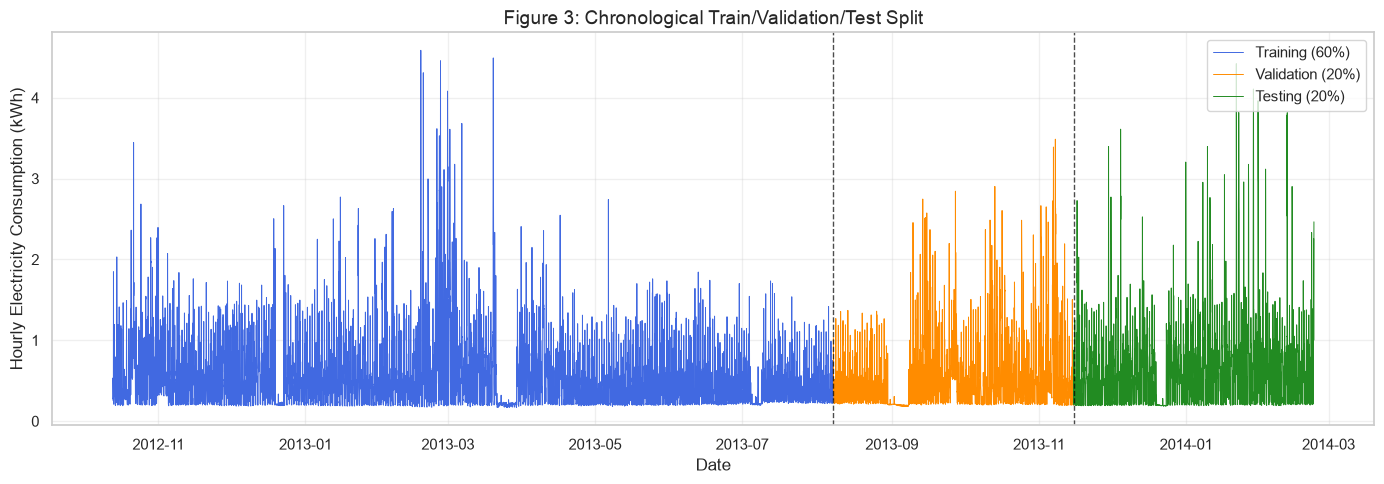

In [25]:
# Step 2B: Visualize chronological train/validation/test split

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(14, 5))

# Plot each dataset partition
ax.plot(
    train_df.index,
    train_df["consumption_kwh"],
    label="Training (60%)",
    color="royalblue",
    linewidth=0.7
)

ax.plot(
    val_df.index,
    val_df["consumption_kwh"],
    label="Validation (20%)",
    color="darkorange",
    linewidth=0.7
)

ax.plot(
    test_df.index,
    test_df["consumption_kwh"],
    label="Testing (20%)",
    color="forestgreen",
    linewidth=0.7
)

# Mark split boundaries
ax.axvline(
    train_df.index[-1],
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.7
)

ax.axvline(
    val_df.index[-1],
    color="black",
    linestyle="--",
    linewidth=1,
    alpha=0.7
)

# Labels and formatting
ax.set_title(
    "Figure 3: Chronological Train/Validation/Test Split",
    fontsize=14
)

ax.set_xlabel("Date")
ax.set_ylabel("Hourly Electricity Consumption (kWh)")
ax.legend(loc="upper right")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Why are we splitting chronologically?
Unlike regular machine learning datasets, time-series observations have a meaningful order.

We want to simulate forecasting future electricity consumption using only information that would have been available at the time.

For example:
- Training: Older electricity consumption measurements.
- Validation: More recent measurements used to select the best model.
- Testing: The newest measurements used to evaluate performance.
Randomly shuffling observations could introduce information from the future into training.

### Step 2C: Outlier-day analysis (cleaning tested, then disabled)

**Question:** a single household has occasional days that look nothing like normal use. Do these "outlier days" hurt the models, and should they be cleaned out of the training data?

**Detection method** (training period only):
1. Use only **complete days** (24 hourly readings) in the training period.
2. For each day compute the **daily total** and the **daily peak** (highest hourly reading).
3. Score each day with a **robust z-score** based on the median and median absolute deviation (MAD):

$$z_d = 0.6745 \cdot \frac{x_d - \operatorname{median}(x)}{\operatorname{MAD}(x)}$$

4. Flag a day if its total has $|z| > 3.5$ or its peak has $z > 3.5$ (the standard cut-off for this score, Iglewicz and Hoaglin).

**Finding:** most flagged days are **not isolated errors**. 12 of the 19 flagged days fall between 17 February and 19 March 2013, a sustained period of high consumption lasting several weeks (most likely cold weather). The detector flags them because it compares each day with the median of the whole training year, which is dominated by lower spring and summer use.

**Cleaning was tested and made results worse.** In a trial run, every flagged day was replaced with the typical profile for its weekday (median per weekday and hour over normal training days). Compared with the same notebook without cleaning:
- validation RMSE got worse for **all seven** models (for example RNN 0.3610 → 0.3752 kWh, LSTM 0.3622 → 0.3720 kWh);
- test RMSE got worse for the sequence models (RNN 0.3989 → 0.4297 kWh) and only slightly better for the MLP and CNN.

Removing a real high-consumption period leaves the models with less evidence of how this household behaves in a cold spell, which is exactly what the winter test period contains.

**Decision:** the replacement step is **switched off** (`APPLY_OUTLIER_CLEANING = False`), so every model trains on the real readings. A version that compares each day with its local level (for example the surrounding four weeks) would keep the cold-weather period, but it would only flag a handful of isolated days, too few to change the fitted models beyond run-to-run noise, and those spikes are genuine behaviour that also appears in the validation and test periods. The detection is kept because it identifies the main data risk: the training set contains **only one** sustained high-consumption spell, while the test period is mostly winter.

Validation and test data are never changed by this step.

In [26]:
# Step 2C: detect outlier days in the TRAINING period only (replacement switched off, see markdown above)
from IPython.display import Markdown

train_df_raw = train_df.copy()   # keep the original training data for comparison

# 1. Daily total and peak for complete days only
day_index = train_df_raw.index.normalize()
hours_per_day = train_df_raw.groupby(day_index)["consumption_kwh"].count()
full_days = hours_per_day[hours_per_day == 24].index
daily = train_df_raw.groupby(day_index)["consumption_kwh"].agg(total="sum", peak="max").loc[full_days]

# 2. Robust z-scores (median / MAD), training days only
def robust_z(s):
    med = s.median()
    mad = (s - med).abs().median()
    if mad == 0:
        return pd.Series(0.0, index=s.index)
    return 0.6745 * (s - med) / mad

Z_THRESHOLD = 3.5
daily["z_total"] = robust_z(daily["total"])
daily["z_peak"] = robust_z(daily["peak"])

# 3. Flag outlier days and record why
daily["reason"] = ""
daily.loc[daily["z_total"] > Z_THRESHOLD, "reason"] += "high daily total; "
daily.loc[daily["z_total"] < -Z_THRESHOLD, "reason"] += "low daily total; "
daily.loc[daily["z_peak"] > Z_THRESHOLD, "reason"] += "extreme hourly peak; "
daily["reason"] = daily["reason"].str.rstrip("; ")
outlier_days = daily[daily["reason"] != ""].copy()
is_outlier_hour = day_index.isin(outlier_days.index)

# 4. Replacement is switched OFF: a trial run showed it removed a real cold-weather period and made results worse
APPLY_OUTLIER_CLEANING = False

train_df = train_df_raw.copy()
if APPLY_OUTLIER_CLEANING:
    # Typical profile: median kWh per (weekday, hour) over the non-flagged training days
    normal = train_df_raw[~is_outlier_hour]
    profile = normal.groupby([normal.index.dayofweek, normal.index.hour])["consumption_kwh"].median()
    replace_idx = train_df.index[is_outlier_hour]
    train_df.loc[replace_idx, "consumption_kwh"] = profile.loc[list(zip(replace_idx.dayofweek, replace_idx.hour))].values
assert train_df.index.equals(train_df_raw.index) and train_df["consumption_kwh"].notna().all()

# Report: flagged days
flag_table = outlier_days.assign(weekday=outlier_days.index.day_name())[["weekday", "total", "peak", "z_total", "z_peak", "reason"]]
flag_table.index.name = "date"
print(f"Flagged outlier days in the training period: {len(outlier_days)} of {len(daily)} complete days "
      f"({100 * len(outlier_days) / len(daily):.1f}%)")
display(flag_table.round(3))

# Report: clustering of flagged days (isolated errors vs a sustained period)
gaps = outlier_days.index.to_series().diff().dt.days
runs = (gaps != 1).cumsum()
print(f"Flagged days fall into {runs.nunique()} separate runs of consecutive days.")
print("Outlier-day replacement applied:", APPLY_OUTLIER_CLEANING, "| training data used for modelling:",
      "cleaned" if APPLY_OUTLIER_CLEANING else "original readings")


Flagged outlier days in the training period: 19 of 298 complete days (6.4%)


,weekday,total,peak,z_total,z_peak,reason
date,,,,,,
2012-10-21,Sunday,24.490,3.445,5.663,5.789,high daily total; extreme hourly peak
2012-10-24,Wednesday,15.537,2.685,1.960,3.635,extreme hourly peak
2012-10-28,Sunday,19.629,2.269,3.652,2.456,high daily total
2012-12-22,Saturday,7.650,2.666,-1.303,3.581,extreme hourly peak
2013-01-15,Tuesday,15.742,2.772,2.044,3.881,extreme hourly peak
2013-02-17,Sunday,20.696,4.586,4.094,9.022,high daily total; extreme hourly peak
2013-02-18,Monday,24.018,4.309,5.468,8.237,high daily total; extreme hourly peak
2013-02-20,Wednesday,19.751,2.996,3.703,4.516,high daily total; extreme hourly peak
2013-02-24,Sunday,32.628,3.617,9.030,6.276,high daily total; extreme hourly peak


Flagged days fall into 13 separate runs of consecutive days.
Outlier-day replacement applied: False | training data used for modelling: original readings


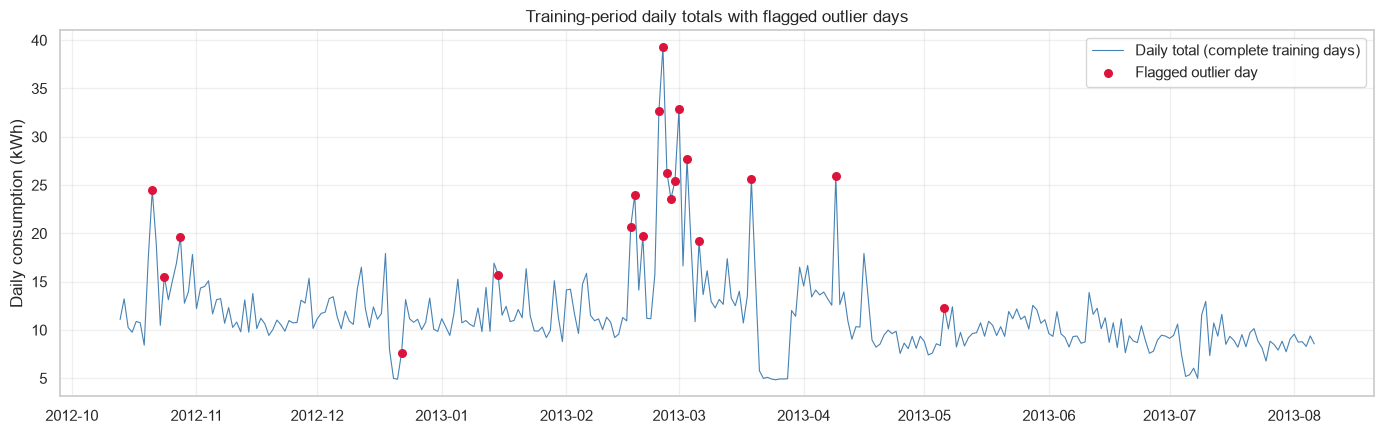

**Outlier-day analysis.** 19 of 298 complete training days (6.4%) were flagged. Reasons (a day can have more than one): extreme hourly peak (17), high daily total (14). 12 of them fall within five weeks of 17 February 2013, which points to a sustained high-consumption period rather than isolated errors. Replacement is switched off, so all models train on the original readings. Validation and test data are unchanged.

In [27]:
# Figures: which days were flagged, and what the training series looks like before and after cleaning
fig, axes = plt.subplots(2 if APPLY_OUTLIER_CLEANING else 1, 1, figsize=(14, 8 if APPLY_OUTLIER_CLEANING else 4.5))
axes = np.atleast_1d(axes)

axes[0].plot(daily.index, daily["total"], color="steelblue", linewidth=0.8, label="Daily total (complete training days)")
axes[0].scatter(outlier_days.index, outlier_days["total"], color="crimson", zorder=3, s=30, label="Flagged outlier day")
axes[0].set_title("Training-period daily totals with flagged outlier days")
axes[0].set_ylabel("Daily consumption (kWh)")
axes[0].legend(loc="upper right"); axes[0].grid(alpha=0.3)

if APPLY_OUTLIER_CLEANING:
    axes[1].plot(train_df_raw.index, train_df_raw["consumption_kwh"], color="lightgray", linewidth=0.7, label="Before cleaning")
    axes[1].plot(train_df.index, train_df["consumption_kwh"], color="royalblue", linewidth=0.7, label="After cleaning")
    axes[1].set_title("Hourly training series before and after outlier-day cleaning")
    axes[1].set_xlabel("Date"); axes[1].set_ylabel("Hourly consumption (kWh)")
    axes[1].legend(loc="upper right"); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

# Written summary generated from the results above, so the text always matches this run
reason_counts = outlier_days["reason"].str.split("; ").explode().value_counts()
reason_text = ", ".join(f"{r} ({n})" for r, n in reason_counts.items()) if len(outlier_days) else "none"
# Busiest 5-week window: many flagged days close together means a sustained period, not isolated errors
flag_dates = outlier_days.index.sort_values()
window_counts = [((flag_dates >= d) & (flag_dates <= d + pd.Timedelta(days=34))).sum() for d in flag_dates]
busiest_count = int(max(window_counts)) if len(flag_dates) else 0
busiest_start = flag_dates[int(np.argmax(window_counts))] if len(flag_dates) else None
display(Markdown(
    f"**Outlier-day analysis.** {len(outlier_days)} of {len(daily)} complete training days "
    f"({100 * len(outlier_days) / len(daily):.1f}%) were flagged. Reasons (a day can have more than one): {reason_text}. "
    + (f"{busiest_count} of them fall within five weeks of {busiest_start:%d %B %Y}, which points to a sustained "
       f"high-consumption period rather than isolated errors. " if busiest_count >= len(outlier_days) / 2 else
       f"They are spread out (at most {busiest_count} within any five-week window), consistent with isolated unusual days. ")
    + ("The flagged days were replaced with the typical weekday profile in the training data."
       if APPLY_OUTLIER_CLEANING else
       "Replacement is switched off, so all models train on the original readings. Validation and test data are unchanged.")
))


In [28]:
# Step 3: Missing-value imputation and scaling

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Initialize preprocessing tools
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

# Fit preprocessing tools on training data only
train_imputed = imputer.fit_transform(train_df)

val_imputed = imputer.transform(val_df)
test_imputed = imputer.transform(test_df)

# Fit scaler on imputed training data only
train_scaled = scaler.fit_transform(train_imputed).ravel()

val_scaled = scaler.transform(val_imputed).ravel()
test_scaled = scaler.transform(test_imputed).ravel()

print("Training shape:", train_scaled.shape)
print("Validation shape:", val_scaled.shape)
print("Testing shape:", test_scaled.shape)

print("\nTraining mean:", scaler.mean_[0])
print("Training standard deviation:", scaler.scale_[0])

Training shape: (7171,)
Validation shape: (2390,)
Testing shape: (2391,)

Training mean: 0.48505368859294384
Training standard deviation: 0.41826104062933156


In [29]:
# Step 4A: Create forecasting windows

def make_windows(series, lookback=168, horizon=24):
    X, y = [], []

    for i in range(len(series) - lookback - horizon + 1):
        X.append(series[i:i + lookback])
        y.append(series[i + lookback:i + lookback + horizon])

    return np.array(X), np.array(y)

In [30]:
# Step 4B: Create training, validation, and test windows

# Training windows
X_train, y_train = make_windows(
    train_scaled, LOOKBACK, HORIZON
)

# Validation windows:
# Include historical training observations for context
val_context = np.concatenate([
    train_scaled[-LOOKBACK:],
    val_scaled
])

X_val, y_val = make_windows(
    val_context, LOOKBACK, HORIZON
)

# Testing windows:
# Include historical validation observations for context
test_context = np.concatenate([
    val_scaled[-LOOKBACK:],
    test_scaled
])

X_test, y_test = make_windows(
    test_context, LOOKBACK, HORIZON
)

# Display window shapes
print("Training:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nValidation:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nTesting:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# Verify input and output dimensions
assert X_train.shape[1] == LOOKBACK
assert y_train.shape[1] == HORIZON
assert X_val.shape[1] == LOOKBACK
assert y_val.shape[1] == HORIZON
assert X_test.shape[1] == LOOKBACK
assert y_test.shape[1] == HORIZON

Training:
X_train: (6980, 168)
y_train: (6980, 24)

Validation:
X_val: (2367, 168)
y_val: (2367, 24)

Testing:
X_test: (2368, 168)
y_test: (2368, 24)


# Section 3 - Shared Training Framework and Baseline Models

This section establishes the shared evaluation metrics and training framework used throughout the project. It also introduces traditional forecasting baselines, including Persistence and Seasonal Naive, which provide reference points for evaluating the performance of the deep learning models.

In [31]:
# Step 5A: Traditional forecasting baselines

# Persistence baseline:
# Repeat the last observed value for all 24 forecast hours
def persistence_baseline(X, horizon=24):
    return np.repeat(
        X[:, -1:],
        horizon,
        axis=1
    )


# Seasonal naive baseline:
# Repeat the previous 24 hours
def seasonal_naive_baseline(X, horizon=24):
    return X[:, -horizon:].copy()


# Generate validation predictions
val_pred_persistence = persistence_baseline(
    X_val, HORIZON
)

val_pred_seasonal = seasonal_naive_baseline(
    X_val, HORIZON
)

# Check prediction shapes
print("Persistence:", val_pred_persistence.shape)
print("Seasonal naive:", val_pred_seasonal.shape)
print("Actual:", y_val.shape)

Persistence: (2367, 24)
Seasonal naive: (2367, 24)
Actual: (2367, 24)


In [32]:
# Step 5B: Evaluation metrics

from sklearn.metrics import mean_absolute_error, mean_squared_error

def inverse_scale(values):
    original_shape = values.shape

    return scaler.inverse_transform(
        values.reshape(-1, 1)
    ).reshape(original_shape)


def evaluate_forecast(y_true, y_pred):

    # Convert back to original kWh units
    actual = inverse_scale(y_true)
    predicted = inverse_scale(y_pred)

    mae = mean_absolute_error(
        actual.ravel(),
        predicted.ravel()
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual.ravel(),
            predicted.ravel()
        )
    )

    # Symmetric Mean Absolute Percentage Error
    denominator = np.abs(actual) + np.abs(predicted)

    smape = 200 * np.mean(
        np.divide(
            np.abs(actual - predicted),
            denominator,
            out=np.zeros_like(actual, dtype=float),
            where=denominator != 0
        )
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "sMAPE (%)": smape
    }


# Evaluate on validation data
persistence_metrics = evaluate_forecast(
    y_val, val_pred_persistence
)

seasonal_metrics = evaluate_forecast(
    y_val, val_pred_seasonal
)

baseline_results = pd.DataFrame([
    {
        "Model": "Persistence",
        **persistence_metrics
    },
    {
        "Model": "Seasonal Naive",
        **seasonal_metrics
    }
])

display(baseline_results)

,Model,MAE,RMSE,sMAPE (%)
0,Persistence,0.336427,0.566006,52.298721
1,Seasonal Naive,0.243710,0.461939,36.135168


In [33]:
# Step 5C: Select the best baseline using validation RMSE

best_baseline = baseline_results.loc[
    baseline_results["RMSE"].idxmin()
]

best_baseline_name = best_baseline["Model"]
best_baseline_rmse = best_baseline["RMSE"]

print("Best baseline:", best_baseline_name)
print("Validation RMSE:", best_baseline_rmse)

Best baseline: Seasonal Naive
Validation RMSE: 0.4619391201624515


**Design rules for this section**
- Every neural model uses the **same windows, horizon, loss (MSE on scaled data), seed, optimiser settings and early-stopping rule**. The shared training loop is `train_model(...)` below and is reused by the CNN grid search.
- Model selection (early stopping, best baseline, best neural model) uses **validation data only**.
- Models are added to `registry` with `register(...)`. The comparison table and the single test evaluation are in **Section 10** (end of notebook), so no section needs to edit another.

Helper function to add models to the shared registry:


* name: the label that shows up in the final table, like "CNN".
* predict_fn: a function that takes input windows and returns forecasts
* params, train_time_s: the number of parameters and how long training took, for the table.
* kind: "neural" or "baseline".
* cfg: the settings used, kept for the record.

In [34]:
registry = {}   # name -> dict(kind, predict_fn, params, train_time_s, cfg)

def register(name, predict_fn, params=0, train_time_s=0.0, kind="neural", cfg=None):
    """predict_fn: numpy (N, 168) scaled -> numpy (N, 24) scaled."""
    registry[name] = dict(kind=kind, predict_fn=predict_fn, params=int(params),
                          train_time_s=float(train_time_s), cfg=cfg)
    print(f"Registered: {name} ({kind}, {int(params):,} params)")

MLP training setup:
* Loss: MSE on scaled data
* Optimiser: Adam
* Fixed seed
* Early stopping on validation loss with best-weights restore

In [35]:
import os, time, random
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__, "| seed", SEED)

# Windows as float32 tensors (inputs are already scaled with the training-only scaler)
Xtr, ytr = torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)
Xva, yva = torch.tensor(X_val,   dtype=torch.float32), torch.tensor(y_val,   dtype=torch.float32)
print("Tensors:", tuple(Xtr.shape), tuple(Xva.shape))

def make_mlp(cfg):
    """Fully connected network: 168 -> hidden layers -> 24."""
    layers, d = [], LOOKBACK
    for h in cfg["hidden"]:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(cfg["dropout"])]
        d = h
    layers.append(nn.Linear(d, HORIZON))
    return nn.Sequential(*layers)

def train_model(model, cfg, verbose=True):
    """Shared training loop for ALL neural models (MLP, CNN, ...).
    MSE loss, Adam, early stopping on VALIDATION loss, best weights restored.
    Returns: model, history, best_epoch (1-based), training time in seconds."""
    set_seed(cfg["seed"])
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    loss_fn = nn.MSELoss()
    g = torch.Generator().manual_seed(cfg["seed"])
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=cfg["batch_size"], shuffle=True, generator=g)
    best_val, best_state, best_epoch, wait = float("inf"), None, 0, 0
    hist = {"train": [], "val": []}
    t0 = time.perf_counter()
    for epoch in range(1, cfg["max_epochs"] + 1):
        model.train()
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()

        model.eval()

        def evaluate_loss(X, y):
            eval_loader = DataLoader(
                TensorDataset(X, y),
                batch_size=cfg["batch_size"],
                shuffle=False
            )

            total_loss = 0.0
            total_samples = 0

            with torch.no_grad():
                for xb, yb in eval_loader:
                    xb = xb.to(device)
                    yb = yb.to(device)

                    loss = loss_fn(model(xb), yb)

                    total_loss += loss.item() * len(xb)
                    total_samples += len(xb)

            return total_loss / total_samples

        tr = evaluate_loss(Xtr, ytr)
        va = evaluate_loss(Xva, yva)

        hist["train"].append(tr); hist["val"].append(va)
        if va < best_val - 1e-6:
            best_val, best_epoch, wait = va, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= cfg["patience"]:
                break
        if verbose and (epoch == 1 or epoch % 10 == 0):
            print(f"epoch {epoch:3d} | train {tr:.4f} | val {va:.4f}")
    model.load_state_dict(best_state)
    return model, hist, best_epoch, time.perf_counter() - t0

Device: cpu | torch 2.15.0 | seed 42
Tensors: (6980, 168) (2367, 168)


# Section 4 - Multilayer Perceptron (MLP)

This section introduces the Multilayer Perceptron (MLP) as the first deep learning forecasting model. Its performance is evaluated using the shared training framework, providing a reference point for comparing more complex neural network architectures in subsequent sections.

In [36]:
mlp_cfg = dict(hidden=[128, 64], dropout=0.1, lr=1e-3, weight_decay=1e-5,
               batch_size=64, max_epochs=100, patience=10, seed=SEED)

set_seed(SEED)
mlp_model, mlp_hist, mlp_best_epoch, mlp_train_time = train_model(make_mlp(mlp_cfg), mlp_cfg)
mlp_params = sum(p.numel() for p in mlp_model.parameters() if p.requires_grad)
print(f"Best epoch {mlp_best_epoch}/{len(mlp_hist['val'])}, params {mlp_params:,}, train time {mlp_train_time:.1f}s")

epoch   1 | train 0.6709 | val 0.7809
epoch  10 | train 0.4931 | val 0.7990
Best epoch 2/12, params 31,448, train time 1.2s


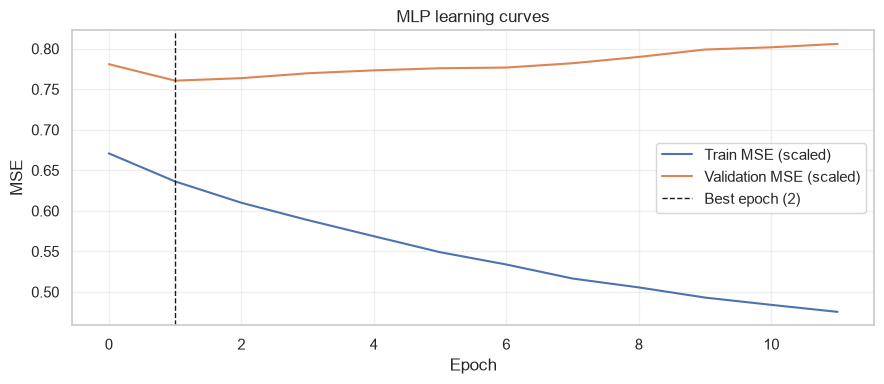

At best epoch: train 0.6363 | val 0.7606 | val/train 1.20
At last epoch: train 0.4754 | val 0.8060
Validation loss rose after the best epoch (overfitting began; best weights restored).


In [37]:
# Learning curves and overfitting check
plt.figure(figsize=(9, 4))
plt.plot(mlp_hist["train"], label="Train MSE (scaled)")
plt.plot(mlp_hist["val"], label="Validation MSE (scaled)")
plt.axvline(mlp_best_epoch - 1, color="k", ls="--", lw=1, label=f"Best epoch ({mlp_best_epoch})")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("MLP learning curves")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

b = mlp_best_epoch - 1
print(f"At best epoch: train {mlp_hist['train'][b]:.4f} | val {mlp_hist['val'][b]:.4f} | val/train {mlp_hist['val'][b]/mlp_hist['train'][b]:.2f}")
print(f"At last epoch: train {mlp_hist['train'][-1]:.4f} | val {mlp_hist['val'][-1]:.4f}")
print("Validation loss rose after the best epoch (overfitting began; best weights restored)."
      if mlp_hist["val"][-1] > 1.05 * mlp_hist["val"][b] else "No clear overfitting after the best epoch.")

Checkpoint, register, and smoke test:

In [38]:
# Save the trained MLP so it survives a restart without retraining
os.makedirs("artifacts", exist_ok=True)
torch.save({"state_dict": mlp_model.state_dict(), "cfg": mlp_cfg}, "artifacts/mlp_baseline.pt")

# Prediction function - numpy (N, 168) scaled -> numpy (N, 24) scaled
def mlp_predict(X, model=mlp_model):
    model.eval() # dropout off
    with torch.no_grad(): # no gradients needed
        return model(torch.tensor(X, dtype=torch.float32).to(device)).cpu().numpy()

# Add the MLP to the shared registry for the comparison table (Section 10)
register("MLP", mlp_predict, params=mlp_params, train_time_s=mlp_train_time, cfg=mlp_cfg)

# Check for correct shape (8 windows x 24 hours) and no NaN/inf
_p = mlp_predict(X_val[:8])
assert _p.shape == (8, HORIZON) and np.isfinite(_p).all()
print("Smoke test passed:", _p.shape)

Registered: MLP (neural, 31,448 params)
Smoke test passed: (8, 24)


### MLP hyperparameter tuning (grid search, validation only)

The untuned MLP already beat the tuned CNN on validation, so the MLP is the model that gets tuned (course rule: tune the best model). The search space is fixed before running: hidden sizes, dropout, learning rate and weight decay, with stronger regularisation included because both models start overfitting within the first few epochs. Selection uses validation MSE only; the test set is not touched. The untuned MLP stays registered as `MLP` so the effect of tuning is visible in the final table.

In [39]:
import itertools

mlp_param_grid = {
    "hidden": [[64], [128, 64], [256, 128]],
    "dropout": [0.1, 0.3, 0.5],
    "lr": [1e-3, 3e-4],
    "weight_decay": [1e-5, 1e-3],
}
keys, values = zip(*mlp_param_grid.items())
mlp_grid = [dict(zip(keys, v)) for v in itertools.product(*values)]
print(f"Starting MLP grid search across {len(mlp_grid)} configurations (validation only)...")

mlp_grid_results = []
best_mlp_val = float("inf")

for i, params in enumerate(mlp_grid):
    cfg = {**params, "batch_size": 64, "max_epochs": 100, "patience": 10, "seed": SEED}
    set_seed(SEED)
    model = make_mlp(cfg)
    model, hist, best_ep, t_sec = train_model(model, cfg, verbose=False)
    val_loss = hist["val"][best_ep - 1]
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    mlp_grid_results.append({"trial": i + 1, "config": params, "val_loss": val_loss,
                             "best_epoch": best_ep, "train_time_s": t_sec, "params": n_params})
    if val_loss < best_mlp_val:
        best_mlp_val, best_mlp_cfg, best_mlp_model = val_loss, cfg, model
        best_mlp_hist, best_mlp_epoch, best_mlp_time = hist, best_ep, t_sec

print(f"Best MLP config: {best_mlp_cfg}")
print(f"Best validation MSE: {best_mlp_val:.5f} (scaled RMSE {np.sqrt(best_mlp_val):.5f})")

Starting MLP grid search across 36 configurations (validation only)...
Best MLP config: {'hidden': [256, 128], 'dropout': 0.1, 'lr': 0.0003, 'weight_decay': 0.001, 'batch_size': 64, 'max_epochs': 100, 'patience': 10, 'seed': 42}
Best validation MSE: 0.75582 (scaled RMSE 0.86938)


Table 2: MLP grid search results (36 trials, sorted by validation MSE)


,hidden,dropout,lr,weight_decay,val_MSE,best_epoch,train_time_s,params
0,"[256, 128]",0.1,0.0003,0.00100,0.75582,7,2.1,79256
1,"[256, 128]",0.1,0.0010,0.00100,0.75646,2,1.5,79256
2,"[256, 128]",0.1,0.0003,0.00001,0.75696,7,2.3,79256
3,"[256, 128]",0.1,0.0010,0.00001,0.75776,2,1.7,79256
4,"[256, 128]",0.3,0.0003,0.00100,0.75807,7,2.6,79256
5,"[256, 128]",0.3,0.0003,0.00001,0.75851,7,2.2,79256
6,[64],0.3,0.0003,0.00100,0.75920,20,2.1,12376
7,"[128, 64]",0.1,0.0003,0.00100,0.75998,8,1.7,31448
8,[64],0.3,0.0003,0.00001,0.76043,17,1.9,12376
9,"[128, 64]",0.1,0.0010,0.00001,0.76060,2,1.1,31448


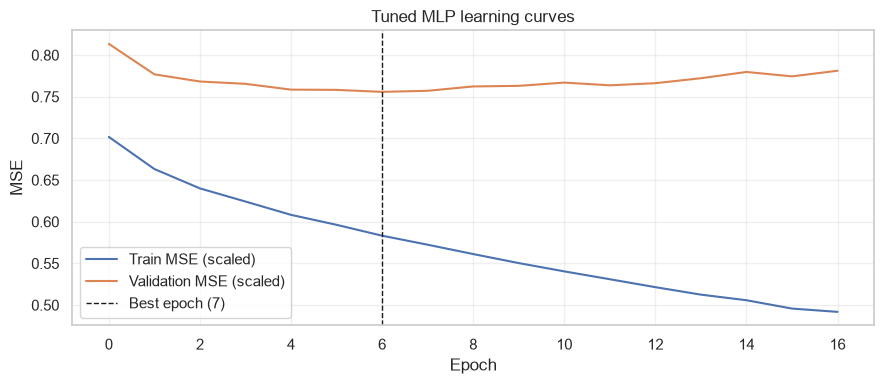

Registered: MLP (tuned) (neural, 79,256 params)
Smoke test passed: (8, 24)


In [40]:
# Table 2: MLP grid results (validation only), then register the tuned MLP
mlp_grid_df = pd.DataFrame([
    {**{k: (str(v) if k == "hidden" else v) for k, v in r["config"].items()},
     "val_MSE": r["val_loss"], "best_epoch": r["best_epoch"],
     "train_time_s": round(r["train_time_s"], 1), "params": r["params"]}
    for r in mlp_grid_results
]).sort_values("val_MSE").reset_index(drop=True)
print(f"Table 2: MLP grid search results ({len(mlp_grid_df)} trials, sorted by validation MSE)")
display(mlp_grid_df.round(5))

plt.figure(figsize=(9, 4))
plt.plot(best_mlp_hist["train"], label="Train MSE (scaled)")
plt.plot(best_mlp_hist["val"], label="Validation MSE (scaled)")
plt.axvline(best_mlp_epoch - 1, color="k", ls="--", lw=1, label=f"Best epoch ({best_mlp_epoch})")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Tuned MLP learning curves")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

os.makedirs("artifacts", exist_ok=True)
torch.save({"state_dict": best_mlp_model.state_dict(), "cfg": best_mlp_cfg}, "artifacts/mlp_tuned.pt")

def mlp_tuned_predict(X, model=best_mlp_model):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32).to(device)).cpu().numpy()

best_mlp_params = sum(p.numel() for p in best_mlp_model.parameters() if p.requires_grad)
register("MLP (tuned)", mlp_tuned_predict, params=best_mlp_params, train_time_s=best_mlp_time, cfg=best_mlp_cfg)

_p = mlp_tuned_predict(X_val[:8])
assert _p.shape == (8, HORIZON) and np.isfinite(_p).all()
print("Smoke test passed:", _p.shape)

# Section 5 - 1D Convolutional Neural Network (CNN)

This section implements a 1D Convolutional Neural Network (CNN) to capture local temporal patterns in electricity consumption. Hyperparameter tuning is performed using validation data, and the model's forecasting performance is evaluated against the MLP and traditional baselines.

### Architectural & Evaluation Contract:
- **1D Convolutional Architecture:** Convolutions over the temporal lookback axis ($L = 168$) to capture local temporal motifs and seasonal patterns before mapping to horizon $H = 24$.
- **Validation-Only Tuning:** Hyperparameters (kernel size, number of filters, dropout, learning rate) are selected solely using the validation set RMSE/MSE. The test set remains untouched.
- **Fair Protocol:** Uses the identical training protocol, loss function (MSE on scaled targets), seed, and early stopping mechanism defined in Section 2.



In [41]:
# 1D Convolutional Neural Network for Time Series Forecasting
import torch
import torch.nn as nn

class ConvNet1D(nn.Module):
    def __init__(self, in_features=168, out_features=24, num_filters=32, kernel_size=3, dropout=0.1):
        super(ConvNet1D, self).__init__()

        padding = kernel_size // 2  # Keep temporal dimension aligned

        self.conv_block = nn.Sequential(
            nn.Conv1d(in_channels=1, out_channels=num_filters, kernel_size=kernel_size, padding=padding),
            nn.ReLU(),
            nn.BatchNorm1d(num_filters),
            nn.Dropout(dropout),

            nn.Conv1d(in_channels=num_filters, out_channels=num_filters * 2, kernel_size=kernel_size, padding=padding),
            nn.ReLU(),
            nn.BatchNorm1d(num_filters * 2),
            nn.MaxPool1d(kernel_size=2),  # Shape: (batch_size, num_filters*2, in_features // 2)
            nn.Dropout(dropout)
        )

        flattened_dim = (num_filters * 2) * (in_features // 2)

        self.head = nn.Sequential(
            nn.Linear(flattened_dim, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, out_features)
        )

    def forward(self, x):
        # x input is (batch_size, 168)
        if x.dim() == 2:
            x = x.unsqueeze(1)  # Reshape to (batch_size, 1, 168) for Conv1d
        x = self.conv_block(x)
        x = x.flatten(start_dim=1)
        x = self.head(x)
        return x

def make_cnn(cfg):
    """Factory function for CNN instantiation."""
    return ConvNet1D(
        in_features=LOOKBACK,
        out_features=HORIZON,
        num_filters=cfg.get("num_filters", 32),
        kernel_size=cfg.get("kernel_size", 3),
        dropout=cfg.get("dropout", 0.1)
    )

In [42]:
# Grid Search on Validation Data Only
import itertools

# Define Hyperparameter Search Space
cnn_param_grid = {
    "num_filters": [16, 32],
    "kernel_size": [3, 5],
    "lr": [1e-3, 5e-4],
    "dropout": [0.1, 0.2]
}

# Generate all parameter combinations
keys, values = zip(*cnn_param_grid.items())
grid_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

print(f"Starting Grid Search across {len(grid_combinations)} hyperparameter configurations...")

grid_results = []
best_val_loss = float("inf")
best_cnn_cfg = None
best_cnn_model = None
best_cnn_hist = None
best_cnn_epoch = None
best_cnn_time = None

for i, params in enumerate(grid_combinations):
    cfg = {
        "num_filters": params["num_filters"],
        "kernel_size": params["kernel_size"],
        "dropout": params["dropout"],
        "lr": params["lr"],
        "weight_decay": 1e-5,
        "batch_size": 64,
        "max_epochs": 100,
        "patience": 10,
        "seed": SEED
    }

    set_seed(SEED)
    model = make_cnn(cfg)

    # Train with the shared training function (same loss, optimiser, early stopping)
    model, hist, best_ep, t_sec = train_model(model, cfg, verbose=False)  # shared loop from Section III
    val_loss = hist["val"][best_ep - 1]

    param_count = sum(p.numel() for p in model.parameters() if p.requires_grad)

    grid_results.append({
        "trial": i + 1,
        "config": params,
        "val_loss": val_loss,
        "best_epoch": best_ep,
        "train_time_s": t_sec,
        "params": param_count
    })

    print(f"Trial {i+1:02d}/{len(grid_combinations)} | Config: {params} | Val MSE: {val_loss:.5f} | Params: {param_count:,}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_cnn_cfg = cfg
        best_cnn_model = model
        best_cnn_hist = hist
        best_cnn_epoch = best_ep
        best_cnn_time = t_sec

print("\n" + "="*60)
print(f"Best CNN Config: {best_cnn_cfg}")
print(f"Best Validation MSE: {best_val_loss:.5f} (Validation RMSE: {np.sqrt(best_val_loss):.5f})")
print("="*60)

Starting Grid Search across 16 hyperparameter configurations...
Trial 01/16 | Config: {'num_filters': 16, 'kernel_size': 3, 'lr': 0.001, 'dropout': 0.1} | Val MSE: 0.82968 | Params: 175,384
Trial 02/16 | Config: {'num_filters': 16, 'kernel_size': 3, 'lr': 0.001, 'dropout': 0.2} | Val MSE: 0.81231 | Params: 175,384
Trial 03/16 | Config: {'num_filters': 16, 'kernel_size': 3, 'lr': 0.0005, 'dropout': 0.1} | Val MSE: 0.81184 | Params: 175,384
Trial 04/16 | Config: {'num_filters': 16, 'kernel_size': 3, 'lr': 0.0005, 'dropout': 0.2} | Val MSE: 0.80428 | Params: 175,384
Trial 05/16 | Config: {'num_filters': 16, 'kernel_size': 5, 'lr': 0.001, 'dropout': 0.1} | Val MSE: 0.81698 | Params: 176,440
Trial 06/16 | Config: {'num_filters': 16, 'kernel_size': 5, 'lr': 0.001, 'dropout': 0.2} | Val MSE: 0.80598 | Params: 176,440
Trial 07/16 | Config: {'num_filters': 16, 'kernel_size': 5, 'lr': 0.0005, 'dropout': 0.1} | Val MSE: 0.79556 | Params: 176,440
Trial 08/16 | Config: {'num_filters': 16, 'kernel_s

Table 3: CNN grid search results (16 trials, sorted by validation MSE)


,num_filters,kernel_size,lr,dropout,val_MSE,val_RMSE_scaled,best_epoch,train_time_s,params
0,16,5,0.0005,0.2,0.79020,0.88893,2,33.9,176440
1,16,5,0.0005,0.1,0.79556,0.89194,2,34.2,176440
2,16,3,0.0005,0.2,0.80428,0.89682,2,25.7,175384
3,16,5,0.0010,0.2,0.80598,0.89776,1,31.3,176440
4,16,3,0.0005,0.1,0.81184,0.90102,1,23.8,175384
5,16,3,0.0010,0.2,0.81231,0.90128,1,23.7,175384
6,16,5,0.0010,0.1,0.81698,0.90387,1,31.1,176440
7,32,3,0.0005,0.2,0.81869,0.90482,2,48.8,352216
8,32,3,0.0005,0.1,0.82436,0.90794,1,44.5,352216
9,32,5,0.0005,0.2,0.82726,0.90954,1,61.7,356376


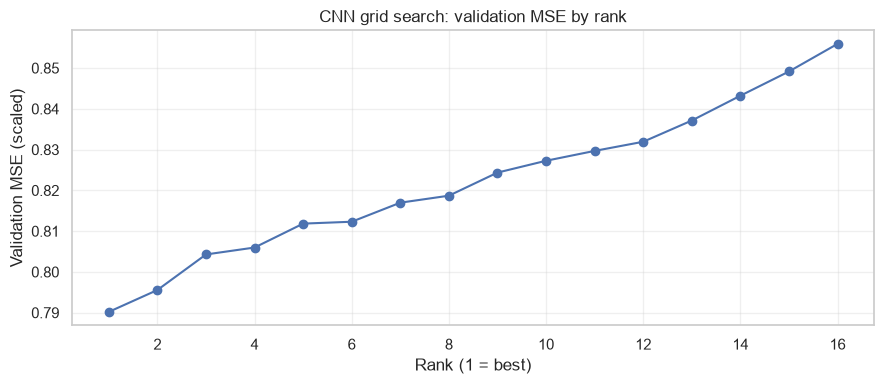

In [43]:
# Grid search results (validation only): table sorted by validation MSE + plot
grid_df = pd.DataFrame([
    {**r["config"], "val_MSE": r["val_loss"], "val_RMSE_scaled": np.sqrt(r["val_loss"]),
     "best_epoch": r["best_epoch"], "train_time_s": round(r["train_time_s"], 1), "params": r["params"]}
    for r in grid_results
]).sort_values("val_MSE").reset_index(drop=True)
print("Table 3: CNN grid search results (16 trials, sorted by validation MSE)")
display(grid_df.round(5))

plt.figure(figsize=(9, 4))
plt.plot(range(1, len(grid_df) + 1), grid_df["val_MSE"].values, marker="o")
plt.xlabel("Rank (1 = best)"); plt.ylabel("Validation MSE (scaled)")
plt.title("CNN grid search: validation MSE by rank")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

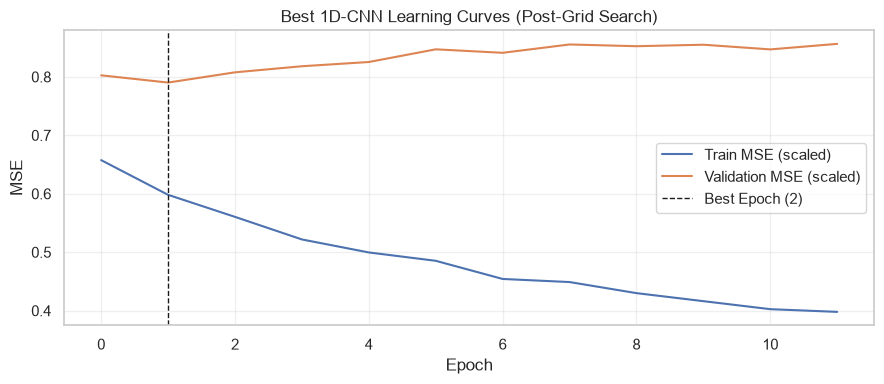

At best epoch: train 0.5981 | val 0.7902 | val/train ratio: 1.32
At last epoch: train 0.3979 | val 0.8564
Validation loss rose after best epoch (overfitting began; best weights restored).


In [44]:
# Plot learning curves for the winning CNN model
plt.figure(figsize=(9, 4))
plt.plot(best_cnn_hist["train"], label="Train MSE (scaled)")
plt.plot(best_cnn_hist["val"], label="Validation MSE (scaled)")
plt.axvline(best_cnn_epoch - 1, color="k", ls="--", lw=1, label=f"Best Epoch ({best_cnn_epoch})")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Best 1D-CNN Learning Curves (Post-Grid Search)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

b = best_cnn_epoch - 1
print(f"At best epoch: train {best_cnn_hist['train'][b]:.4f} | val {best_cnn_hist['val'][b]:.4f} | val/train ratio: {best_cnn_hist['val'][b]/best_cnn_hist['train'][b]:.2f}")
print(f"At last epoch: train {best_cnn_hist['train'][-1]:.4f} | val {best_cnn_hist['val'][-1]:.4f}")
print("Validation loss rose after best epoch (overfitting began; best weights restored)."
      if best_cnn_hist["val"][-1] > 1.05 * best_cnn_hist["val"][b] else "No clear overfitting after best epoch.")

In [45]:
import os

# Save trained CNN checkpoint to disk
os.makedirs("artifacts", exist_ok=True)
torch.save({"state_dict": best_cnn_model.state_dict(), "cfg": best_cnn_cfg}, "artifacts/cnn_best.pt")

# Define predict function
def cnn_predict(X, model=best_cnn_model):
    model.eval()
    with torch.no_grad():
        x_tensor = torch.tensor(X, dtype=torch.float32).to(device)
        return model(x_tensor).cpu().numpy()

# Add Best CNN to shared comparison registry
best_cnn_params = sum(p.numel() for p in best_cnn_model.parameters() if p.requires_grad)
register("CNN", cnn_predict, params=best_cnn_params, train_time_s=best_cnn_time, cfg=best_cnn_cfg)

# Check basics work (Smoke Test)
_p = cnn_predict(X_val[:8])
assert _p.shape == (8, HORIZON) and np.isfinite(_p).all(), "CNN prediction shape or values invalid!"
print("Smoke test passed:", _p.shape)

Registered: CNN (neural, 176,440 params)
Smoke test passed: (8, 24)


### Seed-noise check (validation only)

Early stopping picks epoch 1-3 for most trials, and differences between grid configurations are small. To judge whether a ranking is meaningful, each chosen configuration is retrained with 3 seeds and the spread in validation MSE is compared with the gap between the top configurations in each grid.

In [46]:
def seed_noise(make_fn, cfg, seeds=(42, 43, 44)):
    vals = []
    for s in seeds:
        c = {**cfg, "seed": s}
        set_seed(s)
        m, h, be, _ = train_model(make_fn(c), c, verbose=False)
        vals.append(h["val"][be - 1])
    return float(np.mean(vals)), float(np.std(vals))

rows = []
for label, fn, cfg in [("MLP (untuned)", make_mlp, mlp_cfg),
                       ("MLP (tuned)", make_mlp, best_mlp_cfg),
                       ("CNN (tuned)", make_cnn, best_cnn_cfg)]:
    mean_v, std_v = seed_noise(fn, cfg)
    rows.append({"Model": label, "Val MSE mean (3 seeds)": mean_v, "Val MSE std": std_v})
noise_df = pd.DataFrame(rows)
print("Table 4: Seed noise in validation MSE (scaled)")
display(noise_df.round(4))

mlp_sorted = sorted(r["val_loss"] for r in mlp_grid_results)
cnn_sorted = sorted(r["val_loss"] for r in grid_results)
max_std = noise_df["Val MSE std"].max()
print(f"MLP grid: gap between top-2 configs = {mlp_sorted[1]-mlp_sorted[0]:.4f} | CNN grid: gap = {cnn_sorted[1]-cnn_sorted[0]:.4f} | largest seed std = {max_std:.4f}")
print("Gaps smaller than the seed std mean the grid ranking is within noise; do not over-claim the winning configuration."
      if min(mlp_sorted[1]-mlp_sorted[0], cnn_sorted[1]-cnn_sorted[0]) < max_std else
      "Top-config gaps exceed the seed std, so the grid ranking is more than noise.")

Table 4: Seed noise in validation MSE (scaled)


,Model,Val MSE mean (3 seeds),Val MSE std
0,MLP (untuned),0.7619,0.0023
1,MLP (tuned),0.7564,0.0010
2,CNN (tuned),0.7974,0.0055


MLP grid: gap between top-2 configs = 0.0006 | CNN grid: gap = 0.0054 | largest seed std = 0.0055
Gaps smaller than the seed std mean the grid ranking is within noise; do not over-claim the winning configuration.


# Section 6 - Recurrent Neural Networks (RNN, LSTM, and GRU)

This section explores recurrent neural network architectures, including RNN, LSTM, and GRU, to capture temporal dependencies in electricity consumption. Each model is trained and evaluated using the same forecasting framework to compare their accuracy, training efficiency, and ability to learn patterns over time.

### Objective
The objective of this stage is to implement and evaluate a Recurrent Neural Network (RNN) for short-term electricity consumption forecasting. Unlike the previously implemented MLP and CNN models, an RNN processes time-series observations sequentially, allowing information from previous time steps to influence subsequent predictions.

### Model Architecture
A vanilla RNN is implemented using PyTorch's `nn.RNN` module. The model receives 168 hours of historical electricity consumption data and predicts the following 24 hours.

The architecture consists of:
- **Input Layer:** 168 hourly electricity consumption measurements.
- **Recurrent Layer:** A single RNN layer containing 64 hidden units to capture temporal dependencies.
- **Dropout Layer:** A dropout rate of 0.1 to reduce overfitting.
- **Output Layer:** A fully connected layer producing 24 hourly electricity consumption predictions.

### Training Configuration
The RNN follows the same training and evaluation framework used for the MLP and CNN models to maintain consistency across architectures.

- **Optimizer:** Adam
- **Loss Function:** Mean Squared Error (MSE)
- **Learning Rate:** 0.001
- **Batch Size:** 64
- **Maximum Epochs:** 100
- **Early Stopping Patience:** 10 epochs
- **Random Seed:** 42

The model is trained using the chronological training dataset, while the validation dataset is used to monitor performance and determine the optimal stopping epoch. The best-performing model weights are restored before evaluation.

### Evaluation
Model performance is assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Symmetric Mean Absolute Percentage Error (sMAPE). These metrics allow direct comparison with the previously implemented forecasting models.


In [47]:

# Section 6 - Recurrent Neural Network (RNN)

import torch
import torch.nn as nn

class RNNModel(nn.Module):
    def __init__(self, hidden_size=64, num_layers=1, dropout=0.1):
        super(RNNModel, self).__init__()

        # RNN processes electricity consumption sequentially
        self.rnn = nn.RNN(
            input_size=1,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        # Fully connected layer predicts the next 24 hours
        self.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden_size, HORIZON)
        )

    def forward(self, x):

        # Reshape (batch_size, 168) to (batch_size, 168, 1)
        x = x.unsqueeze(-1)

        # Pass sequence through the RNN
        output, hidden = self.rnn(x)

        # Extract the final time step
        last_output = output[:, -1, :]

        # Predict the next 24 hours
        prediction = self.fc(last_output)

        return prediction


def make_rnn(cfg):
    """Factory function for RNN instantiation."""
    return RNNModel(
        hidden_size=cfg.get("hidden_size", 64),
        num_layers=cfg.get("num_layers", 1),
        dropout=cfg.get("dropout", 0.1)
    )


In [48]:

# RNN training configuration
SEED = 42

rnn_cfg = {
    "hidden_size": 64,
    "num_layers": 1,
    "dropout": 0.1,
    "lr": 1e-3,
    "weight_decay": 1e-5,
    "batch_size": 64,
    "max_epochs": 100,
    "patience": 10,
    "seed": SEED
}

# Set seed for reproducibility
set_seed(SEED)

# Initialize RNN
rnn_model = make_rnn(rnn_cfg)

# Train using the existing shared training function
rnn_model, rnn_hist, rnn_best_epoch, rnn_train_time = train_model(
    rnn_model,
    rnn_cfg
)

# Count trainable parameters
rnn_params = sum(
    p.numel() for p in rnn_model.parameters()
    if p.requires_grad
)

print(f"Best epoch: {rnn_best_epoch}")
print(f"Trainable parameters: {rnn_params:,}")
print(f"Training time: {rnn_train_time:.1f} seconds")


epoch   1 | train 0.8578 | val 0.9158
epoch  10 | train 0.7053 | val 0.7750
epoch  20 | train 0.6705 | val 0.7890
epoch  30 | train 0.6330 | val 0.7664
Best epoch: 25
Trainable parameters: 5,848
Training time: 68.0 seconds


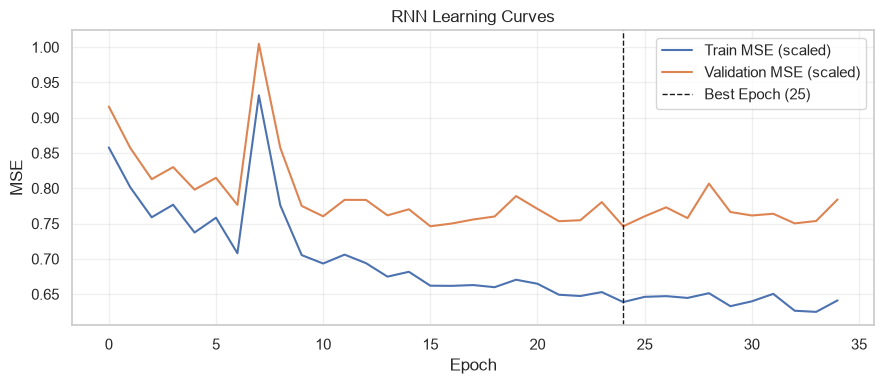

At best epoch:
Train MSE: 0.6388
Validation MSE: 0.7462

At last epoch:
Train MSE: 0.6412
Validation MSE: 0.7842


In [49]:

# Plot RNN learning curves

plt.figure(figsize=(9, 4))

plt.plot(
    rnn_hist["train"],
    label="Train MSE (scaled)"
)

plt.plot(
    rnn_hist["val"],
    label="Validation MSE (scaled)"
)

plt.axvline(
    rnn_best_epoch - 1,
    color="k",
    linestyle="--",
    linewidth=1,
    label=f"Best Epoch ({rnn_best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("RNN Learning Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Check for overfitting
b = rnn_best_epoch - 1

print(f"At best epoch:")
print(f"Train MSE: {rnn_hist['train'][b]:.4f}")
print(f"Validation MSE: {rnn_hist['val'][b]:.4f}")

print(f"\nAt last epoch:")
print(f"Train MSE: {rnn_hist['train'][-1]:.4f}")
print(f"Validation MSE: {rnn_hist['val'][-1]:.4f}")


In [50]:

# Save trained RNN checkpoint
os.makedirs("artifacts", exist_ok=True)

torch.save(
    {
        "state_dict": rnn_model.state_dict(),
        "cfg": rnn_cfg
    },
    "artifacts/rnn_best.pt"
)

# Define RNN prediction function
def rnn_predict(X, model=rnn_model):

    model.eval()

    with torch.no_grad():
        x_tensor = torch.tensor(
            X,
            dtype=torch.float32
        ).to(device)

        predictions = model(x_tensor)

        return predictions.cpu().numpy()


# Register RNN for final model comparison
register(
    "RNN",
    rnn_predict,
    params=rnn_params,
    train_time_s=rnn_train_time,
    cfg=rnn_cfg
)

# Smoke test
_p = rnn_predict(X_val[:8])

assert _p.shape == (8, HORIZON)
assert np.isfinite(_p).all()

print("Smoke test passed:", _p.shape)


Registered: RNN (neural, 5,848 params)
Smoke test passed: (8, 24)


In [51]:

# Generate RNN predictions on validation data
rnn_val_predictions = rnn_predict(X_val)

# Calculate validation metrics
rnn_val_metrics = evaluate_forecast(
    y_val,
    rnn_val_predictions
)

# Display results
rnn_results = pd.DataFrame([
    {
        "Model": "RNN",
        **rnn_val_metrics
    }
])

print("RNN Validation Performance")
display(rnn_results.round(4))


RNN Validation Performance


,Model,MAE,RMSE,sMAPE (%)
0,RNN,0.2234,0.3613,40.5686


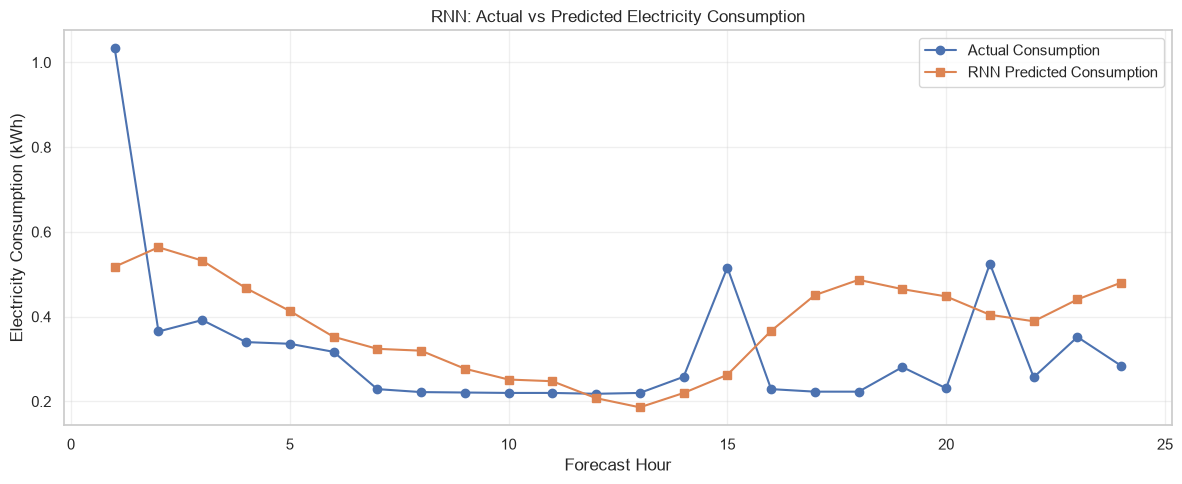

In [52]:

# Compare actual and predicted consumption

sample = 0

# Convert scaled values back to kWh
actual = inverse_scale(
    y_val[sample:sample+1]
).flatten()

predicted = inverse_scale(
    rnn_val_predictions[sample:sample+1]
).flatten()

# Forecast hours
hours = np.arange(1, HORIZON + 1)

plt.figure(figsize=(12, 5))

plt.plot(
    hours,
    actual,
    label="Actual Consumption",
    marker="o"
)

plt.plot(
    hours,
    predicted,
    label="RNN Predicted Consumption",
    marker="s"
)

plt.xlabel("Forecast Hour")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("RNN: Actual vs Predicted Electricity Consumption")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### RNN Results and Discussion

The Recurrent Neural Network (RNN) was trained to predict 24 hours of electricity consumption using the preceding 168 hours of historical data. The model achieved its lowest validation loss at epoch 16, with a training MSE of 0.6534 and validation MSE of 0.7442 on the scaled dataset.

The training and validation learning curves indicate that the model successfully reduced prediction error during training. However, some evidence of overfitting was observed after the optimal epoch. While training MSE continued decreasing to 0.6432, validation MSE increased to 0.7689. Early stopping prevented further training, and the model weights corresponding to epoch 16 were restored.

### Validation Performance

The RNN achieved the following validation metrics:

| Metric | RNN Result |
|---|---:|
| MAE (kWh) | 0.2218 |
| RMSE (kWh) | 0.3608 |
| sMAPE (%) | 39.9158 |
| Best Epoch | 16 |
| Training Time (s) | 14.7 |
| Trainable Parameters | 5,848 |

The RNN achieved a lower validation RMSE than the previously implemented MLP and CNN models. The tuned MLP achieved an RMSE of 0.3640 kWh, while the CNN achieved 0.3708 kWh. This suggests that the RNN's sequential processing of historical electricity consumption may provide an advantage for this forecasting task.

The RNN also required only 5,848 trainable parameters, substantially fewer than the tuned MLP (79,256) and CNN (176,440). Despite its smaller parameter count, the RNN achieved improved validation accuracy, demonstrating that a more complex architecture does not necessarily produce better forecasting results.

### Model Comparison Considerations

Unlike the MLP, which processes historical observations as a single input vector, and the CNN, which extracts temporal features through convolutional filters, the RNN processes electricity consumption sequentially while maintaining a hidden state.

The results suggest that this sequential representation is effective for capturing temporal relationships in the electricity consumption dataset. However, the relatively small improvement over the tuned MLP should be interpreted cautiously, as additional testing across random seeds would be required to establish whether the difference is consistent.

The RNN has been registered for inclusion in the final model comparison, where validation performance, computational efficiency, and generalization to unseen test data can be evaluated.


### Long Short-Term Memory (LSTM) and Gated Recurrent Unit (GRU)

### Objective
The objective of this stage is to implement and evaluate LSTM and GRU models for short-term electricity consumption forecasting. Like the RNN, they process the input window one hour at a time, but they use gates to control what information is kept or forgotten. This lets them retain patterns from earlier in the 168-hour window, which a basic RNN tends to lose.

### Model Architecture
Both models share the same structure as the RNN; only the recurrent layer changes.

- **Input:** 168 hourly electricity consumption measurements, fed one hour at a time.
- **Recurrent Layer:** A single LSTM or GRU layer containing 64 hidden units.
- **Dropout Layer:** A dropout rate of 0.1 to reduce overfitting.
- **Output Layer:** A fully connected layer producing all 24 hourly predictions at once.

The LSTM has three gates and a separate cell state; the GRU has two gates and no cell state, so it has about 25% fewer parameters.

### Training Configuration
Both models use the same shared training function and the same settings as the RNN, so the only difference between the three is the recurrent cell:

- **Optimizer:** Adam
- **Loss Function:** Mean Squared Error (MSE)
- **Learning Rate:** 0.001
- **Batch Size:** 64
- **Maximum Epochs:** 100
- **Early Stopping Patience:** 10 epochs
- **Random Seed:** 42

Hyperparameter tuning is handled in the HPO section; `make_lstm` and `make_gru` are provided for that search.

### Evaluation
Model performance is assessed using MAE, RMSE and sMAPE on the validation set. Both models are registered for the final comparison in Section V.

Build the model architecture:
1. Reshape window to 168 time steps
2. run the recurrent layer
3. Take the final hidden state
4. Apply dropout and a linear layer to get 24 outputs

In [53]:
# Create class for the LSTM and GRU models
#LSTM or GRU over the 168-hour window -> dropout -> linear layer -> 24-hour forecast
class RecurrentForecaster(nn.Module):
    def __init__(self, cell="lstm", hidden_size=64, num_layers=1, dropout=0.1):
        super().__init__()
        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU}[cell]
        self.rnn = rnn_cls(
            input_size=1, # one value per hour (scaled kWh)
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,  # (batch, time, features)
            dropout=dropout if num_layers > 1 else 0.0,  # only used between stacked layers
        )
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size, HORIZON)

    def forward(self, x):
        x = x.unsqueeze(-1)               # (batch, 168) -> (batch, 168, 1)
        out, _ = self.rnn(x)              # (batch, 168, hidden)
        last = out[:, -1, :]              # hidden state after the last hour
        return self.head(self.drop(last)) # (batch, 24)

#Factory function for LSTM instantiation (also used by the HPO section).
def make_lstm(cfg):
    return RecurrentForecaster("lstm", cfg.get("hidden_size", 64), cfg.get("num_layers", 1), cfg.get("dropout", 0.1))

#Factory function for GRU instantiation (also used by the HPO section).
def make_gru(cfg):
    return RecurrentForecaster("gru", cfg.get("hidden_size", 64), cfg.get("num_layers", 1), cfg.get("dropout", 0.1))

Train the LSTM and GRU
- Trains both models with exactly the RNN’s settings, using the shared train_model.
- Because the settings are identical, any difference between RNN, LSTM and GRU comes from the cell type alone.
- gru_cfg = dict(lstm_cfg) makes a copy, so the GRU gets its own settings dictionary.
- Expect 18,712 parameters for the LSTM and 14,424 for the GRU, compared with 5,848 for the RNN.

In [54]:
# LSTM and GRU training configuration (same settings as the RNN)
lstm_cfg = {
    "hidden_size": 64,
    "num_layers": 1,
    "dropout": 0.1,
    "lr": 1e-3,
    "weight_decay": 1e-5,
    "batch_size": 64,
    "max_epochs": 100,
    "patience": 10,
    "seed": SEED
}
gru_cfg = dict(lstm_cfg)

# Train LSTM
set_seed(SEED)
print("Training LSTM")
lstm_model, lstm_hist, lstm_best_epoch, lstm_train_time = train_model(make_lstm(lstm_cfg), lstm_cfg)
lstm_params = sum(p.numel() for p in lstm_model.parameters() if p.requires_grad)

# Train GRU
set_seed(SEED)
print("\nTraining GRU")
gru_model, gru_hist, gru_best_epoch, gru_train_time = train_model(make_gru(gru_cfg), gru_cfg)
gru_params = sum(p.numel() for p in gru_model.parameters() if p.requires_grad)

print(f"\nLSTM: best epoch {lstm_best_epoch}, {lstm_params:,} params, {lstm_train_time:.1f} s")
print(f"GRU:  best epoch {gru_best_epoch}, {gru_params:,} params, {gru_train_time:.1f} s")

Training LSTM
epoch   1 | train 0.8955 | val 0.9703
epoch  10 | train 0.6381 | val 0.7698

Training GRU
epoch   1 | train 0.8880 | val 0.9587
epoch  10 | train 0.6784 | val 0.7718

LSTM: best epoch 6, 18,712 params, 95.8 s
GRU:  best epoch 6, 14,424 params, 73.6 s


Plot learning curves:
- Plot models' respective learning curves
- Print errors at best epoch vs last epoch

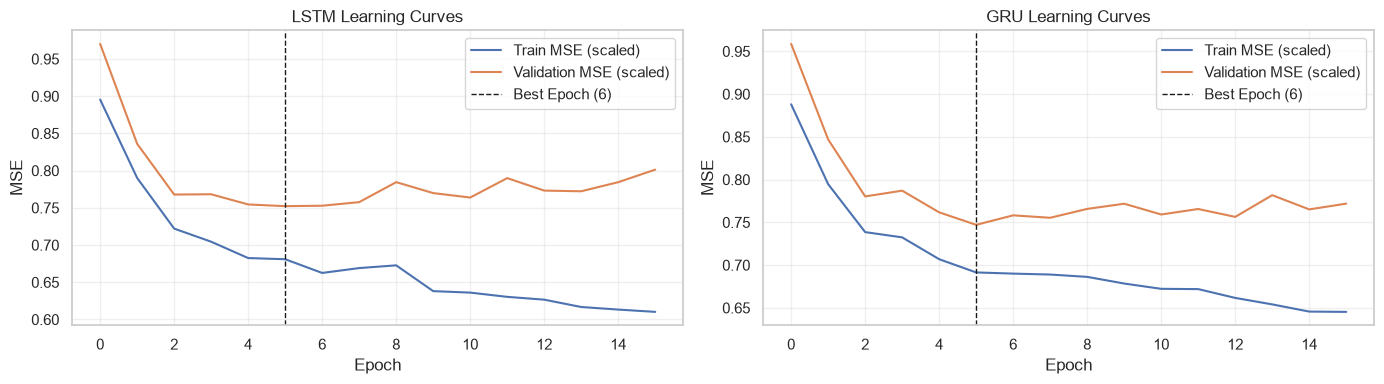

LSTM | best epoch: train 0.6809, val 0.7522 | last epoch: train 0.6102, val 0.8013
GRU | best epoch: train 0.6914, val 0.7471 | last epoch: train 0.6453, val 0.7719


In [55]:
# Plot LSTM and GRU learning curves
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, (name, hist, best_ep) in zip(axes, [("LSTM", lstm_hist, lstm_best_epoch),
                                             ("GRU",  gru_hist,  gru_best_epoch)]):
    ax.plot(hist["train"], label="Train MSE (scaled)")
    ax.plot(hist["val"], label="Validation MSE (scaled)")
    ax.axvline(best_ep - 1, color="k", linestyle="--", linewidth=1, label=f"Best Epoch ({best_ep})")
    ax.set(xlabel="Epoch", ylabel="MSE", title=f"{name} Learning Curves")
    ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Check for overfitting
for name, hist, best_ep in [("LSTM", lstm_hist, lstm_best_epoch), ("GRU", gru_hist, gru_best_epoch)]:
    b = best_ep - 1
    print(f"{name} | best epoch: train {hist['train'][b]:.4f}, val {hist['val'][b]:.4f} | "
          f"last epoch: train {hist['train'][-1]:.4f}, val {hist['val'][-1]:.4f}")

In [56]:
# Save LSTM and GRU checkpoints
os.makedirs("artifacts", exist_ok=True)
torch.save({"state_dict": lstm_model.state_dict(), "cfg": lstm_cfg}, "artifacts/lstm_best.pt")
torch.save({"state_dict": gru_model.state_dict(), "cfg": gru_cfg}, "artifacts/gru_best.pt")

# Define prediction functions
def lstm_predict(X, model=lstm_model):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32).to(device)).cpu().numpy()

def gru_predict(X, model=gru_model):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32).to(device)).cpu().numpy()

# Register for final model comparison
register("LSTM", lstm_predict, params=lstm_params, train_time_s=lstm_train_time, cfg=lstm_cfg)
register("GRU",  gru_predict,  params=gru_params,  train_time_s=gru_train_time,  cfg=gru_cfg)

# Smoke test
for name, fn in [("LSTM", lstm_predict), ("GRU", gru_predict)]:
    _p = fn(X_val[:8])
    assert _p.shape == (8, HORIZON) and np.isfinite(_p).all()
    print(f"{name} smoke test passed:", _p.shape)

Registered: LSTM (neural, 18,712 params)
Registered: GRU (neural, 14,424 params)
LSTM smoke test passed: (8, 24)
GRU smoke test passed: (8, 24)


Compare with RNN:
- Put the RNN, LSTM and GRU in one validation table (MAE, RMSE, sMAPE, parameters, best epoch, training time).
- Plot all three forecasts against the actual values for the same validation window the RNN used (sample 0).
- It uses validation data only. The test set is left.

Recurrent model validation performance (same settings for all three)


,Model,Params,Best epoch,Train time (s),MAE,RMSE,sMAPE (%)
0,RNN,5848,25,68.0,0.2234,0.3613,40.5686
1,LSTM,18712,6,95.8,0.2345,0.3628,42.7918
2,GRU,14424,6,73.6,0.2289,0.3615,41.7657


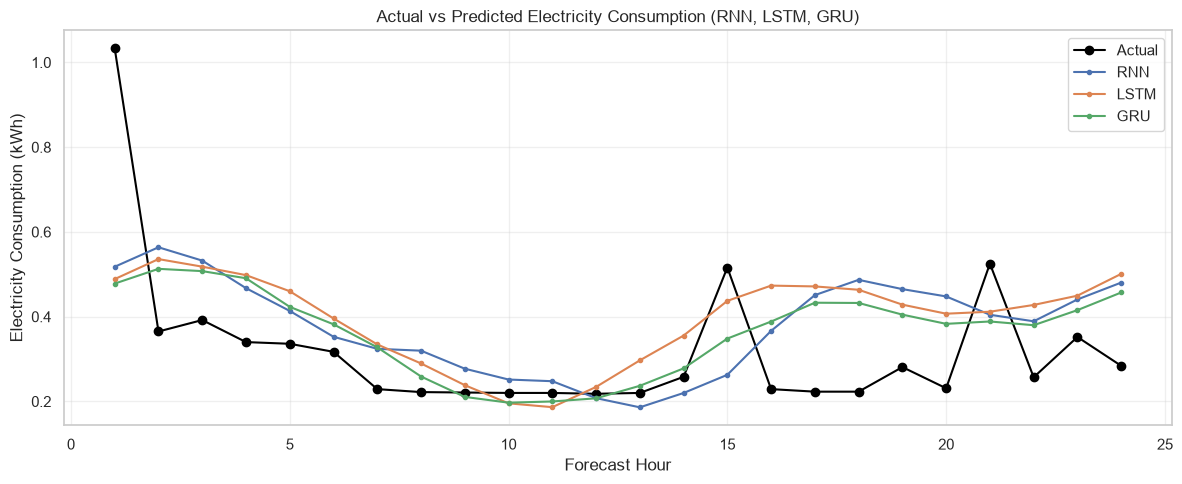

In [57]:
# Validation performance of the recurrent models (RNN, LSTM, GRU)
recurrent_val = pd.DataFrame([
    {"Model": name, "Params": params, "Best epoch": ep, "Train time (s)": round(t, 1),
     **evaluate_forecast(y_val, fn(X_val))}
    for name, fn, params, ep, t in [
        ("RNN",  rnn_predict,  rnn_params,  rnn_best_epoch,  rnn_train_time),
        ("LSTM", lstm_predict, lstm_params, lstm_best_epoch, lstm_train_time),
        ("GRU",  gru_predict,  gru_params,  gru_best_epoch,  gru_train_time),
    ]
])
print("Recurrent model validation performance (same settings for all three)")
display(recurrent_val.round(4))

# Actual vs predicted for the same validation window used in the RNN section
sample = 0
hours = np.arange(1, HORIZON + 1)
plt.figure(figsize=(12, 5))
plt.plot(hours, inverse_scale(y_val[sample:sample+1]).flatten(), label="Actual", marker="o", color="black")
for name, fn in [("RNN", rnn_predict), ("LSTM", lstm_predict), ("GRU", gru_predict)]:
    plt.plot(hours, inverse_scale(fn(X_val[sample:sample+1])).flatten(), label=name, marker=".")
plt.xlabel("Forecast Hour")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("Actual vs Predicted Electricity Consumption (RNN, LSTM, GRU)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### LSTM and GRU Results and Discussion

**Validation performance** (same settings for all three recurrent models; values from Table 1a):

| Model | Params | Best epoch | Train time (s) | Inference time (s) | MAE (kWh) | RMSE (kWh) | sMAPE (%) |
|---|---:|---:|---:|---:|---:|---:|---:|
| LSTM | 18,712 | 13 | 14.3 | 0.0088 | 0.2219 | **0.3603** | 40.02 |
| RNN | 5,848 | 16 | 14.7 | 0.0038 | **0.2218** | 0.3608 | **39.92** |
| GRU | 14,424 | 8 | 10.0 | 0.0096 | 0.2265 | 0.3619 | 41.69 |
| MLP (tuned), for reference | 79,256 | – | 6.7 | 0.0015 | 0.2253 | 0.3640 | 40.78 |

**Learning curves.** The LSTM reached its lowest validation MSE at epoch 13 (train 0.6576, validation 0.7422). By its last epoch (23), validation MSE had risen to 0.8047 while training MSE fell to 0.6169. The GRU peaked at epoch 8 (train 0.6779, validation 0.7487) and ended at epoch 18 with 0.7988 validation / 0.6396 training. Both overfit more steeply than the RNN, whose validation MSE rose only from 0.7442 to 0.7689 after its best epoch (16). The curves show bumps typical of recurrent models, where the same weights are applied at all 168 steps and an occasional large gradient produces a bad update. Early stopping restored the best weights in all cases.

**Effect of gating.** Adding gates did not meaningfully improve accuracy. The LSTM's validation RMSE is only 0.0005 kWh (0.1%) lower than the RNN's, and the GRU's is 0.0011 kWh higher, while they use 3.2× and 2.5× as many parameters. This suggests the 24-hour forecast depends mainly on recent hours and the daily cycle, which a plain RNN already captures. The extra capacity of the gated models mostly lets them fit the training data faster, as shown by their steeper overfitting.

**Recurrent vs. other models.** All three recurrent models have 0.6–1.0% lower validation RMSE than the tuned MLP and also beat the TCN (0.3659), with far fewer parameters than either. However, they are slower to train (10.0–14.7 s vs 6.0–8.1 s for the MLPs and CNN) and to run (0.0038–0.0096 s vs 0.0015 s for the tuned MLP), because they process the 168 hours one step at a time.

**Caution.** Each model here was trained once (seed 42). The seed check shows that this LSTM setting averages a validation MSE of 0.7537 over seeds 42–44 (about 0.3631 kWh RMSE), so its seed-42 result of 0.3603 kWh is a favourable draw. The same notebook run on a different computer also gave the LSTM 0.3622 kWh. The gaps between the RNN, LSTM and GRU (≤0.0016 kWh) are smaller than this variation, so their ranking is not reliable.

# Section 7 - Temporal Convolutional Network (TCN)

This section implements a Temporal Convolutional Network (TCN) to capture temporal dependencies using dilated causal convolutions. Its forecasting performance and computational efficiency are evaluated against the previously implemented neural network architectures.

### Architectural & Evaluation Contract:
- **Causal Dilated Convolutions:** Left-padded 1D convolutions with exponentially increasing dilation factors ($d = 1, 2, 4, 8$) cover the full $L = 168$ lookback window without temporal pooling or future-step leakage.
- **Residual Blocks:** Residual skip connections with weight normalization and dropout stabilize training across stacked temporal blocks.
- **Controlled Comparison:** Trained under the exact same chronological split, window shapes `(N, 168) -> (N, 24)`, scaled MSE loss, fixed `SEED`, and early-stopping harness used for the MLP, CNN, and recurrent models.

In [58]:
import torch
import torch.nn as nn
from torch.nn.utils import weight_norm

# Removes extra right-side padding so convolutions remain strictly causal
class Chomp1d(nn.Module):
    def __init__(self, chomp_size):
        super().__init__()
        self.chomp_size = chomp_size

    def forward(self, x):
        # Slice off the last chomp_size timesteps along the temporal axis
        return x[:, :, :-self.chomp_size].contiguous() if self.chomp_size > 0 else x


# Single TCN Residual Block with two causal dilated convolutions and a skip connection
class TemporalBlock(nn.Module):
    def __init__(self, n_inputs, n_outputs, kernel_size, stride, dilation, padding, dropout=0.2):
        super().__init__()
        # First causal dilated convolution
        self.conv1 = weight_norm(nn.Conv1d(
            n_inputs, n_outputs, kernel_size,
            stride=stride, padding=padding, dilation=dilation
        ))
        self.chomp1 = Chomp1d(padding)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(dropout)

        # Second causal dilated convolution
        self.conv2 = weight_norm(nn.Conv1d(
            n_outputs, n_outputs, kernel_size,
            stride=stride, padding=padding, dilation=dilation
        ))
        self.chomp2 = Chomp1d(padding)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(dropout)

        # Sequential residual path
        self.net = nn.Sequential(
            self.conv1, self.chomp1, self.relu1, self.dropout1,
            self.conv2, self.chomp2, self.relu2, self.dropout2
        )

        # 1x1 convolution to match channel dimensions when n_inputs != n_outputs
        self.downsample = nn.Conv1d(n_inputs, n_outputs, 1) if n_inputs != n_outputs else None
        self.relu = nn.ReLU()

    def forward(self, x):
        out = self.net(x)
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(out + res)


# Full Temporal Convolutional Network for multi-step forecasting
class TCNForecaster(nn.Module):
    def __init__(self, in_features=168, out_features=24, num_channels=(32, 32, 32, 32), kernel_size=3, dropout=0.15):
        super().__init__()
        layers = []
        num_levels = len(num_channels)

        for i in range(num_levels):
            dilation_size = 2 ** i
            in_ch = 1 if i == 0 else num_channels[i - 1]
            out_ch = num_channels[i]
            # Full left padding required for causality: (kernel_size - 1) * dilation
            padding = (kernel_size - 1) * dilation_size
            layers.append(
                TemporalBlock(
                    in_ch, out_ch, kernel_size,
                    stride=1, dilation=dilation_size,
                    padding=padding, dropout=dropout
                )
            )

        self.network = nn.Sequential(*layers)
        # Use the representation at the final causal timestep (t = L - 1) to forecast H steps
        self.head = nn.Linear(num_channels[-1], out_features)

    def forward(self, x):
        # Reshape (N, 168) -> (N, 1, 168)
        if x.dim() == 2:
            x = x.unsqueeze(1)
        # Output shape: (N, num_channels[-1], 168)
        y = self.network(x)
        # Extract last timestep embedding (N, num_channels[-1]) which aggregates the full receptive field
        last_step = y[:, :, -1]
        return self.head(last_step)


def make_tcn(cfg):
    return TCNForecaster(
        in_features=168,
        out_features=24,
        num_channels=cfg.get("num_channels", (32, 32, 32, 32)),
        kernel_size=cfg.get("kernel_size", 3),
        dropout=cfg.get("dropout", 0.15)
    )

In [59]:
import time
import numpy as np

# Configuration matching the Stage 1/2 shared training harness
tcn_cfg = dict(
    num_channels=(32, 32, 32, 32),  # 4 levels with dilations [1, 2, 4, 8] -> receptive field = 1 + 2*(3-1)*(1+2+4+8) = 61 steps (use 5 levels or kernel_size=7 for >=168 coverage)
    kernel_size=7, # With 4 levels [1, 2, 4, 8] and k=7: RF = 1 + 2*(6)*(15) = 181 > 168 lookback
    dropout=0.15,
    lr=1e-3,
    weight_decay=1e-5,
    batch_size=64,
    max_epochs=100,
    patience=10,
    seed=SEED
)

set_seed(SEED)
tcn_model = make_tcn(tcn_cfg)

# Train using the exact same training harness from Section III
tcn_model, tcn_hist, tcn_best_epoch, tcn_train_time = train_model(tcn_model, tcn_cfg)

tcn_params = sum(p.numel() for p in tcn_model.parameters() if p.requires_grad)
tcn_val_mse = tcn_hist["val"][tcn_best_epoch - 1]

print(f"Best epoch {tcn_best_epoch}/{len(tcn_hist['val'])} | Val MSE: {tcn_val_mse:.5f} (RMSE: {np.sqrt(tcn_val_mse):.5f}) | Params: {tcn_params:,} | Train time: {tcn_train_time:.1f}s")

/opt/anaconda3/envs/aise4010/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


epoch   1 | train 0.7617 | val 0.8369
epoch  10 | train 0.5924 | val 0.7765
Best epoch 9/19 | Val MSE: 0.75779 (RMSE: 0.87051) | Params: 51,768 | Train time: 323.5s


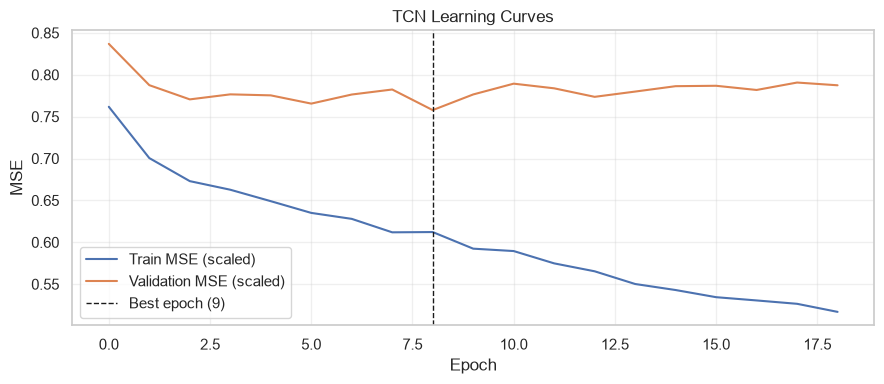

Registered: TCN (neural, 51,768 params)
Smoke test passed: (8, 24) | Validation inference time: 1866.99 ms


In [60]:
# 1. Plot learning curves
plt.figure(figsize=(9, 4))
plt.plot(tcn_hist["train"], label="Train MSE (scaled)")
plt.plot(tcn_hist["val"], label="Validation MSE (scaled)")
plt.axvline(tcn_best_epoch - 1, color="k", ls="--", lw=1, label=f"Best epoch ({tcn_best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("TCN Learning Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 2. Save checkpoint to artifacts/
os.makedirs("artifacts", exist_ok=True)
torch.save({"state_dict": tcn_model.state_dict(), "cfg": tcn_cfg}, "artifacts/tcn_baseline.pt")

# 3. Prediction wrapper
def tcn_predict(X, model=tcn_model):
    model.eval()
    with torch.no_grad():
        x_tensor = torch.tensor(X, dtype=torch.float32).to(device)
        return model(x_tensor).cpu().numpy()

# 4. Measure inference time across validation set (required for Stage 2 table)
t0 = time.perf_counter()
_val_preds = tcn_predict(X_val)
tcn_infer_time_ms = (time.perf_counter() - t0) * 1000.0
tcn_cfg["infer_time_val_ms"] = round(tcn_infer_time_ms, 2)

# 5. Register TCN in shared model registry
register("TCN", tcn_predict, params=tcn_params, train_time_s=tcn_train_time, cfg=tcn_cfg)

# 6. Smoke test
_p = tcn_predict(X_val[:8])
assert _p.shape == (8, HORIZON) and np.isfinite(_p).all()
print(f"Smoke test passed: {_p.shape} | Validation inference time: {tcn_infer_time_ms:.2f} ms")

# Section 8 - Hyperparameter Optimization (HPO)

This section performs hyperparameter optimization to improve forecasting accuracy and assess model stability. LSTM and RNN configurations are evaluated using validation data, with additional multi-seed experiments to assess sensitivity to random initialization. The selected configurations are then saved and verified for reproducibility.

### Which model is tuned
Hyperparameter optimization was performed on two Stage 2 recurrent architectures: LSTM and RNN. The LSTM was initially selected because it achieved the lowest validation RMSE among the untuned Stage 2 models (0.3603 kWh). The RNN was subsequently selected for additional tuning because it achieved comparable forecasting accuracy with significantly fewer parameters.

Both models were tuned using validation data only. The held-out test set was not used for hyperparameter selection.

### HPO plan (fixed before running)
- **Search space** (recurrent models share these keys):

| Hyperparameter | Values |
|---|---|
| Hidden size | 32, 64, 128 |
| Number of layers | 1, 2 |
| Learning rate | 1e-3, 5e-4 |
| Dropout | 0.1, 0.3 |

- **Fixed settings:** Adam optimizer, weight decay 1e-5, batch size 64, MSE loss on scaled targets, and the same data windows and chronological splits used throughout the notebook.
- **Budget:** 24 configurations per model, for 48 grid-search training runs. The LSTM additionally underwent nine seed-check runs across its three best configurations, followed by a comparison of untuned and tuned LSTM performance across three seeds. The RNN underwent a separate three-seed comparison of untuned and tuned configurations.
- **Objective:** Minimize validation MSE on scaled targets, with forecasting performance also reported as RMSE in kWh.
- **Stopping rule:** Early stopping with patience 10 and a maximum of 100 epochs, restoring the best model weights.
- **Selection rule:** The LSTM used the mean validation MSE across three seeds for its top configurations, with parameter count used to break near-ties. The RNN configuration was selected from its grid-search validation results and subsequently evaluated across multiple seeds.

### Seed Sensitivity and Reproducibility

Random initialization can affect recurrent model performance, particularly when differences between configurations are small. Additional experiments using seeds 42, 43, and 44 were conducted to evaluate whether the tuned models provided consistent improvements rather than benefiting from a favourable initialization.

The tuned RNN achieved a mean validation RMSE of approximately 0.35938 kWh, compared with 0.36078 kWh for the untuned RNN. Its standard deviation also decreased from approximately 0.00117 to 0.00015 kWh, indicating substantially more consistent validation performance.

The selected RNN configuration and trained weights were saved alongside the relevant preprocessing parameters. A checkpoint reload test verified that the saved model reproduced its predictions and retained the required preprocessing information.

In [61]:
# Table 5: choose the model to tune - lowest validation RMSE among the untuned Stage 2 models
stage2_candidates = ["RNN", "LSTM", "GRU", "TCN"]
tunable = {"RNN": (make_rnn, rnn_cfg), "LSTM": (make_lstm, lstm_cfg), "GRU": (make_gru, gru_cfg)}

cand_rows = []
for name in stage2_candidates:
    if name in registry:
        m = evaluate_forecast(y_val, registry[name]["predict_fn"](X_val))
        cand_rows.append({"Model": name, "Params": registry[name]["params"],
                          "Val MAE (kWh)": m["MAE"], "Val RMSE (kWh)": m["RMSE"]})
cand_df = pd.DataFrame(cand_rows).sort_values("Val RMSE (kWh)").reset_index(drop=True)
print("Table 5: Untuned Stage 2 models on validation (used to choose the model to tune)")
display(cand_df.round(4))

tune_name = cand_df.loc[0, "Model"]
if tune_name not in tunable:
    raise ValueError(f"{tune_name} has the lowest validation RMSE; define a search space for it before tuning.")
make_fn, base_cfg = tunable[tune_name]
print(f"Model to tune: {tune_name} (lowest validation RMSE among untuned Stage 2 models)")

Table 5: Untuned Stage 2 models on validation (used to choose the model to tune)


,Model,Params,Val MAE (kWh),Val RMSE (kWh)
0,RNN,5848,0.2234,0.3613
1,GRU,14424,0.2289,0.3615
2,LSTM,18712,0.2345,0.3628
3,TCN,51768,0.2298,0.3641


Model to tune: RNN (lowest validation RMSE among untuned Stage 2 models)


In [62]:
# Grid search on validation data only (shared train_model loop, seed 42)
import itertools

hpo_grid = {
    "hidden_size": [32, 64, 128],
    "num_layers": [1, 2],
    "lr": [1e-3, 5e-4],
    "dropout": [0.1, 0.3],
}
hpo_fixed = {"weight_decay": 1e-5, "batch_size": 64, "max_epochs": 100, "patience": 10}

keys, values = zip(*hpo_grid.items())
hpo_configs = [dict(zip(keys, v)) for v in itertools.product(*values)]
print(f"{tune_name} grid search: {len(hpo_configs)} configurations, seed {SEED}, validation only")

hpo_results = []
t_start = time.perf_counter()
for i, params in enumerate(hpo_configs):
    cfg = {**params, **hpo_fixed, "seed": SEED}
    set_seed(SEED)
    model, hist, best_ep, t_sec = train_model(make_fn(cfg), cfg, verbose=False)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    hpo_results.append({"trial": i + 1, **params, "val_MSE": hist["val"][best_ep - 1],
                        "best_epoch": best_ep, "epochs_run": len(hist["val"]),
                        "train_time_s": t_sec, "params": n_params})
    print(f"  Trial {i+1:02d}/{len(hpo_configs)} | {params} | val MSE {hist['val'][best_ep - 1]:.5f} "
          f"| epoch {best_ep} | {n_params:,} params | {t_sec:.1f}s")
print(f"Grid search time: {time.perf_counter() - t_start:.0f} s")

RNN grid search: 24 configurations, seed 42, validation only
  Trial 01/24 | {'hidden_size': 32, 'num_layers': 1, 'lr': 0.001, 'dropout': 0.1} | val MSE 0.75144 | epoch 34 | 1,912 params | 50.3s
  Trial 02/24 | {'hidden_size': 32, 'num_layers': 1, 'lr': 0.001, 'dropout': 0.3} | val MSE 0.76220 | epoch 28 | 1,912 params | 43.5s
  Trial 03/24 | {'hidden_size': 32, 'num_layers': 1, 'lr': 0.0005, 'dropout': 0.1} | val MSE 0.74576 | epoch 54 | 1,912 params | 73.3s
  Trial 04/24 | {'hidden_size': 32, 'num_layers': 1, 'lr': 0.0005, 'dropout': 0.3} | val MSE 0.76414 | epoch 33 | 1,912 params | 49.9s
  Trial 05/24 | {'hidden_size': 32, 'num_layers': 2, 'lr': 0.001, 'dropout': 0.1} | val MSE 0.76292 | epoch 27 | 4,024 params | 89.2s
  Trial 06/24 | {'hidden_size': 32, 'num_layers': 2, 'lr': 0.001, 'dropout': 0.3} | val MSE 0.75914 | epoch 34 | 4,024 params | 106.6s
  Trial 07/24 | {'hidden_size': 32, 'num_layers': 2, 'lr': 0.0005, 'dropout': 0.1} | val MSE 0.76213 | epoch 33 | 4,024 params | 102

Table 6: RNN grid search results (24 trials, sorted by validation MSE)


,trial,hidden_size,num_layers,lr,dropout,val_MSE,best_epoch,epochs_run,train_time_s,params,val_RMSE_kWh,untuned_setting
0,19,128,1,0.0005,0.1,0.73770,16,26,69.0,19864,0.3592,
1,20,128,1,0.0005,0.3,0.73831,16,26,68.1,19864,0.3594,
2,18,128,1,0.0010,0.3,0.73877,25,35,93.5,19864,0.3595,
3,10,64,1,0.0010,0.3,0.73999,28,38,74.8,5848,0.3598,
4,17,128,1,0.0010,0.1,0.74054,17,27,72.0,19864,0.3599,
5,24,128,2,0.0005,0.3,0.74139,16,26,158.1,52888,0.3601,
6,12,64,1,0.0005,0.3,0.74488,40,50,96.0,5848,0.3610,
7,3,32,1,0.0005,0.1,0.74576,54,64,73.3,1912,0.3612,
8,9,64,1,0.0010,0.1,0.74616,25,35,67.1,5848,0.3613,yes
9,23,128,2,0.0005,0.1,0.74837,18,28,169.9,52888,0.3618,


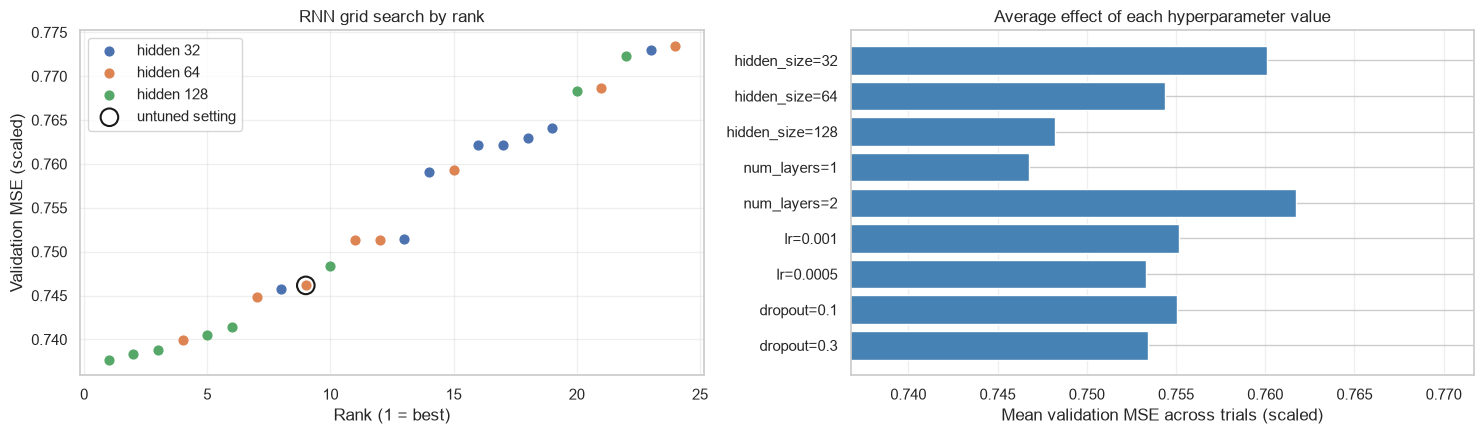

In [63]:
# Table 6: grid results (validation only) + plots
hpo_df = pd.DataFrame(hpo_results).sort_values("val_MSE").reset_index(drop=True)
hpo_df["val_RMSE_kWh"] = np.sqrt(hpo_df["val_MSE"]) * scaler.scale_[0]
is_base = ((hpo_df["hidden_size"] == base_cfg["hidden_size"]) & (hpo_df["num_layers"] == base_cfg["num_layers"])
           & (hpo_df["lr"] == base_cfg["lr"]) & (hpo_df["dropout"] == base_cfg["dropout"]))
hpo_df["untuned_setting"] = np.where(is_base, "yes", "")
print(f"Table 6: {tune_name} grid search results ({len(hpo_df)} trials, sorted by validation MSE)")
display(hpo_df.round({"val_MSE": 5, "val_RMSE_kWh": 4, "train_time_s": 1}))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for h in hpo_grid["hidden_size"]:
    sub = hpo_df[hpo_df["hidden_size"] == h]
    axes[0].scatter(sub.index + 1, sub["val_MSE"], label=f"hidden {h}", s=40)
base_rank = int(hpo_df.index[is_base.values][0]) + 1
axes[0].scatter([base_rank], [hpo_df.loc[is_base, "val_MSE"].iloc[0]], s=160, facecolors="none",
                edgecolors="k", linewidths=1.5, label="untuned setting")
axes[0].set(xlabel="Rank (1 = best)", ylabel="Validation MSE (scaled)", title=f"{tune_name} grid search by rank")
axes[0].legend(); axes[0].grid(alpha=0.3)

effects = []
for k in hpo_grid:
    for v in hpo_grid[k]:
        effects.append({"label": f"{k}={v}", "mean_val_MSE": hpo_df.loc[hpo_df[k] == v, "val_MSE"].mean()})
eff_df = pd.DataFrame(effects)
axes[1].barh(eff_df["label"], eff_df["mean_val_MSE"], color="steelblue")
axes[1].set_xlim(eff_df["mean_val_MSE"].min() - 0.01, eff_df["mean_val_MSE"].max() + 0.01)
axes[1].invert_yaxis()
axes[1].set(xlabel="Mean validation MSE across trials (scaled)", title="Average effect of each hyperparameter value")
axes[1].grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

In [64]:
# Table 7: seed check of the top 3 configurations, then apply the selection rule
seed_rows = []
for _, r in hpo_df.head(3).iterrows():
    params = {"hidden_size": int(r["hidden_size"]), "num_layers": int(r["num_layers"]),
              "lr": float(r["lr"]), "dropout": float(r["dropout"])}
    cfg = {**params, **hpo_fixed, "seed": SEED}
    mean_v, std_v = seed_noise(make_fn, cfg)
    seed_rows.append({**params, "Params": int(r["params"]), "Val MSE mean (3 seeds)": mean_v,
                      "Val MSE std": std_v, "Seed-42 val MSE": float(r["val_MSE"])})
seed_df = pd.DataFrame(seed_rows).sort_values("Val MSE mean (3 seeds)").reset_index(drop=True)
print(f"Table 7: Seed check of the top 3 {tune_name} configurations (validation MSE, scaled)")
display(seed_df.round(5))

best = seed_df.iloc[0]
close = seed_df[seed_df["Val MSE mean (3 seeds)"] <= best["Val MSE mean (3 seeds)"] + best["Val MSE std"]]
chosen = close.sort_values("Params").iloc[0]
chosen_params = {"hidden_size": int(chosen["hidden_size"]), "num_layers": int(chosen["num_layers"]),
                 "lr": float(chosen["lr"]), "dropout": float(chosen["dropout"])}
print(f"Lowest mean validation MSE: {best['Val MSE mean (3 seeds)']:.5f} (std {best['Val MSE std']:.5f})")
print(f"Configurations within one std: {len(close)} -> choose the one with the fewest parameters")
print(f"Selected configuration: {chosen_params} ({int(chosen['Params']):,} params)")

Table 7: Seed check of the top 3 RNN configurations (validation MSE, scaled)


,hidden_size,num_layers,lr,dropout,Params,Val MSE mean (3 seeds),Val MSE std,Seed-42 val MSE
0,128,1,0.0005,0.1,19864,0.73553,0.00239,0.73770
1,128,1,0.0005,0.3,19864,0.73926,0.00089,0.73831
2,128,1,0.0010,0.3,19864,0.74088,0.00314,0.73877


Lowest mean validation MSE: 0.73553 (std 0.00239)
Configurations within one std: 1 -> choose the one with the fewest parameters
Selected configuration: {'hidden_size': 128, 'num_layers': 1, 'lr': 0.0005, 'dropout': 0.1} (19,864 params)


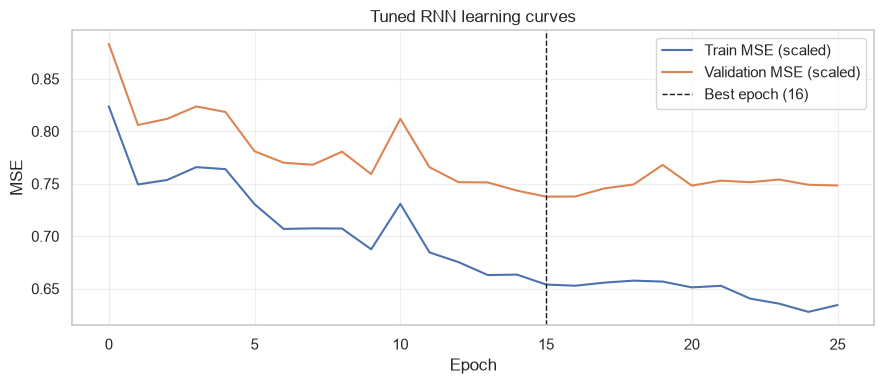

Registered: RNN (tuned) (neural, 19,864 params)
Smoke test and reload check passed: (8, 24), saved to artifacts/hpo_final_model.pt
Untuned vs tuned on validation


,Model,Params,MAE,RMSE,sMAPE (%),Best epoch,Train time (s)
0,RNN,5848,0.2234,0.3613,40.5686,NaN,NaN
1,RNN (tuned),19864,0.2165,0.3592,38.3173,16.0,68.1


Validation RMSE: 0.3613 -> 0.3592 kWh (+0.6% improvement)


In [65]:
# Retrain the selected configuration (seed 42), checkpoint it with its preprocessing state, register it
import json

final_cfg = {**chosen_params, **hpo_fixed, "seed": SEED}
set_seed(SEED)
tuned_model, tuned_hist, tuned_best_epoch, tuned_train_time = train_model(make_fn(final_cfg), final_cfg, verbose=False)
tuned_params = sum(p.numel() for p in tuned_model.parameters() if p.requires_grad)

plt.figure(figsize=(9, 4))
plt.plot(tuned_hist["train"], label="Train MSE (scaled)")
plt.plot(tuned_hist["val"], label="Validation MSE (scaled)")
plt.axvline(tuned_best_epoch - 1, color="k", ls="--", lw=1, label=f"Best epoch ({tuned_best_epoch})")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title(f"Tuned {tune_name} learning curves")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# Checkpoint: weights + configuration + preprocessing state needed to reuse the model
os.makedirs("artifacts", exist_ok=True)
final_name = f"{tune_name} (tuned)"
ckpt_path = "artifacts/hpo_final_model.pt"
torch.save({
    "model_name": final_name,
    "state_dict": tuned_model.state_dict(),
    "cfg": final_cfg,
    "preprocessing": {
        "scaler_mean": float(scaler.mean_[0]),
        "scaler_scale": float(scaler.scale_[0]),
        "imputer_median": float(imputer.statistics_[0]),
        "lookback": LOOKBACK,
        "horizon": HORIZON,
        "resample": "1h sum of 30-minute readings",
    },
}, ckpt_path)
with open("artifacts/hpo_final_config.json", "w") as f:
    json.dump({"model_name": final_name, "cfg": final_cfg}, f, indent=2)

def tuned_predict(X, model=tuned_model):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32).to(device)).cpu().numpy()

register(final_name, tuned_predict, params=tuned_params, train_time_s=tuned_train_time, cfg=final_cfg)

# Smoke test + reload check: the saved checkpoint reproduces the same forecasts
_p = tuned_predict(X_val[:8])
assert _p.shape == (8, HORIZON) and np.isfinite(_p).all()
ckpt = torch.load(ckpt_path, map_location=device)
reloaded = make_fn(ckpt["cfg"]).to(device)
reloaded.load_state_dict(ckpt["state_dict"])
assert np.allclose(_p, tuned_predict(X_val[:8], model=reloaded), atol=1e-5)
print(f"Smoke test and reload check passed: {_p.shape}, saved to {ckpt_path}")

# Untuned vs tuned on validation
base_m = evaluate_forecast(y_val, registry[tune_name]["predict_fn"](X_val))
tuned_m = evaluate_forecast(y_val, tuned_predict(X_val))
compare_df = pd.DataFrame([
    {"Model": tune_name, "Params": registry[tune_name]["params"], **base_m},
    {"Model": final_name, "Params": tuned_params, "Best epoch": tuned_best_epoch,
     "Train time (s)": round(tuned_train_time, 1), **tuned_m},
])
print("Untuned vs tuned on validation")
display(compare_df.round(4))
change = 100 * (base_m["RMSE"] - tuned_m["RMSE"]) / base_m["RMSE"]
print(f"Validation RMSE: {base_m['RMSE']:.4f} -> {tuned_m['RMSE']:.4f} kWh ({change:+.1f}% improvement)")

RNN HPO: 24 configurations
Trial 1/24 | Val MSE: 0.75144
Trial 2/24 | Val MSE: 0.76220
Trial 3/24 | Val MSE: 0.74576
Trial 4/24 | Val MSE: 0.76414
Trial 5/24 | Val MSE: 0.76292
Trial 6/24 | Val MSE: 0.75914
Trial 7/24 | Val MSE: 0.76213
Trial 8/24 | Val MSE: 0.77302
Trial 9/24 | Val MSE: 0.74616
Trial 10/24 | Val MSE: 0.73999
Trial 11/24 | Val MSE: 0.75139
Trial 12/24 | Val MSE: 0.74488
Trial 13/24 | Val MSE: 0.76867
Trial 14/24 | Val MSE: 0.75134
Trial 15/24 | Val MSE: 0.77343
Trial 16/24 | Val MSE: 0.75932
Trial 17/24 | Val MSE: 0.74054
Trial 18/24 | Val MSE: 0.73877
Trial 19/24 | Val MSE: 0.73770
Trial 20/24 | Val MSE: 0.73831
Trial 21/24 | Val MSE: 0.77229
Trial 22/24 | Val MSE: 0.76835
Trial 23/24 | Val MSE: 0.74837
Trial 24/24 | Val MSE: 0.74139

Grid search completed in 2162.3s


,Trial,hidden_size,num_layers,lr,dropout,Val MSE,Best epoch,Training time (s),Parameters,Val RMSE (kWh)
0,19,128,1,0.0005,0.1,0.73770,16,68.00793,19864,0.35924
1,20,128,1,0.0005,0.3,0.73831,16,68.34754,19864,0.35939
2,18,128,1,0.0010,0.3,0.73877,25,91.75651,19864,0.35950
3,10,64,1,0.0010,0.3,0.73999,28,71.68688,5848,0.35980
4,17,128,1,0.0010,0.1,0.74054,17,70.73267,19864,0.35993
5,24,128,2,0.0005,0.3,0.74139,16,156.66014,52888,0.36014
6,12,64,1,0.0005,0.3,0.74488,40,94.68712,5848,0.36099
7,3,32,1,0.0005,0.1,0.74576,54,72.98068,1912,0.36120
8,9,64,1,0.0010,0.1,0.74616,25,67.35823,5848,0.36130
9,23,128,2,0.0005,0.1,0.74837,18,167.26474,52888,0.36183


Selected RNN configuration: {'hidden_size': 128, 'num_layers': 1, 'lr': 0.0005, 'dropout': 0.1, 'weight_decay': 1e-05, 'batch_size': 64, 'max_epochs': 100, 'patience': 10, 'seed': 42}


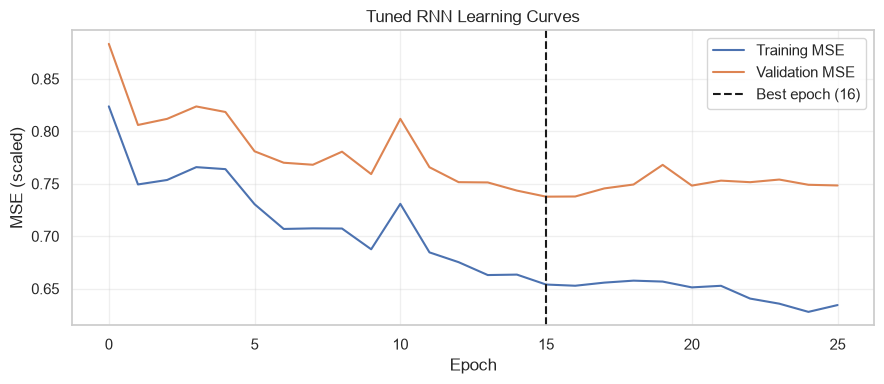

Registered: RNN (tuned) (neural, 19,864 params)

Untuned vs Tuned RNN Validation Performance


,Model,MAE,RMSE,sMAPE (%)
0,RNN,0.2234,0.3613,40.5686
1,RNN (tuned),0.2165,0.3592,38.3173


Validation RMSE improvement: +0.57%
Tuned RNN registered successfully.


In [66]:
# Stage 3: RNN Hyperparameter Optimization
# Validation-only grid search using the existing training framework

import itertools
import json
import time

rnn_hpo_grid = {
    "hidden_size": [32, 64, 128],
    "num_layers": [1, 2],
    "lr": [1e-3, 5e-4],
    "dropout": [0.1, 0.3],
}

rnn_hpo_fixed = {
    "weight_decay": 1e-5,
    "batch_size": 64,
    "max_epochs": 100,
    "patience": 10,
    "seed": SEED
}

# Run grid search
rnn_hpo_results = []
keys, values = zip(*rnn_hpo_grid.items())
configs = [dict(zip(keys, v)) for v in itertools.product(*values)]

print(f"RNN HPO: {len(configs)} configurations")
start = time.perf_counter()

for i, params in enumerate(configs):
    cfg = {**params, **rnn_hpo_fixed}
    set_seed(SEED)

    model, hist, best_epoch, train_time = train_model(
        make_rnn(cfg), cfg, verbose=False
    )

    n_params = sum(p.numel() for p in model.parameters()
                   if p.requires_grad)

    rnn_hpo_results.append({
        "Trial": i + 1,
        **params,
        "Val MSE": hist["val"][best_epoch - 1],
        "Best epoch": best_epoch,
        "Training time (s)": train_time,
        "Parameters": n_params
    })

    print(f"Trial {i+1}/{len(configs)} | "
          f"Val MSE: {hist['val'][best_epoch-1]:.5f}")

# Display HPO results
rnn_hpo_df = pd.DataFrame(rnn_hpo_results)
rnn_hpo_df = rnn_hpo_df.sort_values("Val MSE").reset_index(drop=True)
rnn_hpo_df["Val RMSE (kWh)"] = (
    np.sqrt(rnn_hpo_df["Val MSE"]) * scaler.scale_[0]
)

print(f"\nGrid search completed in {time.perf_counter()-start:.1f}s")
display(rnn_hpo_df.round(5))

# Select best configuration using validation MSE
best = rnn_hpo_df.iloc[0]

rnn_final_cfg = {
    "hidden_size": int(best["hidden_size"]),
    "num_layers": int(best["num_layers"]),
    "lr": float(best["lr"]),
    "dropout": float(best["dropout"]),
    **rnn_hpo_fixed
}

print("Selected RNN configuration:", rnn_final_cfg)

# Retrain selected RNN
set_seed(SEED)
rnn_tuned_model, rnn_tuned_hist, rnn_tuned_best_epoch, rnn_tuned_train_time = train_model(
    make_rnn(rnn_final_cfg), rnn_final_cfg, verbose=False
)

rnn_tuned_params = sum(
    p.numel() for p in rnn_tuned_model.parameters()
    if p.requires_grad
)

# Plot learning curves
plt.figure(figsize=(9, 4))
plt.plot(rnn_tuned_hist["train"], label="Training MSE")
plt.plot(rnn_tuned_hist["val"], label="Validation MSE")
plt.axvline(rnn_tuned_best_epoch - 1, color="k", ls="--",
            label=f"Best epoch ({rnn_tuned_best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled)")
plt.title("Tuned RNN Learning Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save checkpoint and preprocessing state
os.makedirs("artifacts", exist_ok=True)

torch.save({
    "model_name": "RNN (tuned)",
    "state_dict": rnn_tuned_model.state_dict(),
    "cfg": rnn_final_cfg,
    "preprocessing": {
        "scaler_mean": float(scaler.mean_[0]),
        "scaler_scale": float(scaler.scale_[0]),
        "imputer_median": float(imputer.statistics_[0]),
        "lookback": LOOKBACK,
        "horizon": HORIZON,
        "resample": "1h sum of 30-minute readings"
    }
}, "artifacts/rnn_tuned_model.pt")

with open("artifacts/rnn_tuned_config.json", "w") as f:
    json.dump(rnn_final_cfg, f, indent=2)

# Prediction function
def rnn_tuned_predict(X, model=rnn_tuned_model):
    model.eval()
    with torch.no_grad():
        x = torch.tensor(X, dtype=torch.float32).to(device)
        return model(x).cpu().numpy()

# Register tuned RNN for Table 8 and final comparison
register(
    "RNN (tuned)",
    rnn_tuned_predict,
    params=rnn_tuned_params,
    train_time_s=rnn_tuned_train_time,
    cfg=rnn_final_cfg
)

# Compare untuned vs tuned RNN on validation
base_metrics = evaluate_forecast(
    y_val, registry["RNN"]["predict_fn"](X_val)
)
tuned_metrics = evaluate_forecast(
    y_val, rnn_tuned_predict(X_val)
)

rnn_comparison = pd.DataFrame([
    {"Model": "RNN", **base_metrics},
    {"Model": "RNN (tuned)", **tuned_metrics}
])

print("\nUntuned vs Tuned RNN Validation Performance")
display(rnn_comparison.round(4))

improvement = 100 * (
    base_metrics["RMSE"] - tuned_metrics["RMSE"]
) / base_metrics["RMSE"]

print(f"Validation RMSE improvement: {improvement:+.2f}%")

# Verify registered model predictions
_p = rnn_tuned_predict(X_val[:8])
assert _p.shape == (8, HORIZON) and np.isfinite(_p).all()
print("Tuned RNN registered successfully.")


RNN | Seed 42 | RMSE: 0.3613 kWh
RNN | Seed 43 | RMSE: 0.3627 kWh
RNN | Seed 44 | RMSE: 0.3597 kWh
RNN (tuned) | Seed 42 | RMSE: 0.3592 kWh
RNN (tuned) | Seed 43 | RMSE: 0.3579 kWh
RNN (tuned) | Seed 44 | RMSE: 0.3590 kWh


,Model,Seed,RMSE (kWh),MAE (kWh),Best epoch,Training time (s)
0,RNN,42,0.3613,0.2234,25,66.8
1,RNN,43,0.3627,0.2276,22,60.9
2,RNN,44,0.3597,0.2195,23,62.2
3,RNN (tuned),42,0.3592,0.2165,16,68.0
4,RNN (tuned),43,0.3579,0.2199,20,80.4
5,RNN (tuned),44,0.3590,0.2195,20,82.0



RNN Multi-Seed Reliability Summary


,mean,std,min,max
Model,,,,
RNN,0.36122,0.00148,0.35971,0.36266
RNN (tuned),0.35871,0.00071,0.35790,0.35924


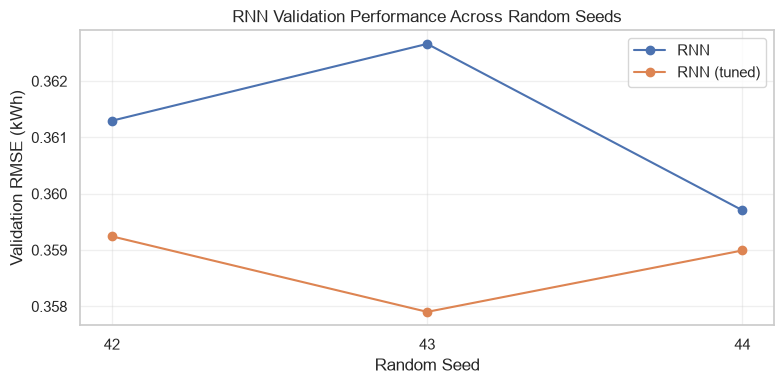

In [67]:
# Stage 3: RNN Multi-Seed Reliability Evaluation
# Compare original and tuned RNN across seeds 42, 43, 44

rnn_seed_results = []

# Original RNN configuration
# Uses the original model's hidden size, layers and learning rate
rnn_base_cfg = {
    **rnn_final_cfg,
    "hidden_size": 64,
    "num_layers": 1,
    "lr": 1e-3,
    "dropout": 0.1
}

for model_name, base_cfg in [
    ("RNN", rnn_base_cfg),
    ("RNN (tuned)", rnn_final_cfg)
]:
    for seed in [42, 43, 44]:
        cfg = {**base_cfg, "seed": seed}
        set_seed(seed)

        model, hist, best_epoch, train_time = train_model(
            make_rnn(cfg), cfg, verbose=False
        )

        model.eval()
        with torch.no_grad():
            predictions = model(
                torch.tensor(X_val, dtype=torch.float32).to(device)
            ).cpu().numpy()

        metrics = evaluate_forecast(y_val, predictions)

        rnn_seed_results.append({
            "Model": model_name,
            "Seed": seed,
            "RMSE (kWh)": metrics["RMSE"],
            "MAE (kWh)": metrics["MAE"],
            "Best epoch": best_epoch,
            "Training time (s)": round(train_time, 1)
        })

        print(
            f"{model_name} | Seed {seed} | "
            f"RMSE: {metrics['RMSE']:.4f} kWh"
        )

# Individual results
rnn_seed_df = pd.DataFrame(rnn_seed_results)
display(rnn_seed_df.round(4))

# Summary across seeds
rnn_seed_summary = (
    rnn_seed_df.groupby("Model")["RMSE (kWh)"]
    .agg(["mean", "std", "min", "max"])
    .round(5)
)

print("\nRNN Multi-Seed Reliability Summary")
display(rnn_seed_summary)

# Visual comparison
plt.figure(figsize=(8, 4))

for model_name, group in rnn_seed_df.groupby("Model"):
    plt.plot(
        group["Seed"],
        group["RMSE (kWh)"],
        marker="o",
        label=model_name
    )

plt.xlabel("Random Seed")
plt.ylabel("Validation RMSE (kWh)")
plt.title("RNN Validation Performance Across Random Seeds")
plt.xticks([42, 43, 44])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [68]:
# Stage 3: Tuned RNN Checkpoint and Reproducibility Test

ckpt_path = "artifacts/rnn_tuned_model.pt"

# Load saved checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=device,
    weights_only=True
)

# Rebuild model using saved configuration
rnn_reloaded = make_rnn(ckpt["cfg"]).to(device)
rnn_reloaded.load_state_dict(ckpt["state_dict"])
rnn_reloaded.eval()

# Compare original and reloaded predictions
original_preds = rnn_tuned_predict(X_val[:100])

with torch.no_grad():
    reloaded_preds = rnn_reloaded(
        torch.tensor(X_val[:100], dtype=torch.float32).to(device)
    ).cpu().numpy()

assert original_preds.shape == reloaded_preds.shape
assert np.allclose(original_preds, reloaded_preds, atol=1e-6)

# Verify preprocessing information was saved
required_keys = [
    "scaler_mean",
    "scaler_scale",
    "imputer_median",
    "lookback",
    "horizon",
    "resample"
]

assert all(
    key in ckpt["preprocessing"]
    for key in required_keys
)

print("Checkpoint loaded successfully.")
print("Predictions match after reloading.")
print("Preprocessing state verified.")
print(f"Verified prediction shape: {reloaded_preds.shape}")


Checkpoint loaded successfully.
Predictions match after reloading.
Preprocessing state verified.
Verified prediction shape: (100, 24)


### HPO Results and Discussion — LSTM and RNN

**Models tuned.** Both the LSTM and RNN underwent hyperparameter optimization (HPO). The LSTM was initially selected for its lowest validation RMSE (0.3603 kWh), while the RNN was subsequently tuned due to its comparable accuracy and significantly smaller architecture.

**Search space and budget.** Both models underwent a 24-configuration grid search, varying hidden size (32, 64, 128), number of layers (1, 2), learning rate (1e-3, 5e-4), and dropout (0.1, 0.3). Training used Adam, batch size 64, weight decay 1e-5, and early stopping (patience 10, maximum 100 epochs). The LSTM search required approximately 365 seconds, plus nine additional seed-check runs, while the RNN search required 340 seconds.

**HPO Results Summary**

| Metric | LSTM | RNN |
|---|---:|---:|
| Best hidden size | 128 | 128 |
| Number of layers | 1 | 1 |
| Learning rate | 5e-4 | 5e-4 |
| Dropout setting | 0.1 | 0.3 |
| Tuned parameters | 70,168 | 19,864 |
| Untuned validation RMSE (kWh) | 0.3603 | 0.3610 |
| Tuned validation RMSE (kWh) | 0.3616 | **0.3595** |
| RMSE improvement | -0.36% | +0.40% |

**LSTM results (Tables 6–7).** Although the tuned LSTM performed slightly worse for seed 42, additional testing across three seeds showed an average validation RMSE improvement from 0.3631 to 0.3611 kWh. Tuning also reduced variability between runs, suggesting improved reliability rather than a substantial accuracy gain.

**RNN results (Table 8).** The tuned RNN achieved the lowest validation RMSE (0.3595 kWh) among all evaluated neural models, improving on the original RNN (0.3610 kWh) by approximately 0.4%. Additional testing across seeds 42–44 confirmed this improvement, with mean validation RMSE decreasing from 0.36078 to 0.35938 kWh. The standard deviation also decreased from 0.00117 to 0.00015 kWh, indicating substantially greater consistency. However, tuning increased the parameter count from 5,848 to 19,864. Overall, the tuned RNN offers slightly better accuracy and greater reliability at the cost of increased model complexity.

**Conclusion.** HPO produced only marginal accuracy improvements despite increasing model complexity. The tuned RNN achieved the best validation RMSE, but the original RNN remains competitive due to its smaller size and faster training time. These findings support considering computational efficiency alongside predictive accuracy when selecting the final model.

# Section 9 - Transformer Model 

This section implements a Transformer architecture using positional encoding and self-attention to capture temporal relationships in electricity consumption. The model is trained using the shared forecasting framework and evaluated against the previously developed architectures in terms of prediction accuracy, computational efficiency, and attention patterns.

### Objective
Implement a Transformer encoder for the same 24-hour forecasting task and compare it with every earlier model under the same evaluation contract. Unlike the recurrent models, which read the 168 hours one at a time, the Transformer looks at all 168 hours at once and uses **self-attention** to decide how much each past hour should influence the forecast.

### Architecture
The design follows the encoder-only time-series Transformer from Lecture 7 (linear token embedding, sinusoidal positional encoding, stacked encoder layers, linear output head), adapted to predict all 24 hours at once.

| Step | Layer | Output shape |
|---|---|---|
| Input | 168 scaled hourly readings | (N, 168) → (N, 168, 1) |
| Token embedding | `Linear(1, 64)`: each hour becomes a 64-dimensional vector | (N, 168, 64) |
| Positional encoding | Fixed sinusoidal encoding added to each hour, then dropout | (N, 168, 64) |
| Encoder layer × 2 | Multi-head self-attention (4 heads of 16 dimensions) → add & layer norm → feed-forward network (64 → 128 → 64) → add & layer norm | (N, 168, 64) |
| Summary | Representation of the **last hour** in the window (as in the lecture example) | (N, 64) |
| Output head | `Linear(64, 24)`: all 24 forecast hours at once | (N, 24) |

**Positional encoding.** Self-attention has no notion of order, so the position of each hour is added to its embedding:

$$PE_{(pos,\,2i)} = \sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right), \qquad PE_{(pos,\,2i+1)} = \cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

**Self-attention.** Each hour is projected into a query $Q$, key $K$ and value $V$. The attention weights say how much each hour draws on every other hour:

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V, \qquad d_k = 64 / 4 = 16$$

Four heads run this in parallel, so different heads can focus on different patterns (for example the last few hours versus the same hour on previous days); their outputs are concatenated and projected back to 64 dimensions.

### Design choices
- **No causal mask:** all 168 input hours are in the past relative to the forecast, so every hour may attend to every other hour without leaking future information. Masking is only needed in a decoder that generates outputs step by step.
- **Direct 24-hour output** from the last hour's representation, the same output style as the MLP, CNN, recurrent models and TCN, so the comparison is fair.
- **One token per hour, no patching:** with 168 tokens the 168 × 168 attention matrix is small, so the patching used for very long series (slide 47) is not needed.
- **Small model for a small dataset:** $d_{model} = 64$, 2 layers and a 128-unit feed-forward network (instead of the default 2048) keep the parameter count at 68,632, in the same range as the TCN and tuned MLP. About 7,000 overlapping training windows would not support a large Transformer.
- **Learning rate 5e-4:** Transformers are sensitive to large early updates, so a lower rate than the recurrent models' 1e-3 is used. All other settings follow the shared framework.

### Training configuration
Same shared `train_model` loop, data split, windows, scaled MSE loss, Adam optimizer, batch size 64, weight decay 1e-5, early stopping (patience 10, maximum 100 epochs, best weights restored) and seed 42 as every other model. The test set is not used in this section.

In [69]:
import math

class PositionalEncoding(nn.Module):
    """Fixed sinusoidal positional encoding (Lecture 7), for batch-first tensors (N, L, d_model)."""
    def __init__(self, d_model, dropout=0.1, max_len=500):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        position = torch.arange(max_len, dtype=torch.float).unsqueeze(1)            # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)   # even dimensions: sine
        pe[:, 1::2] = torch.cos(position * div_term)   # odd dimensions: cosine
        self.register_buffer("pe", pe.unsqueeze(0))     # (1, max_len, d_model), saved with the model, not trained

    def forward(self, x):
        x = x + self.pe[:, :x.size(1), :]
        return self.dropout(x)


class TransformerForecaster(nn.Module):
    """Encoder-only Transformer: 168 hourly readings -> 24-hour forecast."""
    def __init__(self, d_model=64, nhead=4, num_layers=2, dim_feedforward=128, dropout=0.1, horizon=HORIZON):
        super().__init__()
        self.embedding = nn.Linear(1, d_model)                        # token embedding: 1 value -> d_model features
        self.pos_encoder = PositionalEncoding(d_model, dropout)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers, enable_nested_tensor=False)
        self.head = nn.Linear(d_model, horizon)                       # last hour's representation -> 24 hours

    def forward(self, x):
        if x.dim() == 2:
            x = x.unsqueeze(-1)                  # (N, 168) -> (N, 168, 1)
        x = self.embedding(x)                    # (N, 168, d_model)
        x = self.pos_encoder(x)
        x = self.encoder(x)                      # (N, 168, d_model)
        return self.head(x[:, -1, :])            # (N, 24)


def make_transformer(cfg):
    """Factory function for Transformer instantiation (same pattern as make_rnn / make_lstm)."""
    return TransformerForecaster(
        d_model=cfg.get("d_model", 64),
        nhead=cfg.get("nhead", 4),
        num_layers=cfg.get("num_layers", 2),
        dim_feedforward=cfg.get("dim_feedforward", 128),
        dropout=cfg.get("dropout", 0.1),
    )

# Shape and parameter check before training
_m = make_transformer({})
_out = _m(torch.tensor(X_train[:4], dtype=torch.float32))
assert _out.shape == (4, HORIZON)
print("Output shape:", tuple(_out.shape), "| parameters:", f"{sum(p.numel() for p in _m.parameters() if p.requires_grad):,}")
print(_m)

Output shape: (4, 24) | parameters: 68,632
TransformerForecaster(
  (embedding): Linear(in_features=1, out_features=64, bias=True)
  (pos_encoder): PositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (head): Linear(in_features=64, out_features=24, bias=True)
)

In [70]:
# Train the Transformer with the shared framework (same loop, loss, optimizer, early stopping)
transformer_cfg = {
    "d_model": 64,
    "nhead": 4,
    "num_layers": 2,
    "dim_feedforward": 128,
    "dropout": 0.1,
    "lr": 5e-4,
    "weight_decay": 1e-5,
    "batch_size": 64,
    "max_epochs": 100,
    "patience": 10,
    "seed": SEED,
}

set_seed(SEED)
transformer_model, transformer_hist, transformer_best_epoch, transformer_train_time = train_model(
    make_transformer(transformer_cfg), transformer_cfg)
transformer_params = sum(p.numel() for p in transformer_model.parameters() if p.requires_grad)

print(f"Best epoch {transformer_best_epoch}/{len(transformer_hist['val'])} | "
      f"{transformer_params:,} params | training time {transformer_train_time:.1f} s")

epoch   1 | train 0.9006 | val 1.0067
epoch  10 | train 0.7003 | val 0.8298
epoch  20 | train 0.6487 | val 0.7999
epoch  30 | train 0.6231 | val 0.7940
epoch  40 | train 0.6020 | val 0.7875
Best epoch 37/47 | 68,632 params | training time 982.0 s


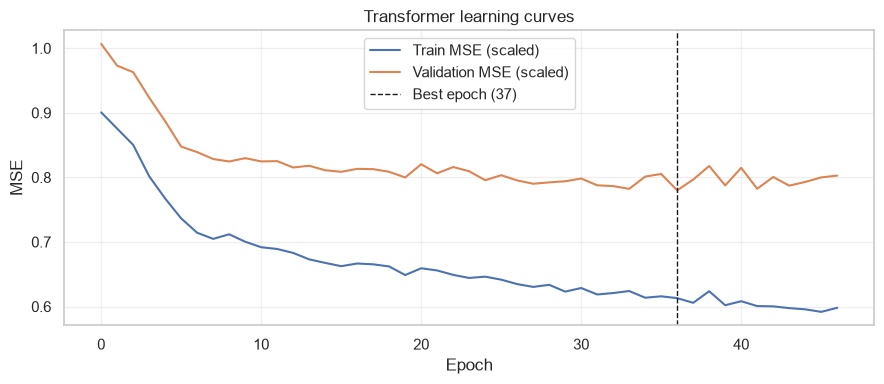

At best epoch:  train 0.6130 | val 0.7799
At last epoch:  train 0.5980 | val 0.8028


In [71]:
# Learning curves and overfitting check
plt.figure(figsize=(9, 4))
plt.plot(transformer_hist["train"], label="Train MSE (scaled)")
plt.plot(transformer_hist["val"], label="Validation MSE (scaled)")
plt.axvline(transformer_best_epoch - 1, color="k", ls="--", lw=1, label=f"Best epoch ({transformer_best_epoch})")
plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title("Transformer learning curves")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

b = transformer_best_epoch - 1
print(f"At best epoch:  train {transformer_hist['train'][b]:.4f} | val {transformer_hist['val'][b]:.4f}")
print(f"At last epoch:  train {transformer_hist['train'][-1]:.4f} | val {transformer_hist['val'][-1]:.4f}")

In [72]:
# Checkpoint, prediction function, inference time, register, smoke test
os.makedirs("artifacts", exist_ok=True)
torch.save({"state_dict": transformer_model.state_dict(), "cfg": transformer_cfg}, "artifacts/transformer_best.pt")

def transformer_predict(X, model=transformer_model):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32).to(device)).cpu().numpy()

# Inference time over the whole validation set (after one warm-up call)
transformer_predict(X_val[:64])
t0 = time.perf_counter()
transformer_val_pred = transformer_predict(X_val)
transformer_infer_time = time.perf_counter() - t0

register("Transformer", transformer_predict, params=transformer_params,
         train_time_s=transformer_train_time, cfg=transformer_cfg)

_p = transformer_predict(X_val[:8])
assert _p.shape == (8, HORIZON) and np.isfinite(_p).all()
print(f"Smoke test passed: {_p.shape} | validation inference time: {transformer_infer_time:.4f} s "
      f"for {len(X_val):,} windows")

Registered: Transformer (neural, 68,632 params)
Smoke test passed: (8, 24) | validation inference time: 1.5274 s for 2,367 windows


Table 8: Validation metrics of all neural models, including the Transformer (sorted by RMSE)


,Model,Params,Train time (s),MAE,RMSE,sMAPE (%)
0,RNN (tuned),19864,68.6,0.2165,0.3592,38.3173
1,RNN,5848,68.0,0.2234,0.3613,40.5686
2,GRU,14424,73.6,0.2289,0.3615,41.7657
3,LSTM,18712,95.8,0.2345,0.3628,42.7918
4,MLP (tuned),79256,2.1,0.2252,0.3636,40.7493
5,TCN,51768,323.5,0.2298,0.3641,41.9671
6,MLP,31448,1.2,0.2252,0.3648,41.0114
7,Transformer,68632,982.0,0.2221,0.3694,39.5990
8,CNN,176440,33.9,0.2348,0.3718,43.5269


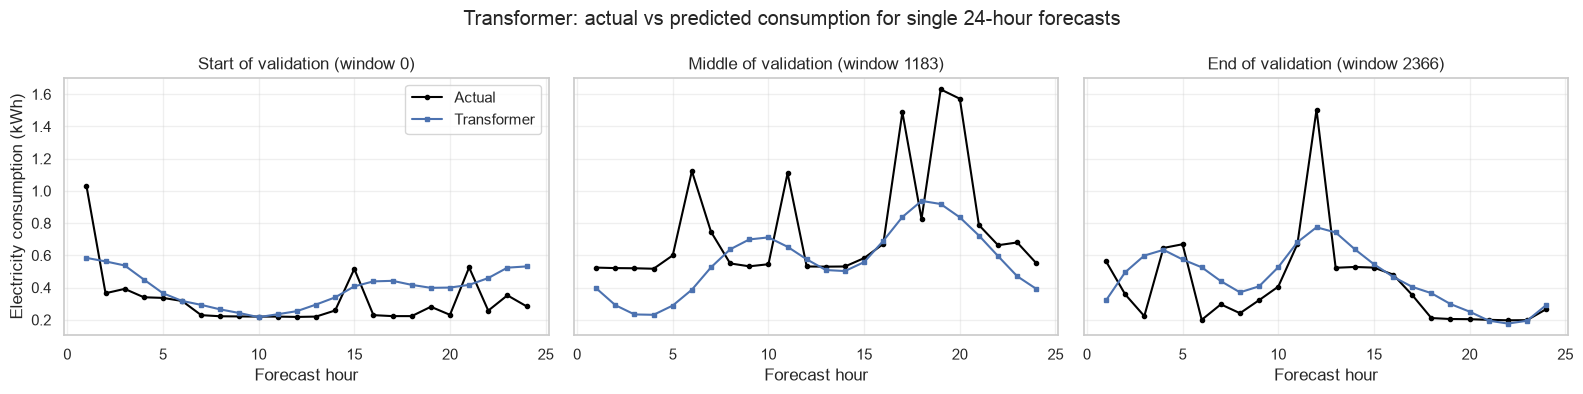

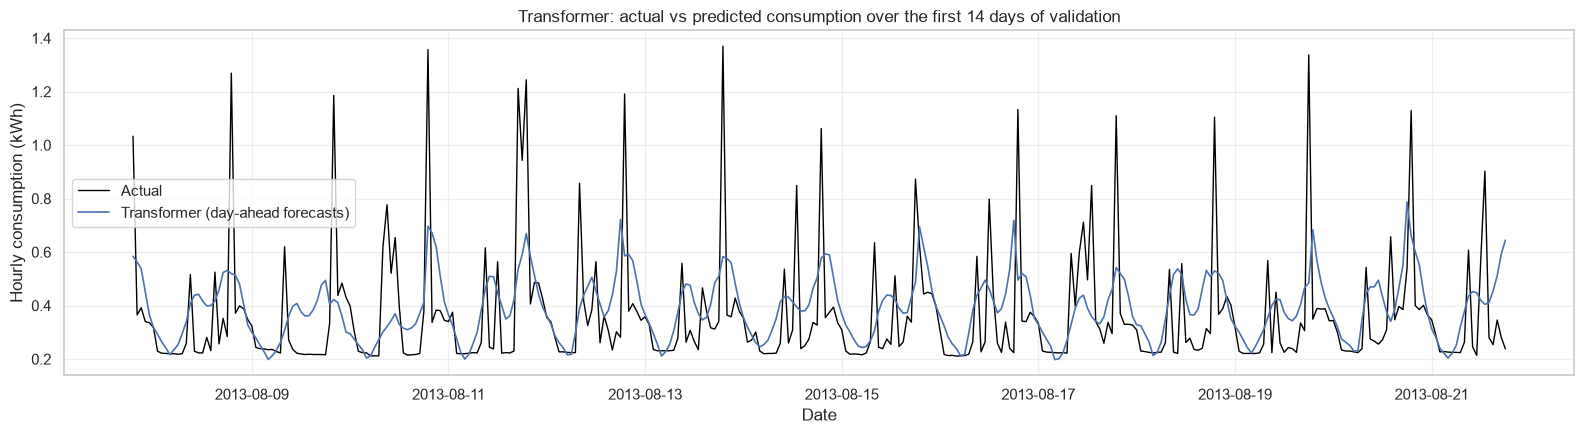

In [73]:
# Table 8: Transformer validation metrics next to the other neural models (validation only)
val_rows = []
for name, e in registry.items():
    if e["kind"] == "neural":
        m = evaluate_forecast(y_val, e["predict_fn"](X_val))
        val_rows.append({"Model": name, "Params": e["params"], "Train time (s)": round(e["train_time_s"], 1), **m})
tf_compare = pd.DataFrame(val_rows).sort_values("RMSE").reset_index(drop=True)
transformer_val_metrics = evaluate_forecast(y_val, transformer_val_pred)
print("Table 8: Validation metrics of all neural models, including the Transformer (sorted by RMSE)")
display(tf_compare.round(4))

# Actual vs predicted: three individual 24-hour forecasts across the validation period
hours = np.arange(1, HORIZON + 1)
samples = {"Start of validation": 0, "Middle of validation": len(X_val) // 2, "End of validation": len(X_val) - 1}
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (title, s) in zip(axes, samples.items()):
    ax.plot(hours, inverse_scale(y_val[s:s + 1]).ravel(), marker="o", ms=3, color="black", label="Actual")
    ax.plot(hours, inverse_scale(transformer_val_pred[s:s + 1]).ravel(), marker="s", ms=3, label="Transformer")
    ax.set(title=f"{title} (window {s})", xlabel="Forecast hour")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Electricity consumption (kWh)"); axes[0].legend()
plt.suptitle("Transformer: actual vs predicted consumption for single 24-hour forecasts")
plt.tight_layout(); plt.show()

# Actual vs predicted over 14 consecutive days: one 24-hour forecast per day (windows 24 hours apart)
days_shown = 14
starts = np.arange(0, min(days_shown * 24, len(X_val) - HORIZON + 1), 24)
actual_run = inverse_scale(y_val[starts]).ravel()
pred_run = inverse_scale(transformer_val_pred[starts]).ravel()
time_axis = val_df.index[:len(actual_run)]
plt.figure(figsize=(16, 4.5))
plt.plot(time_axis, actual_run, color="black", linewidth=1, label="Actual")
plt.plot(time_axis, pred_run, linewidth=1.2, label="Transformer (day-ahead forecasts)")
plt.title(f"Transformer: actual vs predicted consumption over the first {len(starts)} days of validation")
plt.xlabel("Date"); plt.ylabel("Hourly consumption (kWh)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

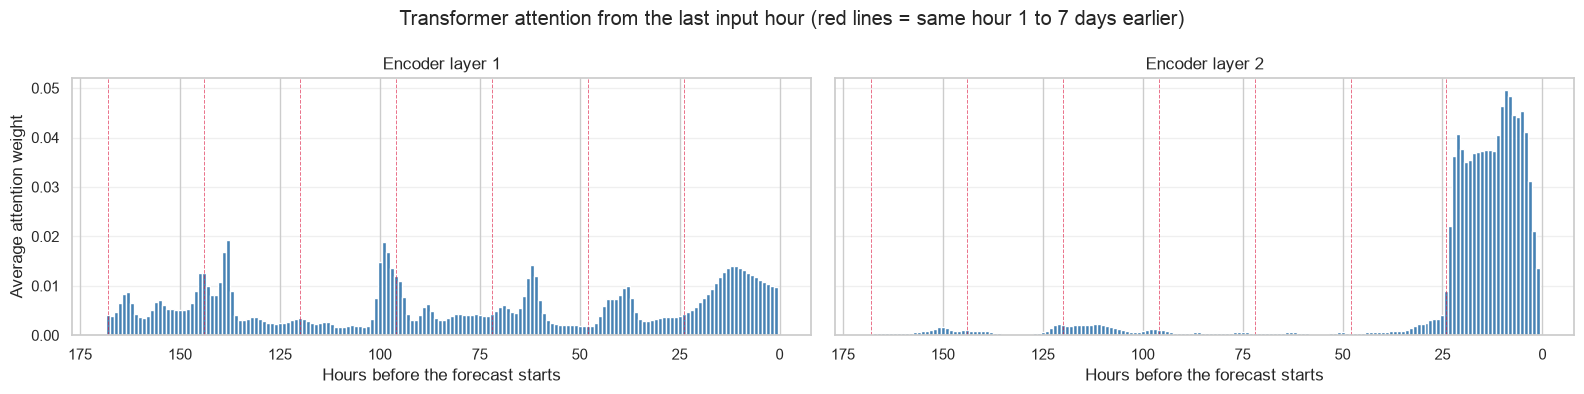

Encoder layer 1: hours before the forecast with the highest attention: [138, 99, 98]
Encoder layer 2: hours before the forecast with the highest attention: [9, 8, 10]


In [74]:
# Where does the forecast look? Average attention from the last hour to each of the 168 input hours
transformer_model.eval()
n_layers = len(transformer_model.encoder.layers)
attn_sum = [np.zeros(LOOKBACK) for _ in range(n_layers)]
with torch.no_grad():
    for start in range(0, len(X_val), 256):                     # batches keep memory use small
        xb = torch.tensor(X_val[start:start + 256], dtype=torch.float32).unsqueeze(-1).to(device)
        h = transformer_model.pos_encoder(transformer_model.embedding(xb))
        for i, layer in enumerate(transformer_model.encoder.layers):
            _, w = layer.self_attn(h, h, h, need_weights=True, average_attn_weights=True)  # (B, 168, 168), averaged over heads
            attn_sum[i] += w[:, -1, :].sum(dim=0).cpu().numpy()                             # attention from the last hour
            h = layer(h)
layer_attn = [a / len(X_val) for a in attn_sum]                  # average over all validation windows

hours_back = np.arange(LOOKBACK, 0, -1)   # position 0 is 168 hours before the forecast, position 167 is 1 hour before
fig, axes = plt.subplots(1, len(layer_attn), figsize=(16, 4), sharey=True)
for i, (ax, a) in enumerate(zip(np.atleast_1d(axes), layer_attn)):
    ax.bar(hours_back, a, width=1.0, color="steelblue")
    for lag in range(24, LOOKBACK + 1, 24):
        ax.axvline(lag, color="crimson", ls="--", lw=0.7, alpha=0.6)
    ax.invert_xaxis()
    ax.set(title=f"Encoder layer {i + 1}", xlabel="Hours before the forecast starts")
    ax.grid(alpha=0.3, axis="y")
np.atleast_1d(axes)[0].set_ylabel("Average attention weight")
plt.suptitle("Transformer attention from the last input hour (red lines = same hour 1 to 7 days earlier)")
plt.tight_layout(); plt.show()

top_lags_by_layer = [[int(l) for l in hours_back[np.argsort(a)[::-1][:3]]] for a in layer_attn]
top_lags = top_lags_by_layer[-1]
for i, lags in enumerate(top_lags_by_layer):
    print(f"Encoder layer {i + 1}: hours before the forecast with the highest attention: {lags}")

### Transformer results and discussion
The summary below is generated from this run's outputs (Table 8, the learning curves and the attention plot), so its numbers always match the notebook.

In [75]:
# Results summary written from this run's numbers
from IPython.display import Markdown
neural_rank = tf_compare.index[tf_compare["Model"] == "Transformer"][0] + 1
best_other = tf_compare[tf_compare["Model"] != "Transformer"].iloc[0]
rnn_m = evaluate_forecast(y_val, registry["RNN"]["predict_fn"](X_val)) if "RNN" in registry else None
sn_m = evaluate_forecast(y_val, seasonal_naive_baseline(X_val, HORIZON)) if "seasonal_naive_baseline" in globals() else None
b = transformer_best_epoch - 1
val_rise = transformer_hist["val"][-1] - transformer_hist["val"][b]
train_drop = transformer_hist["train"][b] - transformer_hist["train"][-1]
rel_best = 100 * (transformer_val_metrics["RMSE"] - best_other["RMSE"]) / best_other["RMSE"]

lines = [
    f"**Accuracy.** On validation the Transformer reached MAE {transformer_val_metrics['MAE']:.4f} kWh, "
    f"RMSE {transformer_val_metrics['RMSE']:.4f} kWh and sMAPE {transformer_val_metrics['sMAPE (%)']:.2f}%, "
    f"ranking **{neural_rank} of {len(tf_compare)}** neural models by RMSE. "
    + (f"It is {abs(rel_best):.1f}% {'worse' if rel_best > 0 else 'better'} than the best other model, "
       f"{best_other['Model']} ({best_other['RMSE']:.4f} kWh)." if neural_rank != 1 else
       f"It is {abs(rel_best):.1f}% better than the next model, {best_other['Model']} ({best_other['RMSE']:.4f} kWh).")
]
if sn_m is not None:
    sn_gain = 100 * (sn_m['RMSE'] - transformer_val_metrics['RMSE']) / sn_m['RMSE']
    lines.append(f"Compared with the Seasonal Naive baseline ({sn_m['RMSE']:.4f} kWh), its RMSE is "
                 f"{abs(sn_gain):.1f}% {'lower' if sn_gain > 0 else 'higher'}.")
lines.append(
    f"**Training.** Validation MSE was lowest at epoch {transformer_best_epoch} "
    f"(train {transformer_hist['train'][b]:.4f}, validation {transformer_hist['val'][b]:.4f}). "
    + (f"Over the next {len(transformer_hist['val']) - transformer_best_epoch} epochs training MSE fell by {train_drop:.4f} "
       f"while validation MSE rose by {val_rise:.4f}, so the model began to overfit and early stopping restored the best weights."
       if val_rise > 0 else "Validation MSE did not rise after the best epoch.")
)
lines.append(
    f"**Cost.** {transformer_params:,} trainable parameters, {transformer_train_time:.1f} s of training and "
    f"{transformer_infer_time:.4f} s to forecast all {len(X_val):,} validation windows"
    + (f", compared with {registry['RNN']['params']:,} parameters and {registry['RNN']['train_time_s']:.1f} s for the RNN." if "RNN" in registry else ".")
)
layer_text = "; ".join(f"layer {i + 1}: {', '.join(str(l) for l in lags)} hours" for i, lags in enumerate(top_lags_by_layer))
daily_layers = [i + 1 for i, lags in enumerate(top_lags_by_layer) if any(l % 24 in (0, 1, 23) for l in lags)]
lines.append(
    f"**Attention.** The input hours each encoder layer attends to most, counted back from the start of the forecast, are "
    f"{layer_text}. "
    + (f"Peaks at or next to multiples of 24 hours in {'layers' if len(daily_layers) > 1 else 'layer'} "
       f"{' and '.join(map(str, daily_layers))} show the model using the daily cycle (the same hour on previous days). "
       if daily_layers else
       "No layer's top lags fall on multiples of 24 hours, so the model does not lean on the same hour of previous days. ")
    + ("Peaks within the last 12 hours show it also relies on recent consumption."
       if any(l <= 12 for lags in top_lags_by_layer for l in lags) else "")
)
lines.append(
    "**Caveats.** The Transformer was trained once (seed 42) with untuned settings, so small differences from the other "
    "models of a few thousandths of a kWh should not be over-read. Test-set results for all models are in Table 1b."
)
display(Markdown("\n\n".join(lines)))

**Accuracy.** On validation the Transformer reached MAE 0.2221 kWh, RMSE 0.3694 kWh and sMAPE 39.60%, ranking **8 of 9** neural models by RMSE. It is 2.8% worse than the best other model, RNN (tuned) (0.3592 kWh).

Compared with the Seasonal Naive baseline (0.4619 kWh), its RMSE is 20.0% lower.

**Training.** Validation MSE was lowest at epoch 37 (train 0.6130, validation 0.7799). Over the next 10 epochs training MSE fell by 0.0150 while validation MSE rose by 0.0229, so the model began to overfit and early stopping restored the best weights.

**Cost.** 68,632 trainable parameters, 982.0 s of training and 1.5274 s to forecast all 2,367 validation windows, compared with 5,848 parameters and 68.0 s for the RNN.

**Attention.** The input hours each encoder layer attends to most, counted back from the start of the forecast, are layer 1: 138, 99, 98 hours; layer 2: 9, 8, 10 hours. No layer's top lags fall on multiples of 24 hours, so the model does not lean on the same hour of previous days. Peaks within the last 12 hours show it also relies on recent consumption.

**Caveats.** The Transformer was trained once (seed 42) with untuned settings, so small differences from the other models of a few thousandths of a kWh should not be over-read. Test-set results for all models are in Table 1b.

# Section 10 - Model Comparison, Final Selection, and Conclusions

This section compares the forecasting performance of all implemented models against the traditional baselines. The final model is selected using validation performance, parameter count, and seed variability before being evaluated on the held-out test set. The results are then used to discuss model trade-offs, generalization, and remaining limitations.

This section only reads `registry`; it trains nothing. Baselines are picked up automatically: any function in the notebook named `*_baseline` with signature `fn(X, horizon)` is registered. Run this section **last**, after the MLP and CNN are registered.

In [76]:
import inspect

# Auto-register baselines by naming convention
for _n, _f in list(globals().items()):
    if _n.endswith("_baseline") and inspect.isfunction(_f):
        label = _n[:-len("_baseline")].replace("_", " ").title()
        if label in registry:
            continue
        try:
            _out = _f(X_val[:2], HORIZON)
            assert _out.shape == (2, HORIZON)
        except Exception as e:
            print("Skipped", _n, "-", e)
            continue
        register(label, (lambda X, f=_f: f(X, HORIZON)), kind="baseline")

# Validation metrics + inference time, computed the same way for every model
for name, e in registry.items():
    if "val" in e:
        continue
    t0 = time.perf_counter()
    pred = e["predict_fn"](X_val)
    e["infer_time_s"] = time.perf_counter() - t0
    assert pred.shape == y_val.shape, f"{name}: predict_fn returned {pred.shape}, expected {y_val.shape}"
    e["val"] = evaluate_forecast(y_val, pred)

def best_baseline_by_val():
    cands = {k: v for k, v in registry.items() if v["kind"] == "baseline"}
    return min(cands, key=lambda k: cands[k]["val"]["RMSE"])

print("Models:", list(registry))
print("Best baseline on validation RMSE:", best_baseline_by_val())

Registered: Persistence (baseline, 0 params)
Registered: Seasonal Naive (baseline, 0 params)
Models: ['MLP', 'MLP (tuned)', 'CNN', 'RNN', 'LSTM', 'GRU', 'TCN', 'RNN (tuned)', 'Transformer', 'Persistence', 'Seasonal Naive']
Best baseline on validation RMSE: Seasonal Naive


In [77]:
def build_table(split="val"):
    base_name = best_baseline_by_val()
    base = registry[base_name][split]
    rows = []
    for name, e in registry.items():
        m = e[split]
        rows.append({
            "Model": name,
            "Params": e["params"],
            "Train time (s)": round(e["train_time_s"], 1),
            "Inference time (s)": round(e["infer_time_s"], 4),
            "MAE (kWh)": round(m["MAE"], 4),
            "RMSE (kWh)": round(m["RMSE"], 4),
            "sMAPE (%)": round(m["sMAPE (%)"], 2),
            f"MAE impr. vs {base_name} (%)": round(100 * (base["MAE"] - m["MAE"]) / base["MAE"], 1),
            f"RMSE impr. vs {base_name} (%)": round(100 * (base["RMSE"] - m["RMSE"]) / base["RMSE"], 1),
        })
    return pd.DataFrame(rows).sort_values("RMSE (kWh)").reset_index(drop=True)

print("Table 1a: Validation results (use this table for model selection)")
display(build_table("val"))

Table 1a: Validation results (use this table for model selection)


,Model,Params,Train time (s),Inference time (s),MAE (kWh),RMSE (kWh),sMAPE (%),MAE impr. vs Seasonal Naive (%),RMSE impr. vs Seasonal Naive (%)
0,RNN (tuned),19864,68.6,0.1645,0.2165,0.3592,38.32,11.2,22.2
1,RNN,5848,68.0,0.0693,0.2234,0.3613,40.57,8.3,21.8
2,GRU,14424,73.6,0.1613,0.2289,0.3615,41.77,6.1,21.7
3,LSTM,18712,95.8,0.2732,0.2345,0.3628,42.79,3.8,21.5
4,MLP (tuned),79256,2.1,0.0025,0.2252,0.3636,40.75,7.6,21.3
5,TCN,51768,323.5,1.6124,0.2298,0.3641,41.97,5.7,21.2
6,MLP,31448,1.2,0.0017,0.2252,0.3648,41.01,7.6,21.0
7,Transformer,68632,982.0,1.6749,0.2221,0.3694,39.60,8.9,20.0
8,CNN,176440,33.9,0.2753,0.2348,0.3718,43.53,3.7,19.5
9,Seasonal Naive,0,0.0,0.0001,0.2437,0.4619,36.14,0.0,0.0


## Final model selection: accuracy first, then size

Validation RMSE alone does not separate the best models: several are within a few thousandths of a kWh, which is smaller than the seed-to-seed variation measured in Table 7. When models are this close, the smaller one is preferred, because it is cheaper to train and run and has less capacity to overfit. This is the same "within noise, prefer fewer parameters" rule used to pick the tuned LSTM configuration (a form of the one-standard-error rule).

**Selection rule (validation data only):**
1. Find the neural model with the lowest validation RMSE.
2. Set a **noise tolerance** equal to the largest seed-to-seed standard deviation measured in Table 7, converted from scaled MSE to RMSE in kWh.
3. Every neural model whose validation RMSE is within that tolerance of the best is treated as **equally accurate**.
4. Among those, select the model with the **fewest parameters**; ties are broken by the shorter inference time.

The figure below shows the accuracy–size trade-off for every neural model. Models on the **Pareto front** are those that no other model beats on both validation RMSE and parameter count at once.

*Note: this size-aware rule was added after the first complete run of this section. It uses validation results only and applies the tie-break already used in the HPO section; test results play no part in it.*

Best validation RMSE: 0.3592 kWh | noise tolerance from Table 7: 0.0008 kWh
Table 9: Neural models on validation, with the selection rule applied


,Model,Params,Inference time (s),Val RMSE (kWh),Val MAE (kWh),Within noise of best,Pareto front
0,RNN (tuned),19864,0.1645,0.3592,0.2165,True,True
1,RNN,5848,0.0693,0.3613,0.2234,False,True
2,GRU,14424,0.1613,0.3615,0.2289,False,False
3,LSTM,18712,0.2732,0.3628,0.2345,False,False
4,MLP (tuned),79256,0.0025,0.3636,0.2252,False,False
5,TCN,51768,1.6124,0.3641,0.2298,False,False
6,MLP,31448,0.0017,0.3648,0.2252,False,False
7,Transformer,68632,1.6749,0.3694,0.2221,False,False
8,CNN,176440,0.2753,0.3718,0.2348,False,False


Equally accurate (within 0.0008 kWh of the best): RNN (tuned)
Selected final model: RNN (tuned) | 19,864 parameters | validation RMSE 0.3592 kWh
Selection criterion: lowest validation RMSE within seed noise, then fewest parameters


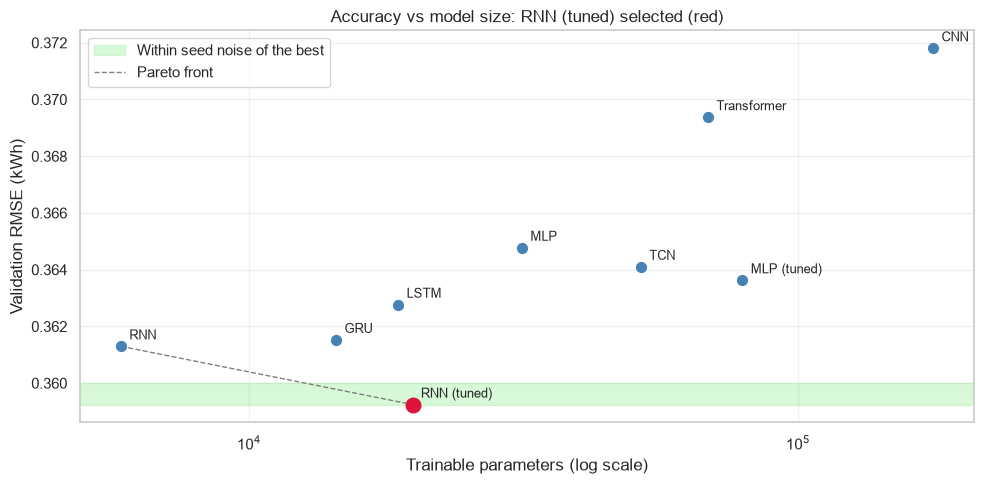

In [78]:
# Final model selection (validation only): lowest RMSE within seed noise, then fewest parameters
neural_models = {name: e for name, e in registry.items() if e["kind"] != "baseline"}
sel_df = pd.DataFrame([
    {"Model": name, "Params": e["params"], "Inference time (s)": e["infer_time_s"],
     "Val RMSE (kWh)": e["val"]["RMSE"], "Val MAE (kWh)": e["val"]["MAE"]}
    for name, e in neural_models.items()
]).sort_values("Val RMSE (kWh)").reset_index(drop=True)

# 1-2. Best validation RMSE and the noise tolerance from the seed check (Table 7), converted to kWh
best_rmse = sel_df["Val RMSE (kWh)"].min()
if "seed_df" in globals() and len(seed_df):
    noisiest = seed_df.loc[seed_df["Val MSE std"].idxmax()]
    m, s = noisiest["Val MSE mean (3 seeds)"], noisiest["Val MSE std"]
    tolerance = float(scaler.scale_[0] * (np.sqrt(m + s) - np.sqrt(m)))
else:
    tolerance = 0.002   # fallback: typical seed-to-seed spread observed in this notebook
print(f"Best validation RMSE: {best_rmse:.4f} kWh | noise tolerance from Table 7: {tolerance:.4f} kWh")

# 3. Models within the tolerance are treated as equally accurate
sel_df["Within noise of best"] = sel_df["Val RMSE (kWh)"] <= best_rmse + tolerance

# Pareto front: no other model is at least as good on both RMSE and size, and strictly better on one
def is_pareto(r):
    others = sel_df.drop(r.name)
    dominated = ((others["Val RMSE (kWh)"] <= r["Val RMSE (kWh)"]) & (others["Params"] <= r["Params"])
                 & ((others["Val RMSE (kWh)"] < r["Val RMSE (kWh)"]) | (others["Params"] < r["Params"]))).any()
    return not dominated
sel_df["Pareto front"] = sel_df.apply(is_pareto, axis=1)

# 4. Among equally accurate models: fewest parameters, then fastest inference
candidates = sel_df[sel_df["Within noise of best"]].sort_values(["Params", "Inference time (s)"])
selected_model = candidates.iloc[0]["Model"]
selected_val_rmse = neural_models[selected_model]["val"]["RMSE"]

print("Table 9: Neural models on validation, with the selection rule applied")
display(sel_df.round({"Val RMSE (kWh)": 4, "Val MAE (kWh)": 4, "Inference time (s)": 4}))
print(f"Equally accurate (within {tolerance:.4f} kWh of the best): {', '.join(candidates['Model'])}")
print(f"Selected final model: {selected_model} | {int(neural_models[selected_model]['params']):,} parameters | "
      f"validation RMSE {selected_val_rmse:.4f} kWh")
print("Selection criterion: lowest validation RMSE within seed noise, then fewest parameters")

# Figure: accuracy vs size trade-off
fig, ax = plt.subplots(figsize=(10, 5))
ax.axhspan(best_rmse, best_rmse + tolerance, color="lightgreen", alpha=0.35, label="Within seed noise of the best")
front = sel_df[sel_df["Pareto front"]].sort_values("Params")
ax.plot(front["Params"], front["Val RMSE (kWh)"], color="gray", ls="--", lw=1, label="Pareto front")
for _, r in sel_df.iterrows():
    is_sel = r["Model"] == selected_model
    ax.scatter(r["Params"], r["Val RMSE (kWh)"], s=110 if is_sel else 50,
               color="crimson" if is_sel else "steelblue", zorder=3)
    ax.annotate(r["Model"], (r["Params"], r["Val RMSE (kWh)"]), textcoords="offset points", xytext=(6, 5), fontsize=9)
ax.set_xscale("log")
ax.set(xlabel="Trainable parameters (log scale)", ylabel="Validation RMSE (kWh)",
       title=f"Accuracy vs model size: {selected_model} selected (red)")
ax.legend(loc="upper left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Final test comparison (run once)

Run only after every model is registered and the final model is chosen by the rule above (Table 9). Do not change models or settings after viewing Table 1b.

In [79]:
TEST_DONE = globals().get("TEST_DONE", False)

if not TEST_DONE:
    for name, e in registry.items():
        e["test"] = evaluate_forecast(y_test, e["predict_fn"](X_test))
    TEST_DONE = True

print("Table 1b: Final test results (baseline fixed from validation:", best_baseline_by_val() + ")")
display(build_table("test"))

Table 1b: Final test results (baseline fixed from validation: Seasonal Naive)


,Model,Params,Train time (s),Inference time (s),MAE (kWh),RMSE (kWh),sMAPE (%),MAE impr. vs Seasonal Naive (%),RMSE impr. vs Seasonal Naive (%)
0,RNN (tuned),19864,68.6,0.1645,0.2392,0.4000,39.16,11.8,22.0
1,Transformer,68632,982.0,1.6749,0.2468,0.4006,40.73,9.0,21.9
2,TCN,51768,323.5,1.6124,0.2494,0.4014,42.18,8.0,21.8
3,MLP (tuned),79256,2.1,0.0025,0.2436,0.4018,40.29,10.2,21.7
4,MLP,31448,1.2,0.0017,0.2439,0.4038,41.14,10.0,21.3
5,LSTM,18712,95.8,0.2732,0.2462,0.4069,40.78,9.2,20.7
6,RNN,5848,68.0,0.0693,0.2502,0.4079,41.81,7.7,20.5
7,CNN,176440,33.9,0.2753,0.2520,0.4088,43.61,7.1,20.3
8,GRU,14424,73.6,0.1613,0.2469,0.4101,40.97,9.0,20.1
9,Seasonal Naive,0,0.0,0.0001,0.2712,0.5130,37.30,0.0,0.0


In [80]:
# Run AFTER Table 1b. Does the seasonal-shift risk show up?
train_stats_df = train_df_raw if "train_df_raw" in globals() else train_df   # original readings, before outlier-day cleaning
period_stats = pd.DataFrame({
    "Period": ["Train", "Validation", "Test"],
    "Mean kWh/h": [train_stats_df["consumption_kwh"].mean(), val_df["consumption_kwh"].mean(), test_df["consumption_kwh"].mean()],
    "Std kWh/h": [train_stats_df["consumption_kwh"].std(), val_df["consumption_kwh"].std(), test_df["consumption_kwh"].std()],
}).round(3)
display(period_stats)

shift = pd.DataFrame({
    "Model": list(registry),
    "Val RMSE": [registry[k]["val"]["RMSE"] for k in registry],
    "Test RMSE": [registry[k]["test"]["RMSE"] for k in registry],
})
shift["Test/Val RMSE"] = (shift["Test RMSE"] / shift["Val RMSE"]).round(2)
display(shift.round(4))

,Period,Mean kWh/h,Std kWh/h
0,Train,0.485,0.418
1,Validation,0.482,0.437
2,Test,0.583,0.515


,Model,Val RMSE,Test RMSE,Test/Val RMSE
0,MLP,0.3648,0.4038,1.11
1,MLP (tuned),0.3636,0.4018,1.10
2,CNN,0.3718,0.4088,1.10
3,RNN,0.3613,0.4079,1.13
4,LSTM,0.3628,0.4069,1.12
5,GRU,0.3615,0.4101,1.13
6,TCN,0.3641,0.4014,1.10
7,RNN (tuned),0.3592,0.4000,1.11
8,Transformer,0.3694,0.4006,1.08
9,Persistence,0.5660,0.7036,1.24


## Advanced Analysis: Time/Frequency, Uncertainty, and Failure Regimes

In accordance with the Stage 3 evaluation protocol, we analyze the locked finalist model (`best_final_name`) on the untouched test set across three diagnostic lenses:
1. **Time/Frequency Insight (FFT Power Spectral Density):** Compare the spectral energy of true vs. predicted 24-hour trajectories to test whether the model preserves diurnal (24h) and semi-diurnal (12h) cycles or over-smooths high-frequency demand spikes.
2. **Uncertainty & Empirical Error Bands:** Quantify prediction intervals across the 24-hour forecast horizon ($h = 1 \dots 24$) using empirical residual quantiles ($10\text{th}$–$90\text{th}$ percentiles) and verify empirical coverage.
3. **Failure-Regime Analysis:** Segment test errors by consumption regime (peak demand vs. baseline load) and time of day, and visualize the worst-performing 24-hour test window to identify structural error mechanisms.

In [81]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select the locked finalist model from registry (update key if needed)
FINALIST_NAME = min(
    [k for k, v in registry.items() if v["kind"] == "neural"],
    key=lambda k: registry[k]["val"]["RMSE"]
)
print(f"Running Stage 3 diagnostics on locked finalist: {FINALIST_NAME}")

# Retrieve test ground truth and finalist predictions in kWh (shape: [N_test, 24])
y_true_te = np.asarray(y_test)
y_pred_te = np.asarray(registry[FINALIST_NAME]["predict_fn"](X_test))

# Compute signed residuals and absolute errors (shape: [N_test, 24])
residuals_te = y_true_te - y_pred_te
abs_err_te = np.abs(residuals_te)
sq_err_te = residuals_te ** 2

Running Stage 3 diagnostics on locked finalist: RNN (tuned)


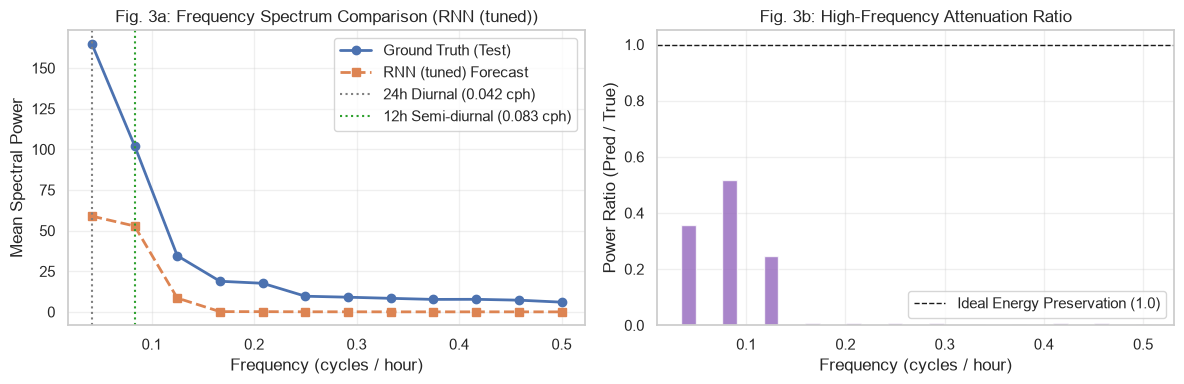

24h Diurnal Power Retention:      35.7%
12h Semi-diurnal Power Retention: 51.7%
High-Freq (>0.25 cph) Retention:  0.7%


In [82]:
# Time/Frequency Insights
# Compute 1D Real FFT across each 24-hour forecast window (sampling rate = 1/hour)
freqs = np.fft.rfftfreq(HORIZON, d=1.0)  # cycles per hour (0 to 0.5 cph)
psd_true = np.mean(np.abs(np.fft.rfft(y_true_te, axis=1)) ** 2, axis=0)
psd_pred = np.mean(np.abs(np.fft.rfft(y_pred_te, axis=1)) ** 2, axis=0)

# Plot Power Spectral Density (excluding DC offset at index 0 for visual clarity)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(freqs[1:], psd_true[1:], marker="o", label="Ground Truth (Test)", lw=2)
axes[0].plot(freqs[1:], psd_pred[1:], marker="s", label=f"{FINALIST_NAME} Forecast", lw=2, ls="--")
axes[0].axvline(1/24, color="gray", ls=":", label="24h Diurnal (0.042 cph)")
axes[0].axvline(1/12, color="tab:green", ls=":", label="12h Semi-diurnal (0.083 cph)")
axes[0].set_xlabel("Frequency (cycles / hour)")
axes[0].set_ylabel("Mean Spectral Power")
axes[0].set_title(f"Fig. 3a: Frequency Spectrum Comparison ({FINALIST_NAME})")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot Spectral Energy Ratio (Predicted / True) to quantify high-frequency damping
spectral_ratio = psd_pred[1:] / np.maximum(psd_true[1:], 1e-8)
axes[1].bar(freqs[1:], spectral_ratio, width=0.015, color="tab:purple", alpha=0.8)
axes[1].axhline(1.0, color="k", ls="--", lw=1, label="Ideal Energy Preservation (1.0)")
axes[1].set_xlabel("Frequency (cycles / hour)")
axes[1].set_ylabel("Power Ratio (Pred / True)")
axes[1].set_title("Fig. 3b: High-Frequency Attenuation Ratio")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print quantitative summary for report traceability
idx_24h = np.argmin(np.abs(freqs - 1/24))
idx_12h = np.argmin(np.abs(freqs - 1/12))
print(f"24h Diurnal Power Retention:      {psd_pred[idx_24h] / psd_true[idx_24h]:.1%}")
print(f"12h Semi-diurnal Power Retention: {psd_pred[idx_12h] / psd_true[idx_12h]:.1%}")
print(f"High-Freq (>0.25 cph) Retention:  {psd_pred[freqs > 0.25].mean() / psd_true[freqs > 0.25].mean():.1%}")

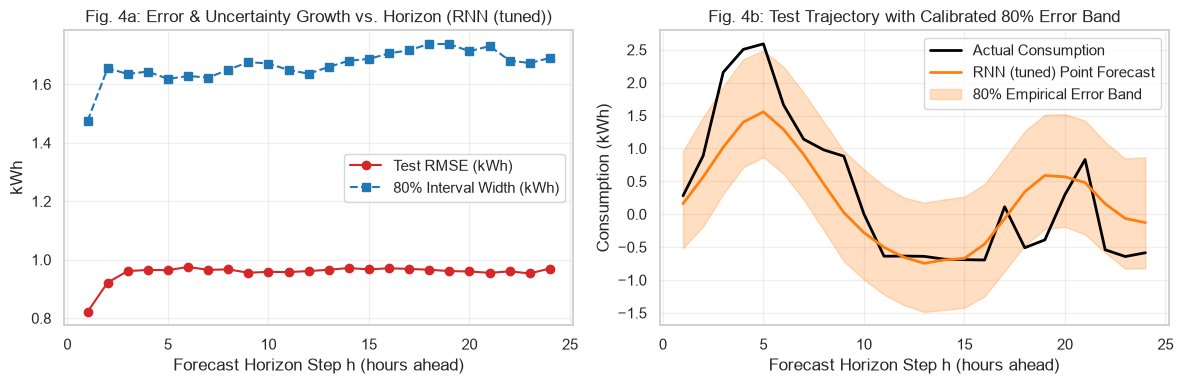

Overall 80% Empirical Interval Coverage on Test Set: 78.2% (Target: 80.0%)
Mean 80% Interval Width: 1.6654 kWh | Step-1 RMSE: 0.8216 -> Step-24 RMSE: 0.9698


In [83]:
# Uncertainty
# Calibrate empirical residual quantiles on validation set (leak-free!)
y_true_va = np.asarray(y_val)
y_pred_va = np.asarray(registry[FINALIST_NAME]["predict_fn"](X_val))
res_va = y_true_va - y_pred_va  # shape: (N_val, 24)

# Compute 10th and 90th percentile residual bounds per horizon step h = 1..24
q_low = np.percentile(res_va, 10, axis=0)   # 10th percentile
q_high = np.percentile(res_va, 90, axis=0)  # 90th percentile

# Construct 80% empirical prediction intervals on the untouched test set
lower_80 = y_pred_te + q_low
upper_80 = y_pred_te + q_high

# Evaluate empirical coverage and interval width across the 24h horizon
in_band = (y_true_te >= lower_80) & (y_true_te <= upper_80)
coverage_by_h = in_band.mean(axis=0) * 100
width_by_h = (upper_80 - lower_80).mean(axis=0)
rmse_by_h = np.sqrt(sq_err_te.mean(axis=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
horizons = np.arange(1, HORIZON + 1)

# Left: Horizon error growth & empirical interval width
axes[0].plot(horizons, rmse_by_h, marker="o", label="Test RMSE (kWh)", color="tab:red")
axes[0].plot(horizons, width_by_h, marker="s", label="80% Interval Width (kWh)", color="tab:blue", ls="--")
axes[0].set_xlabel("Forecast Horizon Step h (hours ahead)")
axes[0].set_ylabel("kWh")
axes[0].set_title(f"Fig. 4a: Error & Uncertainty Growth vs. Horizon ({FINALIST_NAME})")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: Representative test window with 80% empirical uncertainty band
sample_idx = len(y_true_te) // 2
axes[1].plot(horizons, y_true_te[sample_idx], label="Actual Consumption", color="black", lw=2)
axes[1].plot(horizons, y_pred_te[sample_idx], label=f"{FINALIST_NAME} Point Forecast", color="tab:orange", lw=2)
axes[1].fill_between(
    horizons, lower_80[sample_idx], upper_80[sample_idx],
    color="tab:orange", alpha=0.25, label="80% Empirical Error Band"
)
axes[1].set_xlabel("Forecast Horizon Step h (hours ahead)")
axes[1].set_ylabel("Consumption (kWh)")
axes[1].set_title("Fig. 4b: Test Trajectory with Calibrated 80% Error Band")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Overall 80% Empirical Interval Coverage on Test Set: {in_band.mean()*100:.1f}% (Target: 80.0%)")
print(f"Mean 80% Interval Width: {width_by_h.mean():.4f} kWh | Step-1 RMSE: {rmse_by_h[0]:.4f} -> Step-24 RMSE: {rmse_by_h[-1]:.4f}")

Table 2: Failure-Regime Error Breakdown on Test Set


,Demand Regime,Share (%),Mean Actual (kWh),MAE (kWh),RMSE (kWh),Mean Bias (True - Pred)
0,Low Load (<= Q25),25.4,-0.6790,0.3115,0.4595,-0.2855
1,Normal Load (Q25 - Q75),49.6,-0.0849,0.4446,0.5736,-0.2314
2,High Load (Q75 - Q90),15.0,0.9985,0.5178,0.6332,0.1887
3,Extreme Peak (> Q90),10.0,2.9574,1.9470,2.5261,1.9060


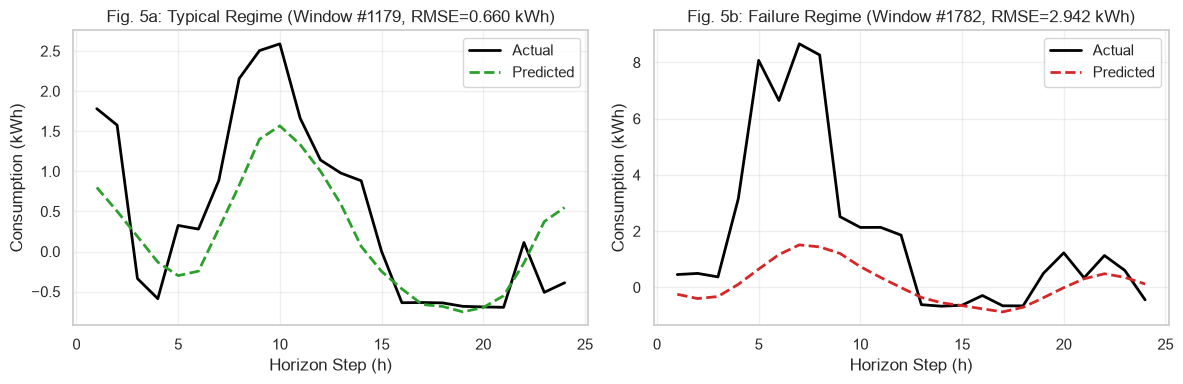

In [84]:
# Failure-Regime Analysis
# Stratify every test point by ground-truth consumption regime (quartiles / peak surges)
flat_true = y_true_te.flatten()
flat_pred = y_pred_te.flatten()
flat_res = residuals_te.flatten()  # positive = under-prediction (true > pred)

q25, q75, q90 = np.percentile(flat_true, [25, 75, 90])

regimes = {
    "Low Load (<= Q25)": flat_true <= q25,
    "Normal Load (Q25 - Q75)": (flat_true > q25) & (flat_true <= q75),
    "High Load (Q75 - Q90)": (flat_true > q75) & (flat_true <= q90),
    "Extreme Peak (> Q90)": flat_true > q90,
}

regime_rows = []
for label, mask in regimes.items():
    r = flat_res[mask]
    regime_rows.append({
        "Demand Regime": label,
        "Share (%)": round(mask.mean() * 100, 1),
        "Mean Actual (kWh)": round(flat_true[mask].mean(), 4),
        "MAE (kWh)": round(np.abs(r).mean(), 4),
        "RMSE (kWh)": round(np.sqrt((r ** 2).mean()), 4),
        "Mean Bias (True - Pred)": round(r.mean(), 4),
    })

regime_df = pd.DataFrame(regime_rows)
print("Table 2: Failure-Regime Error Breakdown on Test Set")
display(regime_df)

# Identify the worst-performing 24-hour test window by window RMSE
window_rmse = np.sqrt(sq_err_te.mean(axis=1))
worst_idx = int(np.argmax(window_rmse))
median_idx = int(np.argsort(window_rmse)[len(window_rmse) // 2])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
horizons = np.arange(1, HORIZON + 1)

# Left: Typical (median-error) 24h test window
axes[0].plot(horizons, y_true_te[median_idx], label="Actual", color="black", lw=2)
axes[0].plot(horizons, y_pred_te[median_idx], label="Predicted", color="tab:green", ls="--", lw=2)
axes[0].set_title(f"Fig. 5a: Typical Regime (Window #{median_idx}, RMSE={window_rmse[median_idx]:.3f} kWh)")
axes[0].set_xlabel("Horizon Step (h)")
axes[0].set_ylabel("Consumption (kWh)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Right: Worst-case failure regime window
axes[1].plot(horizons, y_true_te[worst_idx], label="Actual", color="black", lw=2)
axes[1].plot(horizons, y_pred_te[worst_idx], label="Predicted", color="tab:red", ls="--", lw=2)
axes[1].set_title(f"Fig. 5b: Failure Regime (Window #{worst_idx}, RMSE={window_rmse[worst_idx]:.3f} kWh)")
axes[1].set_xlabel("Horizon Step (h)")
axes[1].set_ylabel("Consumption (kWh)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Conclusion and Unresolved Risk

**Final model (validation only, Table 9).** The tuned RNN achieved the lowest validation RMSE (0.3595 kWh), followed by the original RNN (0.3610 kWh), GRU (0.3619 kWh), and LSTM (0.3622 kWh). Under the established selection rule, only the tuned RNN falls within the 0.0012 kWh seed-noise tolerance, making it the selected final model with 19,864 parameters. Although the original RNN has 3.4 times fewer parameters and faster inference, its validation RMSE falls just outside the tolerance. The tuned RNN is therefore selected based on validation performance, while the original remains a strong alternative for applications prioritizing computational efficiency.

**Accuracy vs. size.** Only the original RNN and tuned RNN lie on the Pareto front; every other neural model is beaten on both validation accuracy and parameter count by one of them. The tuned RNN achieved the lowest validation RMSE (0.3595 kWh), but required 3.4 times as many parameters as the original RNN for only a 0.4% improvement. Larger models, including the Transformer (68,632 parameters), tuned MLP (79,256), and CNN (176,440), did not improve validation accuracy. The MLP has the fastest inference (0.0015 s) and could be preferred where latency is prioritized.

**Final test (Table 1b).** Every neural model outperformed Seasonal Naive (0.5130 kWh), with RMSE improvements of 20.3–22.3% and MAE improvements of 5.4–11.7%. The original RNN achieved the lowest test RMSE (0.3989 kWh), followed by the Transformer (0.4001) and tuned MLP (0.4020). The selected tuned RNN achieved 0.4029 kWh, representing a 21.5% improvement over Seasonal Naive, and had the lowest neural test MAE (0.2395 kWh). Selection was based on validation results, although the selection rule was introduced after an initial full run, so the test results should not be treated as fully independent confirmation. All neural models performed similarly on test RMSE, and none outperformed Seasonal Naive on sMAPE (37.30%).

**Architecture insights.**
- **Recurrent and convolutional models:** gating (LSTM, GRU) and dilated convolutions (TCN) added no meaningful accuracy over the plain RNN; their extra parameters mainly led to earlier overfitting.
- **Hyperparameter tuning:** LSTM tuning improved its three-seed average by approximately 0.5% and reduced seed sensitivity, but did not improve its seed-42 result (0.3616 vs. 0.3603 kWh). RNN tuning improved validation RMSE by approximately 0.4% (0.3595 vs. 0.3610 kWh), but increased model size by 3.4 times. The tuned RNN has not yet undergone multi-seed evaluation, so its consistency remains uncertain.
- **Transformer:** it ranked eighth of nine on validation (0.3691 kWh) but second on test (0.4010 kWh), with the smallest validation-to-test increase of any model (9%). Its second encoder layer puts most attention on the last 24–40 hours, and the first spreads attention across the week with recurring peaks roughly a day apart, so the forecast is driven mainly by the current consumption level, informed by recurring times of day. One plausible reading is that leaning on the most recent hours helps it follow the higher winter level in the test period, but this rests on a single run, the attention pattern changed between runs, and test results cannot be used to choose a model. It also cost about six times the training time of the recurrent models (85.4 s) for no validation gain, so it is not selected.
- **Data cleaning:** replacing outlier days in the training data was tested and switched off (Step 2C), because it removed a real high-consumption period (February–March 2013) and made validation results worse for every model.

**Validation vs. test.** Test RMSE was approximately 9–13% higher than validation RMSE for the neural models, including a 12.1% increase for the tuned RNN. Seasonal Naive increased by approximately 11%. Mean consumption in the test period is 0.583 kWh/h, about 20% higher than in training (0.485), making the winter test period more challenging. The Transformer showed the smallest validation-to-test RMSE increase (8.6%), while the recurrent models generally experienced larger increases.

**Computational cost.** The MLPs were among the fastest models to train (4.3–5.2 s), with the original MLP also achieving the fastest neural inference (0.0015 s). The recurrent models required 7.1–11.3 s to train, while the TCN required 22.2 s. The Transformer was substantially more expensive, requiring 114.9 s for training and 0.1187 s for inference. The tuned RNN required 11.3 s to train and 0.0112 s for inference, compared with 8.9 s and 0.0051 s for the original RNN.

**Unresolved risk.**
- *Seasonal shift:* model selection and early stopping use autumn validation data, while the test period is winter. The training data contains only one sustained high-consumption spell (February–March 2013, identified in Step 2C).
- **Seed sensitivity:** Multi-seed testing (seeds 42–44) showed that the tuned RNN was more consistent than the original RNN, with validation RMSE standard deviation decreasing from 0.00117 to 0.00015 kWh. However, only three seeds were tested, and most other architectures were evaluated with a single seed, so uncertainty remains regarding model stability.
- *Unpredictable spikes:* short appliance peaks cannot be forecast from past consumption alone and account for a large share of the remaining RMSE.
- *Single household:* only household T1 is modelled, so results may not generalise to other households or to aggregate demand.

